<a href="https://colab.research.google.com/github/Mrsayem/Multidataset-breast-ultrasound-image-segmentation/blob/Testing-02/HybridResNet50_Curation_FreshRun_Seed42.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Fresh curation comparison run (seed 42):** This copy starts with blank outputs and a new Google Drive results folder. Run physical notebook cells **2, 3, 15, 25, 26, 28-42, 46, 49** in that order (skip other cells). In physical cell 46 set `SCENARIO = "original"` for the first run, then change only that line to `"curated"` and run physical cell 46 again. Keep `CFG.SEEDS=(42,43,44)` unchanged to preserve the same split. Verify saved artifacts and checkpoint metadata before changing the scenario.

# Hybrid ResNet-50 Segmentation — Reviewer Revision: All Four Phases

This is a **self-contained revised Google Colab notebook** derived from `HybridResnet_50.ipynb`. The original file remains unchanged.

**Phase 1 — Dataset / similarity / leakage:** raw original BUSI, curated BUSI, BUS-UCLM and DatasetB2 inventory; SSIM 0.20/0.23/0.30; similarity grouping; frozen disjoint 70/15/15 split. **Phase 2 — Unified models, corrected training and metrics:** 6 comparison architectures, 6 ablation variants, active deep supervision, reproducible 42/43/44 seeds, consistent preprocessing, HD95 policy, checkpoint provenance. **Phase 3 — Experiments:** three-seed ablations, original-versus-curated Hybrid runs, fair six-model benchmark. **Phase 4 — Results:** CSV tables, seed mean ± SD, group-bootstrap 95% CIs, paired tests, reproducible difficult/failure segmentation figures.

### How to run

1. Open in **Google Colab**, choose GPU runtime for training, and edit **CELL 02** dataset paths. Provide *both original and curated BUSI datasets*, BUS-UCLM, optionally DatasetB2.
2. Execute cells in order. Dataset audit/SSIM run before training; mask files are generated **in the results folder**, with no original files renamed or deleted.
3. In **CELL 02**, separately activate `RUN_ABLATIONS=True`, `RUN_CURATION_COMPARISON=True`, and `TRAIN_ALL_SIX_MODELS=True` (or activate all three together). The default is **False** because they are computationally expensive. Matching checkpoints are reused safely.
4. Rerun Phase 4 after experiments. All checkpoints, metrics, split and figure artifacts will persist in `OUTPUT_ROOT`.

**Methodological warnings:** (a) SSIM=0.23 is a *low* similarity threshold, not automatically an optimal duplicate-removal value; inspect generated clusters. (b) BUSI filenames are **not confirmed patient IDs**; grouping prevents detected near-duplicate leakage but cannot prove true patient independence. Optional externally verified IDs can be provided in `OUTPUT_ROOT/subject_mapping.csv` (`source,image_name,patient_id`). (c) BUS-UCLM filename prefixes are **proxies** pending verification. (d) The notebook’s original comparator is **TransUNet-inspired (scratch)**, *not* the official pretrained TransUNet implementation. (e) Metrics/results computed under this new protocol should not be silently mixed with old checkpoints or numbers. (f) ImageNet-pretrained ResNet50 encoders and from-scratch comparators use different initialization; document that distinction in the paper.

**No real experimental results are prefilled.** All expensive runs must execute against the actual data to produce reportable results.


In [ ]:
# PHASE 0 / CELL 01 - Environment: import dependencies, mount Drive when available, and prepare reproducibility helpers.
# No dataset is changed and no training runs in this cell.
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import sys, re, json, csv, math, time, random, hashlib, platform, warnings
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from scipy.fft import dctn
from scipy.ndimage import binary_erosion, distance_transform_edt
from scipy.stats import wilcoxon
from skimage.metrics import structural_similarity
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models
from tqdm.auto import tqdm

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    print('Not running in Google Colab: using local paths from configuration.')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', DEVICE)


def set_reproducible_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w', encoding='utf-8') as fh:
        json.dump(payload, fh, indent=2, ensure_ascii=False, allow_nan=False,
                  default=lambda x: x.item() if isinstance(x, np.generic) else str(x))


def sha_text(value):
    return hashlib.sha256(value.encode('utf-8')).hexdigest()


def nonfinite_to_none(value):
    if isinstance(value, dict):
        return {k: nonfinite_to_none(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [nonfinite_to_none(x) for x in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


Mounted at /content/drive
PyTorch: 2.14.1+cu130 | device: cuda


In [ ]:
# PHASE 0 / CELL 02 - CONFIGURATION: all dataset paths, thresholds, seeds, experiment switches, and output folders.
# Change only this cell first. Heavy GPU training is OFF by default to prevent accidental multi-hour runs.
@dataclass
class ReviewConfig:
    DRIVE_ROOT: str = '/content/drive/MyDrive'

    UCLM_ROOT: str = '/content/drive/MyDrive/BUS-UCLM'

    ORIGINAL_BUSI_ROOT: str = '/content/drive/MyDrive/BUSI'

    CURATED_BUSI_ROOT: str = '/content/drive/MyDrive/Curated_BUSI'

    DATASETB2_ROOT: str = '/content/drive/MyDrive/DatasetB2'

    OUTPUT_ROOT: str = '/content/drive/MyDrive/HybridResNet50_Reviewer_Results_Fresh_20261120'
    SEEDS: tuple = (42, 43, 44)
    IMAGE_SIZE: int = 256
    BATCH_SIZE: int = 2
    ACCUM_STEPS: int = 4
    EVAL_BATCH_SIZE: int = 2
    NUM_WORKERS: int = 2
    NUM_EPOCHS: int = 60
    PATIENCE: int = 20
    LR: float = 5e-4
    WEIGHT_DECAY: float = 1e-5
    PRETRAINED_RESNET50: bool = True
    CE_WEIGHTS: tuple = (1.0, 1.2, 2.048)
    FOCAL_ALPHA: float = 0.25
    FOCAL_GAMMA_MAX: float = 2.0
    DICE_LOSS_WEIGHT: float = 0.5
    AUX_LOSS_WEIGHTS: tuple = (0.3, 0.4, 0.2, 0.1)
    TTA: bool = False
    SSIM_RESIZE: int = 96
    SSIM_THRESHOLDS: tuple = (0.20, 0.23, 0.30)
    PHASH_MAX_DISTANCE: int = 6
    LEAKAGE_SSIM_THRESHOLD: float = 0.92
    BOOTSTRAP_REPLICATES: int = 1000
    RUN_SSIM_SWEEP: bool = False       # CPU-intensive: computes within-class all-pairs once
    RUN_ABLATIONS: bool = False      # 6 variants x 3 seeds (18 total incl. full Hybrid)
    RUN_CURATION_COMPARISON: bool = True  # Original vs curated BUSI, same holdouts
    TRAIN_ALL_SIX_MODELS: bool = False     # 6 models x 3 seeds, reuse compatible checkpoints
    EVALUATE_SAVED_MODELS: bool = False     # Only evaluate protocol-matching checkpoints
    MAKE_SEGMENTATION_FIGURES: bool = False
    SAVE_PREDICTION_PNGS: bool = False
    TRANSUNET_VARIANT: str = 'small'  # Original notebook uses a custom TransUNet-inspired implementation

CFG = ReviewConfig()
ROOT = Path(CFG.OUTPUT_ROOT)
for folder in ['audit', 'splits', 'generated_masks', 'models', 'evaluation', 'tables', 'figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
set_reproducible_seed(CFG.SEEDS[0])
write_json(ROOT / 'configuration.json', {
    **asdict(CFG),
    'python': platform.python_version(), 'torch': torch.__version__,
    'torchvision': getattr(models, '__name__', 'torchvision.models'),
    'evaluation_protocol': 'reviewer-v1.0: 256px image-wise Dice/IoU, pooled macro-F1, explicit HD95 empty handling',
    'reference_note': 'No results should be reported until experiments are actually run on inspected datasets.'
})
print('Output directory:', ROOT)
print('Run switches:', {k: v for k, v in asdict(CFG).items() if k.startswith(('RUN_', 'TRAIN_', 'EVALUATE_', 'MAKE_'))})


Output directory: /content/drive/MyDrive/HybridResNet50_Reviewer_Results_Fresh_20261120
Run switches: {'RUN_SSIM_SWEEP': False, 'RUN_ABLATIONS': False, 'RUN_CURATION_COMPARISON': True, 'TRAIN_ALL_SIX_MODELS': False, 'EVALUATE_SAVED_MODELS': False, 'MAKE_SEGMENTATION_FIGURES': False}


In [ ]:
# STEP 1: Recover original curated BUSI manifest

CURATED_LIST_PATH = Path("/content/drive/MyDrive/Curated_BUSI/curated_busi_list.csv")

if not CURATED_LIST_PATH.exists():
    raise FileNotFoundError(
        f"Original curated list not found: {CURATED_LIST_PATH}"
    )

original_curated_list = pd.read_csv(CURATED_LIST_PATH)

print("Original curated BUSI manifest")
print("=" * 50)

print("Total records:", len(original_curated_list))
print("Columns:", original_curated_list.columns.tolist())

print("\nFirst 10 records:")
print(original_curated_list.head(10).to_string(index=False))

print("\nExpected records: 450")

if len(original_curated_list) != 450:
    print("WARNING: Manifest does not contain 450 records.")
else:
    print("SUCCESS: Original 450 records recovered.")

Original curated BUSI manifest
Total records: 450
Columns: ['id', 'image', 'mask', 'class']

First 10 records:
                      id                                                       image                                                            mask  class
 BUSI_benign_benign (73)  /content/drive/MyDrive/Curated_BUSI/images/benign (73).png  /content/drive/MyDrive/Curated_BUSI/masks/benign (73)_mask.png benign
BUSI_benign_benign (181) /content/drive/MyDrive/Curated_BUSI/images/benign (181).png /content/drive/MyDrive/Curated_BUSI/masks/benign (181)_mask.png benign
BUSI_benign_benign (114) /content/drive/MyDrive/Curated_BUSI/images/benign (114).png /content/drive/MyDrive/Curated_BUSI/masks/benign (114)_mask.png benign
BUSI_benign_benign (205) /content/drive/MyDrive/Curated_BUSI/images/benign (205).png /content/drive/MyDrive/Curated_BUSI/masks/benign (205)_mask.png benign
BUSI_benign_benign (423) /content/drive/MyDrive/Curated_BUSI/images/benign (423).png /content/drive/MyDrive/C

In [ ]:

import pandas as pd
import re
from pathlib import Path

url = (
    "https://raw.githubusercontent.com/caumente/"
    "multi_task_breast_cancer/main/data/"
    "mapping_curated_BUSI.csv"
)

official = pd.read_csv(url, sep=";")

ours = original_curated_list.copy()
ours["class"] = ours["class"].str.strip().str.lower()
ours["image_id"] = ours["image"].apply(
    lambda p: int(
        re.search(r"\((\d+)\)", Path(p).name).group(1)
    )
)

official_set = set(zip(official["class"], official["id"]))
our_set = set(zip(ours["class"], ours["image_id"]))

print("Official images:", len(official_set))
print("Our images:", len(our_set))
print("Common images:", len(official_set & our_set))
print("Only in our dataset:", len(our_set - official_set))
print("Only in official dataset:", len(official_set - our_set))

print("\nExamples only in ours:")
print(sorted(our_set - official_set)[:20])


Official images: 450
Our images: 450
Common images: 291
Only in our dataset: 159
Only in official dataset: 159

Examples only in ours:
[('benign', 2), ('benign', 9), ('benign', 10), ('benign', 12), ('benign', 13), ('benign', 18), ('benign', 21), ('benign', 25), ('benign', 33), ('benign', 42), ('benign', 58), ('benign', 62), ('benign', 64), ('benign', 85), ('benign', 96), ('benign', 110), ('benign', 130), ('benign', 131), ('benign', 136), ('benign', 140)]


In [ ]:

import pandas as pd

rows = []

for cls in ["normal", "benign", "malignant"]:
    official_ids = {
        img_id for label, img_id in official_set
        if label == cls
    }

    our_ids = {
        img_id for label, img_id in our_set
        if label == cls
    }

    rows.append({
        "Class": cls,
        "Official": len(official_ids),
        "Ours": len(our_ids),
        "Common": len(official_ids & our_ids),
        "Only Ours": len(our_ids - official_ids),
        "Only Official": len(official_ids - our_ids)
    })

comparison_df = pd.DataFrame(rows)

print(comparison_df.to_string(index=False))

print("\nImportant exact-duplicate case:")
for cls, img_id in [
    ("benign", 433),
    ("malignant", 145)
]:
    print(
        cls, img_id,
        "| In ours:", (cls, img_id) in our_set,
        "| In official:", (cls, img_id) in official_set
    )


    Class  Official  Ours  Common  Only Ours  Only Official
   normal        64    64      39         25             25
   benign       222   222     119        103            103
malignant       164   164     133         31             31

Important exact-duplicate case:
benign 433 | In ours: False | In official: False
malignant 145 | In ours: False | In official: False


Original images indexed: 780

========== COMPARISON ==========
Officially retained pairs with one excluded by us: 6216
Same-class candidates: 2020
Cross-class candidates: 4196
Same-class SSIM >= 0.95: 0
Same-class SSIM >= 0.90: 0
Same-class SSIM >= 0.80: 0
Same-class SSIM >= 0.70: 0

Top 15 same-class candidates:
                    image_id_a                     image_id_b     ssim  ours_a  ours_b
       BUSI_benign_benign (61)        BUSI_benign_benign (94) 0.587397    True   False
      BUSI_benign_benign (108)       BUSI_benign_benign (114) 0.572607   False    True
      BUSI_benign_benign (114)       BUSI_benign_benign (116) 0.533488    True   False
BUSI_malignant_malignant (181)  BUSI_malignant_malignant (37) 0.532231   False    True
BUSI_malignant_malignant (181)  BUSI_malignant_malignant (36) 0.518133   False    True
      BUSI_benign_benign (114)        BUSI_benign_benign (94) 0.503860    True   False
       BUSI_normal_normal (10)         BUSI_normal_normal (9) 0.496225    Tr

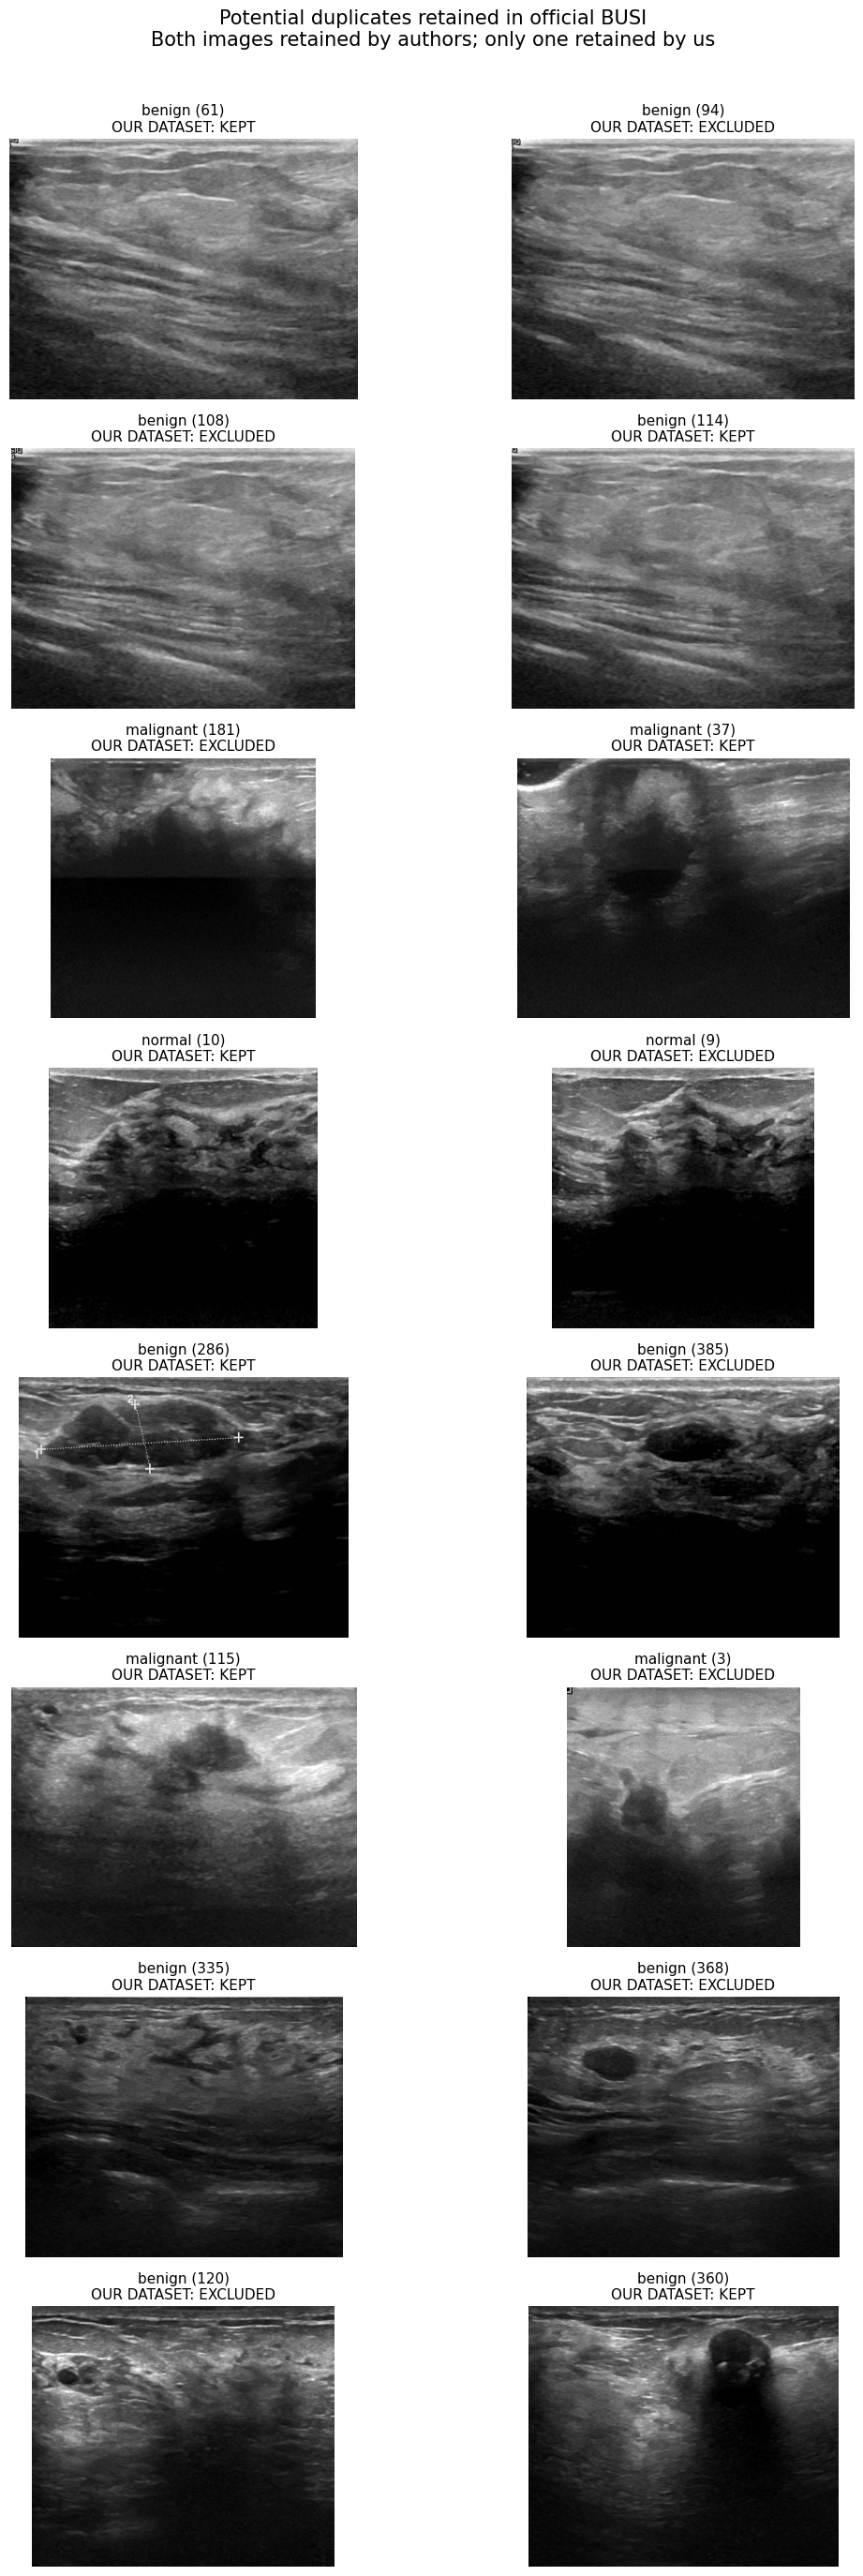


Figure saved: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/official_vs_ours/potential_duplicates_comparison.png
Candidate CSV saved in: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/official_vs_ours


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from collections import defaultdict
import hashlib
import itertools
import re

# ==========================================
# 1. Configuration
# ==========================================

ORIGINAL_ROOT = Path("/content/drive/MyDrive/BUSI")

SSIM_FILE = Path(
    "/content/drive/MyDrive/HybridResNet50_Reviewer_Results/"
    "audit/ssim023_original_all_pairs.csv"
)

OUTPUT_DIR = SSIM_FILE.parent / "official_vs_ours"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not SSIM_FILE.exists():
    raise FileNotFoundError(
        "256px SSIM audit is missing. Run STEP 4 first."
    )

# official_set and our_set come from your previous comparison cell.
assert len(official_set) == 450
assert len(our_set) == 450

# ==========================================
# 2. Index original BUSI images
# ==========================================

image_paths = {}

pattern = re.compile(
    r"^(normal|benign|malignant)\s*\((\d+)\)$",
    re.IGNORECASE
)

for path in ORIGINAL_ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in (".png", ".jpg", ".jpeg"):
        continue

    match = pattern.fullmatch(path.stem)

    if match:
        key = (match.group(1).lower(), int(match.group(2)))

        if key in image_paths:
            raise ValueError(f"Duplicate original filename key: {key}")

        image_paths[key] = path

print("Original images indexed:", len(image_paths))

missing = official_set - image_paths.keys()
if missing:
    raise ValueError(f"Missing original images: {list(missing)[:10]}")

# ==========================================
# 3. Load original SSIM audit
# ==========================================

pairs = pd.read_csv(SSIM_FILE)

def parse_key(value):
    match = re.search(
        r"BUSI_(normal|benign|malignant)_.*\((\d+)\)$",
        str(value),
        re.IGNORECASE
    )

    if not match:
        raise ValueError(f"Unrecognized image ID: {value}")

    return (match.group(1).lower(), int(match.group(2)))

pairs["key_a"] = pairs["image_id_a"].apply(parse_key)
pairs["key_b"] = pairs["image_id_b"].apply(parse_key)

pairs["official_a"] = pairs["key_a"].apply(
    lambda k: k in official_set
)
pairs["official_b"] = pairs["key_b"].apply(
    lambda k: k in official_set
)

pairs["ours_a"] = pairs["key_a"].apply(
    lambda k: k in our_set
)
pairs["ours_b"] = pairs["key_b"].apply(
    lambda k: k in our_set
)

pairs["same_class"] = (
    pairs["class_a"] == pairs["class_b"]
)

# ==========================================
# 4. Cases the official dataset retained
#    but our dataset split apart
# ==========================================

candidates = pairs[
    (pairs["official_a"]) &
    (pairs["official_b"]) &
    (pairs["ours_a"] != pairs["ours_b"])
].copy()

candidates = candidates.sort_values(
    "ssim", ascending=False
)

same_class = candidates[
    candidates["same_class"]
].copy()

cross_class = candidates[
    ~candidates["same_class"]
].copy()

print("\n========== COMPARISON ==========")
print("Officially retained pairs with one excluded by us:",
      len(candidates))
print("Same-class candidates:", len(same_class))
print("Cross-class candidates:", len(cross_class))

for threshold in (0.95, 0.90, 0.80, 0.70):
    count = (same_class["ssim"] >= threshold).sum()
    print(f"Same-class SSIM >= {threshold:.2f}: {count}")

candidates.to_csv(
    OUTPUT_DIR / "official_kept_ours_split.csv",
    index=False
)

print("\nTop 15 same-class candidates:")
print(
    same_class[
        ["image_id_a", "image_id_b", "ssim",
         "ours_a", "ours_b"]
    ].head(15).to_string(index=False)
)

print("\nTop 10 cross-class candidates:")
print(
    cross_class[
        ["image_id_a", "image_id_b", "ssim"]
    ].head(10).to_string(index=False)
)

# ==========================================
# 5. Check exact duplicate file hashes
#    across all 450 official images
# ==========================================

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

hash_groups = defaultdict(list)

for key in official_set:
    hash_groups[file_sha256(image_paths[key])].append(key)

exact_pairs = []

for group in hash_groups.values():
    if len(group) < 2:
        continue

    for a, b in itertools.combinations(group, 2):
        exact_pairs.append({
            "image_a": str(a),
            "image_b": str(b),
            "ours_kept_a": a in our_set,
            "ours_kept_b": b in our_set,
            "ours_kept_only_one":
                (a in our_set) != (b in our_set)
        })

exact_df = pd.DataFrame(exact_pairs)

print("\n========== EXACT FILE DUPLICATES ==========")
print("Identical-file pairs retained by authors:",
      len(exact_df))

if not exact_df.empty:
    print(exact_df.to_string(index=False))
    exact_df.to_csv(
        OUTPUT_DIR / "official_exact_duplicate_pairs.csv",
        index=False
    )

# ==========================================
# 6. Display highest-SSIM candidate pairs
#    at original resolution
# ==========================================

selected = []
used_images = set()

for row in same_class.itertuples(index=False):
    if row.key_a in used_images or row.key_b in used_images:
        continue

    selected.append(row)
    used_images.update([row.key_a, row.key_b])

    if len(selected) == 8:
        break

if not selected:
    print("\nNo matching same-class candidate pairs found.")
else:
    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(12, 3.5 * len(selected)),
        squeeze=False
    )

    for i, row in enumerate(selected):
        a = row.key_a
        b = row.key_b

        img_a = Image.open(image_paths[a]).convert("RGB")
        img_b = Image.open(image_paths[b]).convert("RGB")

        for ax, img, key in [
            (axes[i, 0], img_a, a),
            (axes[i, 1], img_b, b)
        ]:
            ax.imshow(img)
            ax.axis("off")

            status = (
                "OUR DATASET: KEPT"
                if key in our_set
                else "OUR DATASET: EXCLUDED"
            )

            ax.set_title(
                f"{key[0]} ({key[1]})\n{status}",
                fontsize=11
            )

        exact_hash = (
            file_sha256(image_paths[a]) ==
            file_sha256(image_paths[b])
        )

        axes[i, 0].set_ylabel(
            f"SSIM: {row.ssim:.4f}\n"
            f"Exact file: {exact_hash}",
            fontsize=11
        )

    fig.suptitle(
        "Potential duplicates retained in official BUSI\n"
        "Both images retained by authors; only one retained by us",
        fontsize=15
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    figure_path = (
        OUTPUT_DIR / "potential_duplicates_comparison.png"
    )

    plt.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print("\nFigure saved:", figure_path)
    print("Candidate CSV saved in:", OUTPUT_DIR)


Original BUSI records: 780


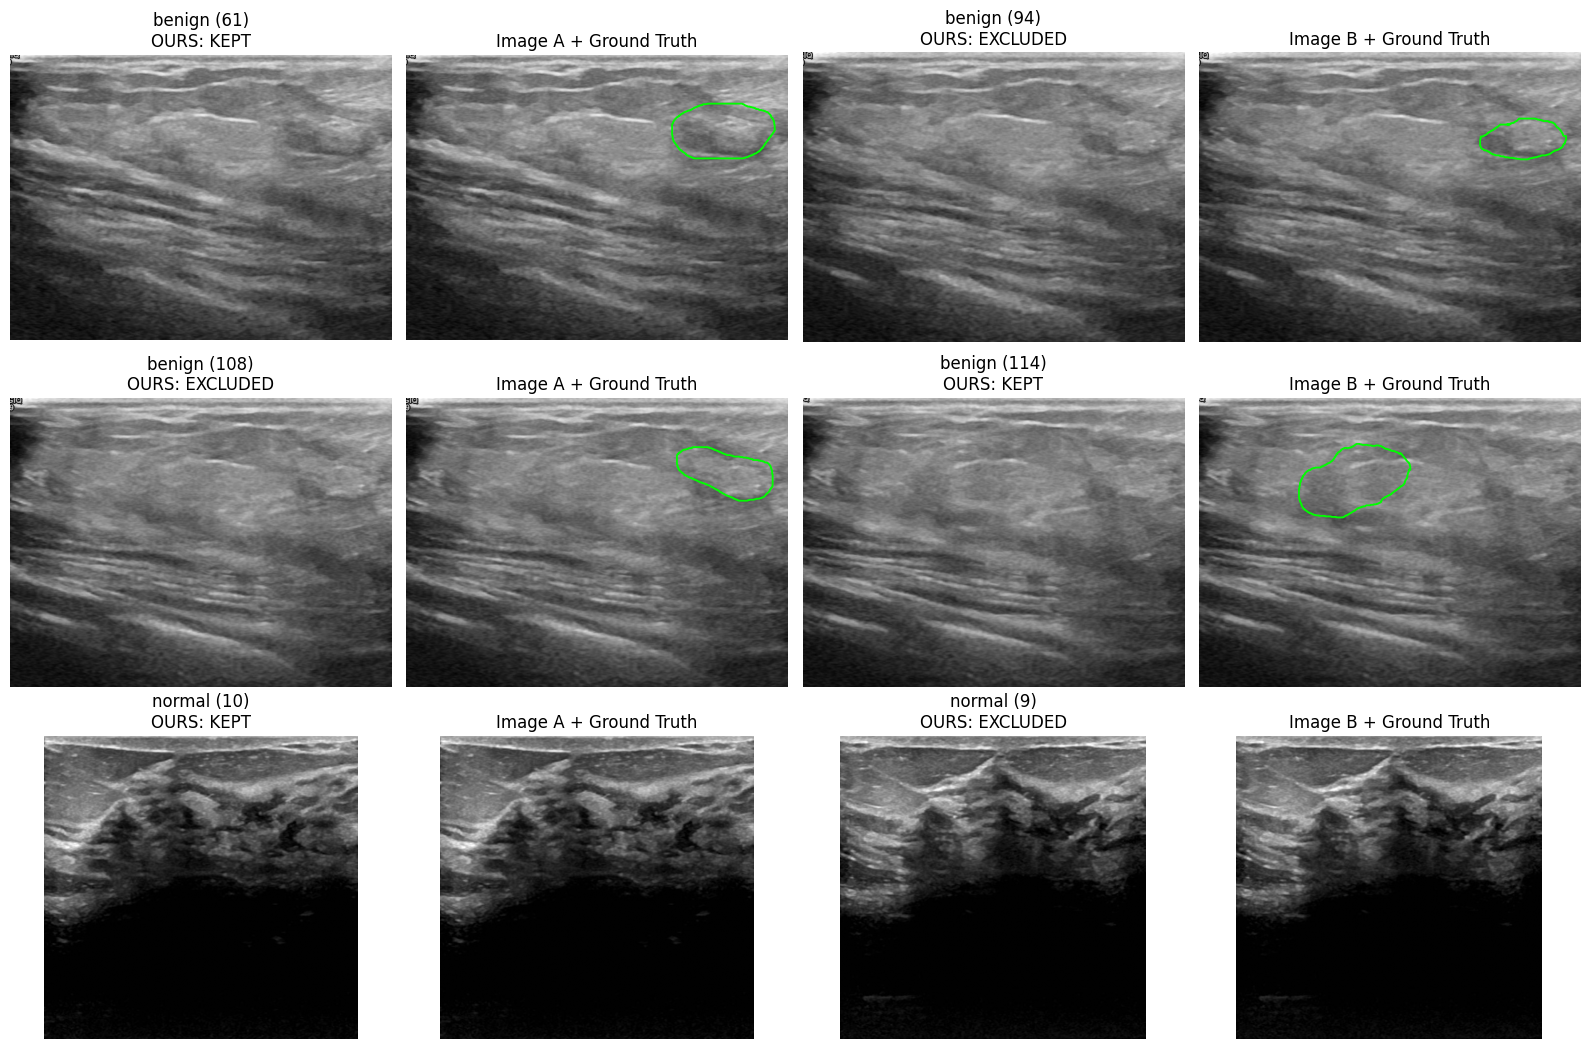

Figure saved: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/pair_verification/three_suspected_duplicates.png


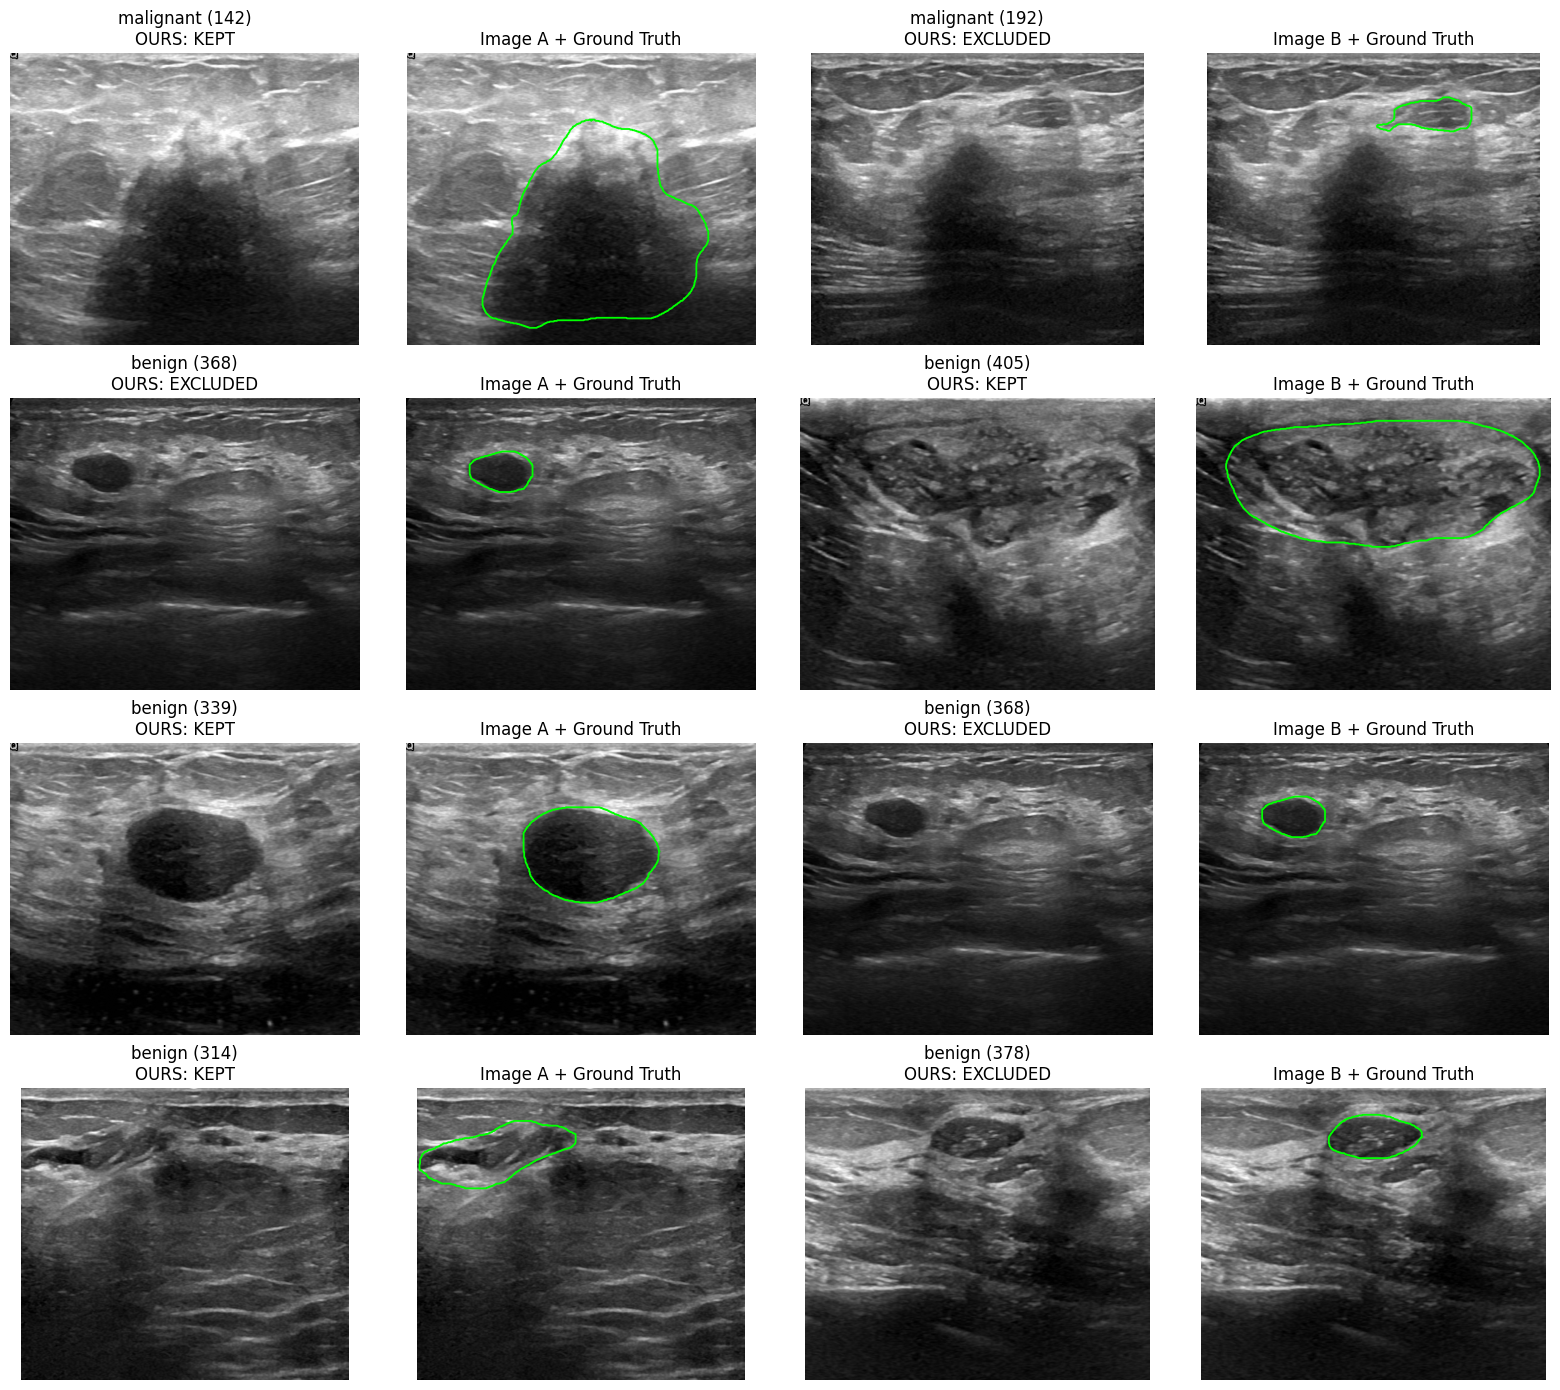

Figure saved: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/pair_verification/lower_ssim_candidates.png

========== VERIFICATION REPORT ==========
        image_a         image_b  ssim_256  same_sha256  same_original_grayscale_pixels
    benign (61)     benign (94)  0.587397        False                           False
   benign (108)    benign (114)  0.572607        False                           False
    normal (10)      normal (9)  0.496225        False                           False
malignant (142) malignant (192)  0.267618        False                           False
   benign (368)    benign (405)  0.259694        False                           False
   benign (339)    benign (368)  0.238762        False                           False
   benign (314)    benign (378)  0.241650        False                           False

Verification table saved: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/pair_verification/manual_verification.csv
Total pairs:

In [ ]:

# ====================================================
# REVIEWER 8 - IMAGE AND MASK DUPLICATE VERIFICATION
# Read-only: no images or masks are modified
# ====================================================

import re
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from skimage.metrics import structural_similarity

ROOT = Path(
    "/content/drive/MyDrive/HybridResNet50_Reviewer_Results"
)

OUT = ROOT / "audit" / "pair_verification"
OUT.mkdir(parents=True, exist_ok=True)

if "official_set" not in globals() or "our_set" not in globals():
    raise RuntimeError(
        "Run the previous official-versus-ours comparison cell first."
    )

# ----------------------------------------------------
# 1. Load saved original BUSI inventory
# ----------------------------------------------------

inventory = pd.read_csv(ROOT / "audit" / "inventory.csv")

inventory = inventory[
    inventory["source"] == "original_busi"
].copy()

CLASS_NAMES = {0: "normal", 1: "benign", 2: "malignant"}

def record_key(row):
    cls = CLASS_NAMES[int(row.label)]
    match = re.search(
        r"\((\d+)\)",
        Path(row.image_path).stem
    )
    if not match:
        raise ValueError(f"Unknown filename: {row.image_path}")
    return cls, int(match.group(1))

records = {
    record_key(row): row
    for row in inventory.itertuples(index=False)
}

print("Original BUSI records:", len(records))

if len(records) != 780:
    raise ValueError("Expected 780 original BUSI images.")

# ----------------------------------------------------
# 2. Image and mask loading
# ----------------------------------------------------

cache = {}

def load_sample(key):
    if key in cache:
        return cache[key]

    row = records[key]

    with Image.open(row.image_path) as im:
        gray = np.asarray(im.convert("L"))
        gray256 = np.asarray(
            im.convert("L").resize(
                (256, 256),
                Image.Resampling.BILINEAR
            ),
            dtype=np.float32
        ) / 255.0

    with Image.open(row.mask_path) as im:
        mask = np.asarray(im.convert("L")) > 0

    if mask.shape != gray.shape:
        raise ValueError(f"Mask alignment mismatch: {key}")

    cache[key] = (gray, gray256, mask)
    return cache[key]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

# ----------------------------------------------------
# 3. The three strongest suspected pairs
# ----------------------------------------------------

priority_pairs = [
    (("benign", 61), ("benign", 94)),
    (("benign", 108), ("benign", 114)),
    (("normal", 10), ("normal", 9)),
]

# ----------------------------------------------------
# 4. Visualize and record each pair
# ----------------------------------------------------

results = []

def inspect_pairs(pair_list, filename, category):

    if not pair_list:
        print("No pairs found for:", category)
        return

    fig, axes = plt.subplots(
        len(pair_list), 4,
        figsize=(16, 3.5 * len(pair_list)),
        squeeze=False
    )

    for i, (a, b) in enumerate(pair_list):

        img_a, small_a, mask_a = load_sample(a)
        img_b, small_b, mask_b = load_sample(b)

        score = structural_similarity(
            small_a, small_b,
            data_range=1.0
        )

        hash_equal = (
            sha256_file(records[a].image_path)
            == sha256_file(records[b].image_path)
        )

        same_pixels = (
            img_a.shape == img_b.shape
            and np.array_equal(img_a, img_b)
        )

        images = [img_a, img_a, img_b, img_b]

        for j in range(4):
            axes[i, j].imshow(images[j], cmap="gray")
            axes[i, j].axis("off")

        # Ground truth masks are shown on their own images.
        if mask_a.any():
            axes[i, 1].contour(
                mask_a.astype(float),
                levels=[0.5],
                colors=["lime"],
                linewidths=1.3
            )

        if mask_b.any():
            axes[i, 3].contour(
                mask_b.astype(float),
                levels=[0.5],
                colors=["lime"],
                linewidths=1.3
            )

        def status(key):
            return "OURS: KEPT" if key in our_set else "OURS: EXCLUDED"

        axes[i, 0].set_title(
            f"{a[0]} ({a[1]})\n{status(a)}"
        )
        axes[i, 1].set_title("Image A + Ground Truth")
        axes[i, 2].set_title(
            f"{b[0]} ({b[1]})\n{status(b)}"
        )
        axes[i, 3].set_title("Image B + Ground Truth")

        axes[i, 0].set_ylabel(
            f"SSIM256 = {score:.4f}\n"
            f"Exact file = {hash_equal}",
            fontsize=10
        )

        results.append({
            "category": category,
            "image_a": f"{a[0]} ({a[1]})",
            "image_b": f"{b[0]} ({b[1]})",
            "ssim_256": round(float(score), 6),
            "same_sha256": hash_equal,
            "same_original_grayscale_pixels": same_pixels,
            "mask_pixels_a": int(mask_a.sum()),
            "mask_pixels_b": int(mask_b.sum()),
            "image_size_a": str(img_a.shape),
            "image_size_b": str(img_b.shape),
            "manual_decision": "",
            "same_anatomical_landmarks": "",
            "annotation_consistent": "",
            "reviewer_notes": ""
        })

    plt.tight_layout()

    filepath = OUT / filename
    plt.savefig(filepath, dpi=200, bbox_inches="tight")
    plt.show()

    print("Figure saved:", filepath)

inspect_pairs(
    priority_pairs,
    "three_suspected_duplicates.png",
    "high_priority"
)

# ----------------------------------------------------
# 5. Select lower-SSIM candidates
# Both officially retained, only one retained by us
# ----------------------------------------------------

pairs_df = pd.read_csv(
    ROOT / "audit" / "ssim023_original_all_pairs.csv"
)

def parse_uid(value):
    match = re.search(
        r"^BUSI_(normal|benign|malignant)_.+?\((\d+)\)$",
        str(value),
        re.IGNORECASE
    )
    if not match:
        raise ValueError(f"Unexpected UID: {value}")
    return match.group(1).lower(), int(match.group(2))

pairs_df["key_a"] = pairs_df["image_id_a"].map(parse_uid)
pairs_df["key_b"] = pairs_df["image_id_b"].map(parse_uid)

def matches_comparison(row):
    a, b = row.key_a, row.key_b
    return (
        a[0] == b[0]
        and a in official_set
        and b in official_set
        and ((a in our_set) != (b in our_set))
    )

low = pairs_df[
    pairs_df["ssim"].between(0.23, 0.35)
].copy()

low = low[
    low.apply(matches_comparison, axis=1)
]

# Reproducible random sample
N_LOW = min(4, len(low))

if N_LOW:
    selected_low = low.sample(
        n=N_LOW,
        random_state=42
    )

    low_pairs = list(zip(
        selected_low["key_a"],
        selected_low["key_b"]
    ))

    inspect_pairs(
        low_pairs,
        "lower_ssim_candidates.png",
        "lower_similarity"
    )

# ----------------------------------------------------
# 6. Export manual verification table
# ----------------------------------------------------

report = pd.DataFrame(results)

report_path = OUT / "manual_verification.csv"
report.to_csv(report_path, index=False)

print("\n========== VERIFICATION REPORT ==========")

print(report[
    [
        "image_a",
        "image_b",
        "ssim_256",
        "same_sha256",
        "same_original_grayscale_pixels"
    ]
].to_string(index=False))

print("\nVerification table saved:", report_path)
print("Total pairs:", len(report))


In [ ]:

import pandas as pd
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/HybridResNet50_Reviewer_Results/"
    "audit/pair_verification"
)

df = pd.read_csv(folder / "manual_verification.csv")

assessments = {
    ("benign (61)", "benign (94)"): "probable_same_acquisition",
    ("benign (108)", "benign (114)"): "probable_same_acquisition",
    ("normal (10)", "normal (9)"): "probable_same_acquisition",
    ("malignant (142)", "malignant (192)"): "likely_distinct",
    ("benign (368)", "benign (405)"): "likely_distinct",
    ("benign (339)", "benign (368)"): "likely_distinct",
    ("benign (314)", "benign (378)"): "likely_distinct",
}

df["preliminary_visual_assessment"] = df.apply(
    lambda r: assessments.get(
        (r["image_a"], r["image_b"]), "unreviewed"
    ),
    axis=1
)

for threshold in (0.20, 0.23, 0.30):
    df[f"flagged_at_{threshold:.2f}"] = (
        df["ssim_256"] >= threshold
    )

output = folder / "preliminary_threshold_review.csv"
df.to_csv(output, index=False)

print(df[
    [
        "image_a", "image_b", "ssim_256",
        "preliminary_visual_assessment",
        "flagged_at_0.20", "flagged_at_0.23",
        "flagged_at_0.30"
    ]
].to_string(index=False))

print("\nSaved:", output)
print("These labels are preliminary, not verified ground truth.")


        image_a         image_b  ssim_256 preliminary_visual_assessment  flagged_at_0.20  flagged_at_0.23  flagged_at_0.30
    benign (61)     benign (94)  0.587397     probable_same_acquisition             True             True             True
   benign (108)    benign (114)  0.572607     probable_same_acquisition             True             True             True
    normal (10)      normal (9)  0.496225     probable_same_acquisition             True             True             True
malignant (142) malignant (192)  0.267618               likely_distinct             True             True            False
   benign (368)    benign (405)  0.259694               likely_distinct             True             True            False
   benign (339)    benign (368)  0.238762               likely_distinct             True             True            False
   benign (314)    benign (378)  0.241650               likely_distinct             True             True            False

Saved: /content

In [ ]:

# STEP 2: Validate original curated BUSI manifest
# READ-ONLY: Does not modify images, masks, or CSV.

df = original_curated_list.copy()

EXPECTED_COUNTS = {
    "normal": 64,
    "benign": 222,
    "malignant": 164
}

df["class_clean"] = df["class"].astype(str).str.strip().str.lower()

# 1. Check class distribution
class_counts = (
    df["class_clean"]
    .value_counts()
    .reindex(EXPECTED_COUNTS.keys(), fill_value=0)
)

# 2. Check missing files
missing_images = [
    p for p in df["image"]
    if not Path(str(p)).is_file()
]

missing_masks = [
    p for p in df["mask"]
    if not Path(str(p)).is_file()
]

# 3. Check duplicate records
duplicate_ids = df[df["id"].duplicated(keep=False)]
duplicate_images = df[df["image"].duplicated(keep=False)]
duplicate_masks = df[df["mask"].duplicated(keep=False)]

# 4. Check class and image filename consistency
class_mismatches = []

for row in df.itertuples(index=False):
    image_name = Path(str(row.image)).stem.lower()

    if not image_name.startswith(row.class_clean):
        class_mismatches.append(row.image)

# 5. Check image-mask dimensions
geometry_mismatches = []

for row in tqdm(df.itertuples(index=False), total=len(df),
                desc="Checking image-mask geometry"):

    if not Path(str(row.image)).is_file():
        continue

    if not Path(str(row.mask)).is_file():
        continue

    try:
        with Image.open(row.image) as img:
            image_size = img.size

        with Image.open(row.mask) as mask:
            mask_size = mask.size

        if image_size != mask_size:
            geometry_mismatches.append({
                "image": row.image,
                "mask": row.mask,
                "image_size": image_size,
                "mask_size": mask_size
            })

    except Exception as e:
        geometry_mismatches.append({
            "image": row.image,
            "mask": row.mask,
            "error": str(e)
        })

# 6. Print audit report
print("\n========== CURATED BUSI VALIDATION ==========")

print("Total records:", len(df))
print("Unique IDs:", df["id"].nunique())
print("Unique images:", df["image"].nunique())
print("Unique masks:", df["mask"].nunique())

print("\nClass distribution:")
print(class_counts.to_string())

print("\nMissing images:", len(missing_images))
print("Missing masks:", len(missing_masks))

print("Duplicate IDs:", len(duplicate_ids))
print("Duplicate images:", len(duplicate_images))
print("Duplicate masks:", len(duplicate_masks))

print("Class-name mismatches:", len(class_mismatches))
print("Image-mask geometry mismatches:", len(geometry_mismatches))

if geometry_mismatches:
    print("\nGeometry mismatch examples:")
    print(geometry_mismatches[:10])

if missing_images:
    print("\nMissing image examples:", missing_images[:10])

if missing_masks:
    print("\nMissing mask examples:", missing_masks[:10])

# 7. Final validation
valid = (
    len(df) == 450
    and class_counts.to_dict() == EXPECTED_COUNTS
    and len(missing_images) == 0
    and len(missing_masks) == 0
    and len(duplicate_ids) == 0
    and len(duplicate_images) == 0
    and len(duplicate_masks) == 0
    and len(class_mismatches) == 0
)

print("\n============================================")

if valid:
    print("450 IMAGE MANIFEST: VERIFIED")
else:
    print("VALIDATION FAILED: INVESTIGATION REQUIRED")

print("============================================")


Checking image-mask geometry:   0%|          | 0/450 [00:00<?, ?it/s]


========== CURATED BUSI VALIDATION ==========
Total records: 450
Unique IDs: 450
Unique images: 450
Unique masks: 450

Class distribution:
class_clean
normal        64
benign       222
malignant    164

Missing images: 0
Missing masks: 0
Duplicate IDs: 0
Duplicate images: 0
Duplicate masks: 0
Class-name mismatches: 0
Image-mask geometry mismatches: 0

450 IMAGE MANIFEST: VERIFIED


## Phase 1 — Dataset auditing, SSIM sensitivity, and frozen leakage-aware splits

In [ ]:

# STEP 3: Trace curated 450 images back to original BUSI 780
# READ-ONLY: No dataset modification.

import pandas as pd
from pathlib import Path

CLASS_NAMES = {
    0: "normal",
    1: "benign",
    2: "malignant"
}

# Load previously saved original dataset inventory
inventory_path = ROOT / "audit" / "inventory.csv"

if not inventory_path.exists():
    raise FileNotFoundError(
        "Inventory not found. Run PHASE 1 / CELL 03 first."
    )

original_df = pd.read_csv(inventory_path)

original_df = original_df[
    original_df["source"] == "original_busi"
].copy()

print("Original BUSI images:", len(original_df))

curated_df = original_curated_list.copy()

# Normalize filenames and class labels
original_df["image_name"] = original_df["image_path"].apply(
    lambda x: Path(x).name
)

original_df["class_clean"] = original_df["label"].map(CLASS_NAMES)

curated_df["image_name"] = curated_df["image"].apply(
    lambda x: Path(x).name
)

curated_df["class_clean"] = (
    curated_df["class"].astype(str).str.strip().str.lower()
)

# Check duplicate keys
original_duplicates = original_df.duplicated(
    ["image_name", "class_clean"]
).sum()

curated_duplicates = curated_df.duplicated(
    ["image_name", "class_clean"]
).sum()

# Match curated records with original BUSI
curated_keys = set(zip(
    curated_df["image_name"],
    curated_df["class_clean"]
))

original_df["is_curated"] = [
    (name, cls) in curated_keys
    for name, cls in zip(
        original_df["image_name"],
        original_df["class_clean"]
    )
]

# Find selected images that cannot be traced to original BUSI
original_keys = set(zip(
    original_df["image_name"],
    original_df["class_clean"]
))

unmatched_curated = curated_df[
    ~curated_df.apply(
        lambda r: (r["image_name"], r["class_clean"]) in original_keys,
        axis=1
    )
]

# Separate retained and removed images
retained = original_df[original_df["is_curated"]].copy()
removed = original_df[~original_df["is_curated"]].copy()

# Class distributions
retained_counts = (
    retained["class_clean"].value_counts()
    .reindex(["normal", "benign", "malignant"], fill_value=0)
)

removed_counts = (
    removed["class_clean"].value_counts()
    .reindex(["normal", "benign", "malignant"], fill_value=0)
)

# Save audit reports
audit_columns = [
    "uid", "image_name", "class_clean",
    "is_curated", "image_path", "mask_path"
]

original_df[audit_columns].to_csv(
    ROOT / "audit" / "original_busi_curated_membership.csv",
    index=False
)

removed[audit_columns].to_csv(
    ROOT / "audit" / "original_busi_removed_330.csv",
    index=False
)

# Print results
print("\n========== ORIGINAL BUSI CURATION AUDIT ==========")

print("Original BUSI:", len(original_df))
print("Curated BUSI:", len(retained))
print("Removed BUSI:", len(removed))

print("\nRetained class distribution:")
print(retained_counts.to_string())

print("\nRemoved class distribution:")
print(removed_counts.to_string())

print("\nDuplicate original keys:", original_duplicates)
print("Duplicate curated keys:", curated_duplicates)
print("Unmatched curated images:", len(unmatched_curated))

print("\nExpected retained: 450")
print("Expected removed: 330")

if len(unmatched_curated):
    print("\nUnmatched examples:")
    print(unmatched_curated[
        ["image_name", "class_clean"]
    ].head(10).to_string(index=False))

print("\nMembership report:",
      ROOT / "audit" / "original_busi_curated_membership.csv")

print("Removed images report:",
      ROOT / "audit" / "original_busi_removed_330.csv")

print("\n==================================================")

if (
    len(original_df) == 780
    and len(retained) == 450
    and len(removed) == 330
    and len(unmatched_curated) == 0
    and original_duplicates == 0
    and curated_duplicates == 0
):
    print("SUCCESS: All 450 curated images traced to original BUSI.")
else:
    print("WARNING: Membership discrepancy detected.")


Original BUSI images: 780

========== ORIGINAL BUSI CURATION AUDIT ==========
Original BUSI: 780
Curated BUSI: 450
Removed BUSI: 330

Retained class distribution:
class_clean
normal        64
benign       222
malignant    164

Removed class distribution:
class_clean
normal        69
benign       215
malignant     46

Duplicate original keys: 0
Duplicate curated keys: 0
Unmatched curated images: 0

Expected retained: 450
Expected removed: 330

Membership report: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/original_busi_curated_membership.csv
Removed images report: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/original_busi_removed_330.csv

SUCCESS: All 450 curated images traced to original BUSI.


In [ ]:

# Locate original BUSI image masks directly.
# READ-ONLY: No images or masks are modified.

import re
from collections import defaultdict
from pathlib import Path

busi_root = Path(CFG.ORIGINAL_BUSI_ROOT)

image_root = (
    busi_root / "images"
    if (busi_root / "images").is_dir()
    else busi_root
)

mask_root = (
    busi_root / "masks"
    if (busi_root / "masks").is_dir()
    else busi_root
)

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tiff", ".tif"
}

# Find original raw mask files
mask_files = sorted(
    p for p in mask_root.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and re.search(r"_mask(?:_\d+)?$", p.stem, re.I)
)

# Build lookup by image basename
mask_lookup = defaultdict(list)

for mask_path in mask_files:
    base = re.sub(
        r"_mask(?:_\d+)?$",
        "",
        mask_path.stem,
        flags=re.I
    ).lower()

    mask_lookup[(base, mask_path.parent.name.lower())].append(mask_path)
    mask_lookup[(base, "*")].append(mask_path)

raw_masks_by_image = {}

for row in source_df.itertuples(index=False):
    image_path = Path(row.image_path)
    image_key = image_path.stem.lower()

    candidates = mask_lookup.get(
        (image_key, image_path.parent.name.lower()),
        []
    )

    if not candidates:
        candidates = mask_lookup.get(
            (image_key, "*"), []
        )

    # Support BUSI filename mapping
    if not candidates:
        match = re.fullmatch(
            r"(normal|benign|malignant)\s*\((\d+)\)",
            image_path.stem,
            re.I
        )

        if match:
            expected_class = CLASS_NAMES[int(row.label)]

            if match.group(1).lower() == expected_class:
                alternative_key = (
                    f"busi_{expected_class}_{match.group(2)}"
                )
                candidates = mask_lookup.get(
                    (alternative_key, "*"), []
                )

    raw_masks_by_image[
        str(image_path.resolve())
    ] = sorted(set(candidates))

print("Original images:", len(raw_masks_by_image))
print("Raw mask files found:", len(mask_files))
print("Mask lookup completed.")


NameError: name 'source_df' is not defined

In [ ]:

# STEP 4: Reconstruct original SSIM 0.23 selection BEFORE class balancing
# READ-ONLY: Does not modify original or curated datasets.
# Uses the original notebook's 256x256 grayscale SSIM protocol.

from collections import defaultdict, Counter
from skimage.metrics import structural_similarity

SSIM_THRESHOLD_AUDIT = 0.23

# Use the original BUSI dataset loaded in STEP 3
source_df = original_df.copy().reset_index(drop=True)

# Verify dataset
print("Original BUSI images:", len(source_df))

assert len(source_df) == 780, (
    f"Expected 780 images, found {len(source_df)}"
)

curated_ids = set(original_curated_list["id"].astype(str).str.strip())



def get_original_mask(image_path):
    parent = Path(image_path).parent
    base = Path(image_path).stem

    patterns = [
        f"{base} mask.png",
        f"{base}_mask.png",
        f"{base} mask_1.png",
        f"{base}_mask_1.png",
        f"{base} mask 1.png",
        f"{base} mask(1).png",
        f"{base}_mask(1).png",
        f"{base}_mask_2.png",
    ]

    for name in patterns:
        candidate = parent / name
        if candidate.is_file():
            return candidate

    for name in os.listdir(parent):
        if base in name and "mask" in name.lower():
            if name != Path(image_path).name:
                return parent / name

    candidates = raw_masks_by_image.get(
        str(Path(image_path).resolve()), []
    )

    return candidates[0] if candidates else None


def original_mask_area(mask_path):
    if mask_path is None:
        return 0

    try:
        with Image.open(mask_path) as im:
            return int(
                (np.asarray(im.convert("L")) > 0).sum()
            )
    except Exception:
        return 0


records = []

for row in source_df.itertuples(index=False):
    cls = CLASS_NAMES[int(row.label)]
    image_path = str(row.image_path)
    mask_path = get_original_mask(image_path)

    records.append({
        "id": f"BUSI_{cls}_{Path(image_path).stem}",
        "image_path": image_path,
        "mask_path": str(mask_path) if mask_path else None,
        "class": cls,
        "mask_area": original_mask_area(mask_path)
    })

# Prepare grayscale images using the original curation protocol.
gray_images = []

for r in tqdm(records, desc="Preparing SSIM images"):
    with Image.open(r["image_path"]) as im:
        arr = np.asarray(
            im.convert("L").resize(
                (256, 256), Image.Resampling.BILINEAR
            ),
            dtype=np.float32
        ) / 255.0

    gray_images.append(arr)

# Calculate ALL cross-class and within-class pairs.
N = len(records)
edges = []

for i in tqdm(range(N), desc="All-class SSIM comparisons"):
    for j in range(i + 1, N):
        score = structural_similarity(
            gray_images[i],
            gray_images[j],
            data_range=1.0
        )

        if score >= SSIM_THRESHOLD_AUDIT:
            edges.append((i, j, float(score)))

print("\nSSIM candidate pairs:", len(edges))

# Union-Find
parent = list(range(N))

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union_nodes(a, b):
    ra, rb = find_root(a), find_root(b)
    if ra != rb:
        parent[rb] = ra

for i, j, score in edges:
    union_nodes(i, j)

groups = defaultdict(list)

for i in range(N):
    groups[find_root(i)].append(i)

groups = list(groups.values())

# Select representatives using original notebook's mask-area rule.
priority_mask = {
    "malignant": 0,
    "benign": 1,
    "normal": 2
}

priority_empty = {
    "benign": 0,
    "malignant": 1,
    "normal": 2
}

representative_indices = set()
group_rows = []

for members in groups:

    max_area = max(records[i]["mask_area"] for i in members)

    if max_area > 0:
        candidates = [
            i for i in members
            if records[i]["mask_path"] is not None
            and records[i]["mask_area"] == max_area
        ]

        rep_idx = min(
            candidates,
            key=lambda i: (
                priority_mask[records[i]["class"]],
                records[i]["id"]
            )
        )
    else:
        rep_idx = min(
            members,
            key=lambda i: (
                priority_empty[records[i]["class"]],
                records[i]["id"]
            )
        )

    representative_indices.add(rep_idx)

    group_id = "G_" + sha_text(
        "|".join(sorted(records[i]["id"] for i in members))
    )[:16]

    curated_members = [
        i for i in members
        if records[i]["id"] in curated_ids
    ]

    for i in members:
        group_rows.append({
            "group_id": group_id,
            "id": records[i]["id"],
            "class": records[i]["class"],
            "mask_area": records[i]["mask_area"],
            "group_size": len(members),
            "is_representative": i == rep_idx,
            "is_in_final_450": records[i]["id"] in curated_ids,
            "final_450_members_in_group": len(curated_members)
        })

# Compare natural representatives with the existing 450 manifest.
all_ids = {r["id"] for r in records}

representative_ids = {
    records[i]["id"] for i in representative_indices
}

matched_curated = curated_ids & all_ids

added_ids = matched_curated - representative_ids
omitted_ids = representative_ids - matched_curated

def class_distribution(ids):
    return dict(Counter(
        next(r["class"] for r in records if r["id"] == uid)
        for uid in ids
    ))

# Detect multiple final curated images in the same SSIM component.
multi_selected_groups = [
    g for g in groups
    if sum(records[i]["id"] in curated_ids for i in g) > 1
]

representative_counts = Counter(
    records[i]["class"] for i in representative_indices
)

final_counts = Counter(
    r["class"] for r in records
    if r["id"] in matched_curated
)

# Export reports.
pd.DataFrame(group_rows).to_csv(
    ROOT / "audit" / "ssim023_original_group_audit.csv",
    index=False
)

pd.DataFrame([
    {
        "image_id_a": records[i]["id"],
        "image_id_b": records[j]["id"],
        "class_a": records[i]["class"],
        "class_b": records[j]["class"],
        "ssim": score
    }
    for i, j, score in edges
]).to_csv(
    ROOT / "audit" / "ssim023_original_all_pairs.csv",
    index=False
)

comparison = []

for r in records:
    comparison.append({
        "id": r["id"],
        "class": r["class"],
        "is_original_representative": r["id"] in representative_ids,
        "is_in_final_450": r["id"] in curated_ids,
        "mask_area": r["mask_area"]
    })

pd.DataFrame(comparison).to_csv(
    ROOT / "audit" / "ssim023_representative_comparison.csv",
    index=False
)

# Final report.
print("\n========== ORIGINAL SSIM RECONSTRUCTION ==========")

print("Original images:", N)
print("SSIM threshold:", SSIM_THRESHOLD_AUDIT)
print("Qualifying pairs:", len(edges))
print("Connected components:", len(groups))
print("Non-singleton groups:", sum(len(g) > 1 for g in groups))

print("\nBefore class balancing:")
print("Representatives:", len(representative_indices))
print(dict(representative_counts))

print("\nExisting curated manifest:")
print("Images:", len(matched_curated))
print(dict(final_counts))

print("\nDifference from SSIM representatives:")
print("Added/reintroduced images:", len(added_ids))
print(dict(class_distribution(added_ids)))

print("Removed representatives:", len(omitted_ids))
print(dict(class_distribution(omitted_ids)))

print("\nFinal curated images belonging to groups with multiple selected members:",
      sum(len(g) for g in multi_selected_groups))

print("Number of such groups:", len(multi_selected_groups))

print("\nUnmatched manifest IDs:", len(curated_ids - all_ids))

print("\nReports saved in:", ROOT / "audit")
print("=================================================")


In [ ]:

# LOAD SAVED CELL 03 RESULTS FROM GOOGLE DRIVE
# Run after PHASE 0 / CELL 01 and CELL 02.

import pandas as pd
import hashlib
from pathlib import Path

CLASS_NAMES = {0: "normal", 1: "benign", 2: "malignant"}

inventory_file = ROOT / "audit" / "inventory.csv"

if not inventory_file.exists():
    raise FileNotFoundError(
        f"Saved inventory not found: {inventory_file}"
    )

# Restore the original manifest DataFrame
manifest = pd.read_csv(
    inventory_file,
    keep_default_na=False
)

manifest["label"] = manifest["label"].astype(int)
manifest["lesion_pixels"] = manifest["lesion_pixels"].astype(int)

# Required helper for PHASE 1 / CELL 05
def file_sha256(path, buf_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(buf_size), b""):
            digest.update(block)
    return digest.hexdigest()

# Verify generated masks still exist
missing_masks = [
    p for p in manifest["mask_path"]
    if not Path(p).is_file()
]

if missing_masks:
    raise FileNotFoundError(
        f"{len(missing_masks)} generated masks are missing. "
        f"Example: {missing_masks[0]}"
    )

print("Saved inventory loaded successfully!")
print("Total images:", len(manifest))
print()
print(pd.crosstab(
    manifest["source"],
    manifest["label"]
).rename(columns=CLASS_NAMES))
print()
print("Ready to run PHASE 1 / CELL 05")


In [ ]:
# # PHASE 1 / CELL 03 - DATASET INVENTORY
# # Safe pairing and mask validation: never modify the source images/masks.
# # Requires CFG and ROOT from CELL 02 and standard Python libraries below.

# from pathlib import Path
# from collections import defaultdict
# import hashlib
# import re
# import numpy as np
# import pandas as pd
# from PIL import Image

# CLASS_NAMES = {0: 'normal', 1: 'benign', 2: 'malignant'}
# CLASS_IDS = {name: idx for idx, name in CLASS_NAMES.items()}
# IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.tif'}

# # Only put offsets here after checking image + mask overlays.
# # CHCO_000.png: 614x606 image; 856x606 mask; center candidate = (856-614)//2 = 121.
# # Keep this entry only if you accept the previously inspected overlay.
# UCLM_REVIEWED_CROP_OFFSETS = {
#     'CHCO_000.png': 121,  # Provisional: overlay visually reviewed; confirm if uncertain.
# }

# # Optional verified 2-D crops: filename -> (left_px, top_px).
# # Use only after verifying the mask aligns with the image, e.g. for HESN.
# # These override the single-axis crop offsets above.
# UCLM_REVIEWED_CROP_COORDS = {}

# UCLM_ACCEPTED_STATUSES = frozenset({
#     'same_size', 'reviewed_crop', 'empty_normal_mask'
# })

# AUDIT_DIR = Path(ROOT) / 'audit'
# MASK_DIR = Path(ROOT) / 'generated_masks'
# AUDIT_DIR.mkdir(parents=True, exist_ok=True)
# MASK_DIR.mkdir(parents=True, exist_ok=True)
# BINARY_MASK_RESIZE_AUDIT = []


# def sha_text(text):
#     return hashlib.sha256(str(text).encode('utf-8')).hexdigest()


# def file_sha256(path, buf_size=1024 * 1024):
#     digest = hashlib.sha256()
#     with open(path, 'rb') as fh:
#         while True:
#             block = fh.read(buf_size)
#             if not block:
#                 break
#             digest.update(block)
#     return digest.hexdigest()


# def label_from_image_path(path):
#     path = Path(path)
#     for token in (path.stem.lower(), path.parent.name.lower()):
#         for cls, idx in CLASS_IDS.items():
#             if re.search(r'(?<![a-z])' + cls + r'(?![a-z])', token):
#                 return idx
#     return None


# def read_mask_as_binary(path, image_size=None):
#     with Image.open(path) as im:
#         if image_size is not None and im.size != image_size:
#             # Preserve the existing BUSI/B2 behavior while recording ALL resizes.
#             BINARY_MASK_RESIZE_AUDIT.append({
#                 'mask_path': str(path),
#                 'original_size': str(im.size),
#                 'target_size': str(image_size),
#                 'method': 'nearest_neighbor',
#                 'review_status': 'geometry_not_verified',
#             })
#             im = im.resize(image_size, Image.Resampling.NEAREST)
#         raw = np.asarray(im)
#     if raw.ndim == 3:
#         return raw[..., :3].max(axis=2) > 0
#     return raw > 0


# def find_uclm_mask(image_path, mask_dir):
#     image_path, mask_dir = Path(image_path), Path(mask_dir)
#     # Exact same filename is preferred; the (1) variant is a known explicit alias.
#     alias = re.sub(r' \(1\)(?=\.)', '', image_path.name)
#     for name in dict.fromkeys((image_path.name, alias)):
#         candidate = mask_dir / name
#         if candidate.is_file():
#             return candidate
#     return None


# def align_uclm_mask(image_path, mask_path, image_size):
#     """Return pixel-aligned RGB annotation; never interpolate a nonempty mask.

#     A strictly all-black annotation is valid at any resolution because there
#     are no foreground coordinates to register.
#     Nonempty mismatched masks require an explicitly reviewed crop window.
#     """
#     image_path, mask_path = Path(image_path), Path(mask_path)
#     iw, ih = image_size

#     with Image.open(mask_path) as im:
#         mw, mh = im.size
#         raw = np.asarray(im.convert('RGB'))

#     if (mw, mh) == (iw, ih):
#         return raw

#     if not np.any(raw):
#         return np.zeros((ih, iw, 3), dtype=np.uint8)

#     if mw < iw or mh < ih:
#         raise ValueError(
#             f'Nonempty BUS-UCLM mask cannot be cropped to image size: '
#             f'{image_path.name}: image={(iw, ih)}, mask={(mw, mh)}'
#         )

#     coords = UCLM_REVIEWED_CROP_COORDS.get(image_path.name)
#     if coords is None and image_path.name in UCLM_REVIEWED_CROP_OFFSETS:
#         coords = (UCLM_REVIEWED_CROP_OFFSETS[image_path.name], 0)

#     if coords is None:
#         raise ValueError(
#             f'BUS-UCLM crop not reviewed: {image_path.name}. '
#             'Inspect the image/mask overlay before entering an offset.'
#         )

#     if (not isinstance(coords, (tuple, list)) or len(coords) != 2 or
#         any(not isinstance(v, (int, np.integer)) for v in coords)):
#         raise ValueError(f'Invalid crop coordinates for {image_path.name}: {coords}')

#     x0, y0 = map(int, coords)
#     if not (0 <= x0 <= mw - iw and 0 <= y0 <= mh - ih):
#         raise ValueError(
#             f'Crop {coords} out of bounds for {image_path.name}: '
#             f'image={(iw, ih)}, mask={(mw, mh)}'
#         )

#     # A crop may only be accepted if no colored annotation pixels are lost.
#     occupied = np.any(raw != 0, axis=2)
#     cropped = occupied[y0:y0 + ih, x0:x0 + iw]
#     outside_pixels = int(occupied.sum() - cropped.sum())
#     if outside_pixels:
#         raise ValueError(
#             f'BUS-UCLM crop discards {outside_pixels} nonblack pixels: '
#             f'{image_path.name}'
#         )

#     return raw[y0:y0 + ih, x0:x0 + iw].copy()


# def audit_uclm_dimensions(root):
#     """Export a full geometry audit and quarantine unresolved samples.

#     No source image/mask is altered or replaced. Unknown annotations are not
#     converted into empty masks; they are excluded from the training manifest.
#     """
#     root = Path(root)
#     image_dir, mask_dir = root / 'images', root / 'masks'
#     if not image_dir.is_dir() or not mask_dir.is_dir():
#         raise FileNotFoundError(f'BUS-UCLM requires images/ and masks/: {root}')

#     images = sorted(
#         p for p in image_dir.iterdir()
#         if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
#     )
#     if not images:
#         raise ValueError(f'BUS-UCLM has no images: {image_dir}')

#     records = []
#     for p in images:
#         q = find_uclm_mask(p, mask_dir)
#         xy = UCLM_REVIEWED_CROP_COORDS.get(p.name)
#         if xy is None and p.name in UCLM_REVIEWED_CROP_OFFSETS:
#             xy = (UCLM_REVIEWED_CROP_OFFSETS[p.name], 0)
#         row = {
#             'image_name': p.name,
#             'image_path': str(p),
#             'mask_path': str(q) if q is not None else '',
#             'image_width': None, 'image_height': None,
#             'mask_width': None, 'mask_height': None,
#             'center_offset_candidate': None,
#             'reviewed_crop_offset': xy[0] if xy is not None else None,
#             'reviewed_crop_y': xy[1] if xy is not None else None,
#             'mask_empty': None,
#             'status': None,
#         }

#         with Image.open(p) as im:
#             iw, ih = im.size
#         row.update(image_width=iw, image_height=ih)

#         if q is None:
#             row['status'] = 'missing_exact_mask'
#         else:
#             with Image.open(q) as im:
#                 mw, mh = im.size
#                 # Only decode mask pixels when geometry differs.
#                 empty = (not np.any(np.asarray(im.convert('RGB')))) if (mw, mh) != (iw, ih) else None

#             row.update(mask_width=mw, mask_height=mh, mask_empty=empty)

#             if (mw, mh) == (iw, ih):
#                 row['status'] = 'same_size'
#             elif empty:
#                 # All-zero segmentation has no spatial foreground to align.
#                 row['status'] = 'empty_normal_mask'
#             else:
#                 if mw >= iw and mh >= ih:
#                     row['center_offset_candidate'] = (mw - iw) // 2
#                 if xy is None:
#                     row['status'] = 'needs_overlay_review' if (mw >= iw and mh >= ih) else 'incompatible_geometry'
#                 else:
#                     try:
#                         align_uclm_mask(p, q, (iw, ih))
#                         row['status'] = 'reviewed_crop'
#                     except ValueError as exc:
#                         row['status'] = 'invalid_reviewed_crop: ' + str(exc)
#         records.append(row)

#     audit = pd.DataFrame(records)
#     audit['included_in_manifest'] = audit['status'].isin(UCLM_ACCEPTED_STATUSES)
#     audit.to_csv(AUDIT_DIR / 'uclm_dimension_audit.csv', index=False)

#     unresolved = audit[~audit['included_in_manifest']].copy()
#     unresolved.to_csv(AUDIT_DIR / 'uclm_quarantined_pending_review.csv', index=False)

#     print('BUS-UCLM geometry audit:')
#     print(audit['status'].value_counts().to_string())
#     print(f'BUS-UCLM included: {int(audit.included_in_manifest.sum())}/{len(audit)}')
#     print(f'Quarantined for manual review: {len(unresolved)}')
#     if len(unresolved):
#         print('Quarantined file report:', AUDIT_DIR / 'uclm_quarantined_pending_review.csv')
#         print(unresolved[['image_name', 'image_width', 'image_height',
#                           'mask_width', 'mask_height', 'status']].to_string(index=False))
#     return audit


# def prepare_multiclass_mask(image_path, mask_paths, label, destination, scheme):
#     with Image.open(image_path) as im:
#         image_size = im.size
#     mask_idx = np.zeros((image_size[1], image_size[0]), dtype=np.uint8)

#     if scheme == 'uclm':
#         if len(mask_paths) != 1:
#             raise ValueError('BUS-UCLM requires a single matched mask: ' + str(image_path))
#         raw = align_uclm_mask(image_path, mask_paths[0], image_size)
#         benign = (raw[..., 0] < 60) & (raw[..., 1] > 190) & (raw[..., 2] < 60)
#         malignant = (raw[..., 0] > 190) & (raw[..., 1] < 60) & (raw[..., 2] < 60)
#         mask_idx[benign] = 1
#         mask_idx[malignant] = 2
#         unexpected = (raw.max(axis=2) > 32) & ~(benign | malignant)
#         if np.any(unexpected):
#             raise ValueError('Unknown BUS-UCLM mask color(s): ' + str(mask_paths[0]))

#     elif scheme in ('busi', 'b2'):
#         if label not in (0, 1, 2):
#             raise ValueError('Class label missing: ' + str(image_path))
#         for mask_path in mask_paths:
#             mask_idx[read_mask_as_binary(mask_path, image_size)] = label
#         if label != 0 and not np.any(mask_idx == label):
#             raise ValueError('Non-normal image has an empty/missing lesion mask: ' + str(image_path))

#     else:
#         raise ValueError(f'Unknown mask scheme: {scheme}')

#     destination = Path(destination)
#     destination.parent.mkdir(parents=True, exist_ok=True)
#     Image.fromarray(mask_idx).save(destination)  # Pillow 13: don't pass deprecated mode='L'
#     label_actual = int(mask_idx.max())
#     return label_actual, int(np.count_nonzero(mask_idx))


# def busi_image_paths(root):
#     root = Path(root)
#     if not root.is_dir():
#         raise FileNotFoundError(f'Missing BUSI directory: {root}. Update CFG in CELL 02.')
#     image_root = root / 'images' if (root / 'images').is_dir() else root
#     mask_root = root / 'masks' if (root / 'masks').is_dir() else root
#     imgs = sorted(p for p in image_root.rglob('*') if p.is_file()
#                   and p.suffix.lower() in IMAGE_EXTENSIONS
#                   and not re.search(r'_mask(?:_\d+)?$', p.stem, re.I))
#     masks = sorted(p for p in mask_root.rglob('*') if p.is_file()
#                    and p.suffix.lower() in IMAGE_EXTENSIONS
#                    and re.search(r'_mask(?:_\d+)?$', p.stem, re.I))
#     if not imgs:
#         raise ValueError(f'No original images found in {image_root}')
#     lookup = defaultdict(list)
#     for p in masks:
#         base = re.sub(r'_mask(?:_\d+)?$', '', p.stem, flags=re.I).lower()
#         lookup[(base, p.parent.name.lower())].append(p)
#         lookup[(base, '*')].append(p)

#     pairs = []
#     for p in imgs:
#         label = label_from_image_path(p)
#         if label is None:
#             raise ValueError(f'Unknown BUSI class in image path: {p}')
#         key = p.stem.lower()
#         candidates = lookup.get((key, p.parent.name.lower()), [])
#         if not candidates:
#             candidates = lookup.get((key, '*'), [])
#         # Explicit filename-schema mapping only: 'benign (12)' <-> 'busi_benign_12'.
#         # Never match an unqualified number or a different class.
#         if not candidates:
#             m = re.fullmatch(r'(normal|benign|malignant)\s*\((\d+)\)', p.stem, re.I)
#             if m and CLASS_IDS[m.group(1).lower()] == label:
#                 base = f'busi_{m.group(1).lower()}_{m.group(2)}'
#                 candidates = lookup.get((base, '*'), [])
#         candidates = sorted(set(q for q in candidates
#                                 if label_from_image_path(q) in (None, label)))
#         if label != 0 and not candidates:
#             raise FileNotFoundError(
#                 f'No matching lesion annotation for {p}. '
#                 'If filenames use a different verified naming convention, '
#                 'provide an explicit mapping rather than a number-only guess.'
#             )
#         pairs.append((p, candidates, label, image_root))
#     return pairs


# def index_busi(root, source):
#     rows = []
#     for image_path, masks, label, image_root in busi_image_paths(root):
#         relative = str(image_path.relative_to(image_root)).replace('\\', '/')
#         uid = f'{source}|{relative}'
#         destination = MASK_DIR / (sha_text(uid)[:24] + '.png')
#         _, nonzero = prepare_multiclass_mask(image_path, masks, label, destination, 'busi')
#         rows.append(dict(uid=uid, source=source, image_path=str(image_path),
#                          mask_path=str(destination), label=label, lesion_pixels=nonzero,
#                          identity=f'busi|{CLASS_NAMES[label]}|{image_path.stem.lower()}',
#                          subject_proxy='', true_patient_id='', split=''))
#     return rows


# def index_uclm(root, allowed_names):
#     root = Path(root)
#     image_dir, mask_dir = root / 'images', root / 'masks'
#     paths = sorted(p for p in image_dir.iterdir()
#                    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
#     rows = []
#     for p in paths:
#         if p.name not in allowed_names:
#             continue
#         q = find_uclm_mask(p, mask_dir)
#         if q is None:
#             raise FileNotFoundError('No exact BUS-UCLM mask found for ' + str(p))
#         uid = f'uclm|{p.name}'
#         destination = MASK_DIR / (sha_text(uid)[:24] + '.png')
#         label, lesion = prepare_multiclass_mask(p, [q], None, destination, 'uclm')
#         proxy = p.stem.split('_')[0].lower()  # Proxy only; NOT confirmed patient ID.
#         rows.append(dict(uid=uid, source='uclm', image_path=str(p),
#                          mask_path=str(destination), label=label, lesion_pixels=lesion,
#                          identity=f'uclm|{p.stem.lower()}', subject_proxy=f'uclm|{proxy}',
#                          true_patient_id='', split=''))
#     return rows


# def index_datasetb2(root):
#     root = Path(root)
#     if not root.exists():
#         print('DatasetB2 not found: external evaluation will be skipped unless path is configured.')
#         return []
#     rows = []
#     for cl, image_folder, masks_folder in ((1, 'Benign', 'all_masks'),
#                                            (2, 'Malignant', 'Malignant_mask')):
#         for image_path in sorted((root / image_folder).glob('*.png')):
#             mask_path = root / masks_folder / image_path.name
#             if not mask_path.is_file():
#                 raise FileNotFoundError(f'DatasetB2 mask missing: {mask_path}')
#             uid = f'external_b2|{image_folder}/{image_path.name}'
#             dest = MASK_DIR / (sha_text(uid)[:24] + '.png')
#             _, lesion = prepare_multiclass_mask(image_path, [mask_path], cl, dest, 'b2')
#             rows.append(dict(uid=uid, source='external_b2', image_path=str(image_path),
#                              mask_path=str(dest), label=cl, lesion_pixels=lesion,
#                              identity=uid, subject_proxy='', true_patient_id='', split='external'))
#     return rows


# # PREFLIGHT: export full audit, quarantine unsafe samples, and continue.
# uclm_dimension_audit = audit_uclm_dimensions(CFG.UCLM_ROOT)
# uclm_allowed_names = set(uclm_dimension_audit.loc[
#     uclm_dimension_audit['included_in_manifest'], 'image_name'
# ])

# manifest_rows = (
#     index_uclm(CFG.UCLM_ROOT, allowed_names=uclm_allowed_names)
#     + index_busi(CFG.ORIGINAL_BUSI_ROOT, 'original_busi')
#     + index_busi(CFG.CURATED_BUSI_ROOT, 'curated_busi')
#     + index_datasetb2(CFG.DATASETB2_ROOT)
# )
# manifest = pd.DataFrame(manifest_rows)
# if manifest['uid'].duplicated().any():
#     raise ValueError('Duplicate unique sample identifiers in manifest.')
# manifest.to_csv(AUDIT_DIR / 'inventory.csv', index=False)

# pd.DataFrame(BINARY_MASK_RESIZE_AUDIT,
#              columns=['mask_path', 'original_size', 'target_size',
#                       'method', 'review_status']).to_csv(
#     AUDIT_DIR / 'busi_b2_resize_audit.csv', index=False
# )

# print('\nRaw image inventory:')
# print(pd.crosstab(manifest.source, manifest.label)
#       .rename(columns=CLASS_NAMES).to_string())
# print('\nInventory:', AUDIT_DIR / 'inventory.csv')
# print('UCLM alignment audit:', AUDIT_DIR / 'uclm_dimension_audit.csv')
# print('UCLM quarantine list:', AUDIT_DIR / 'uclm_quarantined_pending_review.csv')
# print('BUSI/B2 resizing audit:', AUDIT_DIR / 'busi_b2_resize_audit.csv')
# print('BUSI counts may differ from 780 and 450 if images are absent or organized differently.')


BUS-UCLM geometry audit:
status
same_size               661
empty_normal_mask        10
needs_overlay_review      9
reviewed_crop             1
BUS-UCLM included: 672/681
Quarantined for manual review: 9
Quarantined file report: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/uclm_quarantined_pending_review.csv
  image_name  image_width  image_height  mask_width  mask_height               status
CHVI_001.png          614           606         856          606 needs_overlay_review
CHVI_002.png          610           606         856          606 needs_overlay_review
CHVI_005.png          612           606         856          606 needs_overlay_review
CHVI_020.png          613           606         856          606 needs_overlay_review
CHVI_021.png          613           606         856          606 needs_overlay_review
HESN_002.png          794           475         856          606 needs_overlay_review
HESN_003.png          789           484         856          606 needs_o

In [ ]:

# STEP 5: Exact audit of original curation balancing logic
# READ-ONLY: Does not modify the existing 450-image dataset.

TARGET = {
    "normal": 64,
    "benign": 222,
    "malignant": 164
}

rep_idx = set(representative_indices)

removed_candidates = [
    i for group in groups
    for i in group
    if i not in rep_idx
]

removed_by_class = defaultdict(list)

for idx in removed_candidates:
    r = records[idx]
    removed_by_class[r["class"]].append((idx, r))

# Original notebook sorting rule
for cls in TARGET:
    removed_by_class[cls].sort(
        key=lambda x: (-x[1]["mask_area"], x[1]["id"])
    )

# All non-representatives, as in original notebook
non_selected_by_class = defaultdict(list)

for i, r in enumerate(records):
    if i not in rep_idx:
        non_selected_by_class[r["class"]].append((i, r))

for cls in TARGET:
    non_selected_by_class[cls].sort(
        key=lambda x: (-x[1]["mask_area"], x[1]["id"])
    )

# Initial representative selection
curated_idx_set = set(rep_idx)

initial_counts = Counter(
    records[i]["class"] for i in rep_idx
)

added_from_removed = Counter()
added_from_fallback = Counter()

# Original first balancing pass
for cls in ["normal", "benign", "malignant"]:

    need = TARGET[cls] - initial_counts[cls]

    if need > 0:

        pool = removed_by_class[cls]

        while need > 0 and pool:
            idx, r = pool.pop(0)

            if idx not in curated_idx_set:
                curated_idx_set.add(idx)
                added_from_removed[cls] += 1
                need -= 1

        if need > 0:
            pool2 = non_selected_by_class[cls]

            while need > 0 and pool2:
                idx, r = pool2.pop(0)

                if idx not in curated_idx_set:
                    curated_idx_set.add(idx)
                    added_from_fallback[cls] += 1
                    need -= 1

    elif need < 0:

        candidates = [
            (records[i]["mask_area"], i)
            for i in curated_idx_set
            if records[i]["class"] == cls
        ]

        candidates.sort(
            key=lambda x: (x[0], records[x[1]]["id"])
        )

        for _, idx in candidates[:abs(need)]:
            curated_idx_set.remove(idx)

# Original force_balance pass: no-op if first pass reached targets
final_counts = Counter(
    records[i]["class"] for i in curated_idx_set
)

# Compare reconstructed selection against existing manifest
reconstructed_ids = {
    records[i]["id"] for i in curated_idx_set
}

existing_ids = set(original_curated_list["id"].astype(str).str.strip())

matched_ids = reconstructed_ids & existing_ids
missing_from_existing = reconstructed_ids - existing_ids
missing_from_reconstruction = existing_ids - reconstructed_ids

# Correct component-level audit
component_audit = []

for group in groups:
    selected = [
        i for i in group
        if records[i]["id"] in existing_ids
    ]

    if len(group) > 1:
        component_audit.append({
            "group_size": len(group),
            "selected_count": len(selected),
            "selected_ids": [records[i]["id"] for i in selected]
        })

multi_selected = [
    g for g in component_audit
    if g["selected_count"] > 1
]

print("\n========== ORIGINAL CURATION REPRODUCTION ==========")

print("Initial representatives:", len(rep_idx))
print("Initial class counts:", dict(initial_counts))

print("\nRemoved candidate pool:")
print({
    cls: len(removed_candidates) - 0
    for cls in []
})

print("\nAdded from removed candidates:")
print(dict(added_from_removed))

print("Added from fallback pool:")
print(dict(added_from_fallback))

print("\nReconstructed final count:", len(reconstructed_ids))
print("Reconstructed class counts:", dict(final_counts))

print("\nExisting manifest count:", len(existing_ids))
print("Exact matching IDs:", len(matched_ids))
print("Only in reconstruction:", len(missing_from_existing))
print("Only in existing manifest:", len(missing_from_reconstruction))

print("\nSSIM component audit:")
print("Non-singleton components:", len(component_audit))
print("Components retaining multiple images:", len(multi_selected))
print(
    "Selected images inside multi-selected components:",
    sum(g["selected_count"] for g in multi_selected)
)

if reconstructed_ids == existing_ids:
    print("\nEXACT MATCH: Original script reproduces existing manifest.")
else:
    print("\nMISMATCH: Original script does not exactly reproduce manifest.")

print("====================================================")


In [ ]:

# STEP 6: Direct SSIM candidate audit within final curated 450
# Uses previously calculated SSIM edges. No recomputation.
# READ-ONLY.

component_lookup = {}

for group_no, members in enumerate(groups, start=1):
    for idx in members:
        component_lookup[idx] = f"CC_{group_no:03d}"

curated_pair_rows = []

for i, j, score in edges:

    id_a = records[i]["id"]
    id_b = records[j]["id"]

    if id_a not in existing_ids or id_b not in existing_ids:
        continue

    class_a = records[i]["class"]
    class_b = records[j]["class"]

    curated_pair_rows.append({
        "component_id": component_lookup[i],
        "image_a": id_a,
        "image_b": id_b,
        "class_a": class_a,
        "class_b": class_b,
        "class_pair": f"{class_a}-{class_b}",
        "ssim": score,
        "path_a": records[i]["image_path"],
        "path_b": records[j]["image_path"],
        "mask_a": records[i]["mask_path"],
        "mask_b": records[j]["mask_path"]
    })

curated_pairs_df = pd.DataFrame(curated_pair_rows)

if not curated_pairs_df.empty:
    curated_pairs_df = curated_pairs_df.sort_values(
        "ssim", ascending=False
    )

    curated_pairs_df.to_csv(
        ROOT / "audit" / "curated450_ssim_pairs_ge023.csv",
        index=False
    )

    same_class = curated_pairs_df[
        curated_pairs_df["class_a"] == curated_pairs_df["class_b"]
    ]

    cross_class = curated_pairs_df[
        curated_pairs_df["class_a"] != curated_pairs_df["class_b"]
    ]

    print("\n========== CURATED 450 DIRECT SSIM AUDIT ==========")

    print("Curated images:", len(existing_ids))
    print("Direct qualifying pairs:", len(curated_pairs_df))
    print("Same-class pairs:", len(same_class))
    print("Cross-class pairs:", len(cross_class))

    print("\nClass-pair distribution:")
    print(curated_pairs_df["class_pair"].value_counts().to_string())

    print("\nSSIM score statistics:")
    print(curated_pairs_df["ssim"].describe().to_string())

    print("\nTop 30 most similar pairs:")
    print(
        curated_pairs_df[
            ["image_a", "image_b", "class_pair", "ssim"]
        ].head(30).to_string(index=False)
    )

    print("\nReport saved:")
    print(ROOT / "audit" / "curated450_ssim_pairs_ge023.csv")

else:
    print("No direct SSIM pairs >= 0.23 inside curated 450.")

print("====================================================")


In [ ]:

# STEP 7: Visual verification of highest SSIM pairs
# READ-ONLY: No changes to images, masks, or manifest.

top_pairs = curated_pairs_df.head(20).copy()

def display_original_pair(ax, image_path, mask_path, title):

    with Image.open(image_path) as im:
        img = np.asarray(im.convert("L"))

    ax.imshow(img, cmap="gray")

    if mask_path and Path(str(mask_path)).is_file():
        with Image.open(mask_path) as m:
            mask = np.asarray(m.convert("L")) > 0

        if mask.shape == img.shape and mask.any():
            ax.contour(
                mask.astype(float),
                levels=[0.5],
                colors=["lime"],
                linewidths=1
            )

    ax.set_title(title, fontsize=9)
    ax.axis("off")


for start in range(0, len(top_pairs), 5):

    subset = top_pairs.iloc[start:start+5]

    fig, axes = plt.subplots(
        len(subset), 2,
        figsize=(12, 3.5 * len(subset))
    )

    if len(subset) == 1:
        axes = np.array([axes])

    for row_idx, (_, row) in enumerate(subset.iterrows()):

        pair_title = (
            f"SSIM: {row['ssim']:.4f} | "
            f"{row['class_pair']}"
        )

        display_original_pair(
            axes[row_idx, 0],
            row["path_a"],
            row["mask_a"],
            f"Image A: {row['image_a']}\n{pair_title}"
        )

        display_original_pair(
            axes[row_idx, 1],
            row["path_b"],
            row["mask_b"],
            f"Image B: {row['image_b']}\n{pair_title}"
        )

    plt.suptitle(
        f"SSIM Candidate Visual Review: "
        f"Pairs {start+1}-{start+len(subset)}",
        fontsize=14
    )

    plt.tight_layout()

    output_path = (
        ROOT / "figures" /
        f"ssim_visual_review_{start+1:02d}.png"
    )

    plt.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)


In [ ]:
# %pip -q install kagglehub

# from pathlib import Path
# import kagglehub
# import shutil
# import hashlib
# import re

# # Download public BUSI dataset.
# download_root = Path(
#     kagglehub.dataset_download(
#         "aryashah2k/breast-ultrasound-images-dataset"
#     )
# )

# print("Downloaded to:", download_root)

# classes = ("benign", "malignant", "normal")

# # Discover the actual folder containing class directories.
# candidates = [download_root] + [
#     p for p in download_root.rglob("*")
#     if p.is_dir()
# ]

# source = next(
#     (
#         p for p in candidates
#         if all((p / cls).is_dir() for cls in classes)
#     ),
#     None
# )

# if source is None:
#     raise FileNotFoundError(
#         "Cannot locate BUSI benign/malignant/normal folders"
#     )

# destination = Path("/content/drive/MyDrive/BUSI")
# destination.mkdir(parents=True, exist_ok=True)

# def digest(path):
#     h = hashlib.sha256()
#     with open(path, "rb") as f:
#         for block in iter(lambda: f.read(1024 * 1024), b""):
#             h.update(block)
#     return h.hexdigest()

# # Copy only missing files. Do not overwrite conflicting files.
# for cls in classes:
#     source_class = source / cls
#     target_class = destination / cls

#     for src in source_class.rglob("*"):
#         if not src.is_file():
#             continue

#         target = target_class / src.relative_to(source_class)
#         target.parent.mkdir(parents=True, exist_ok=True)

#         if target.exists():
#             if digest(src) != digest(target):
#                 raise ValueError(
#                     f"Conflicting existing file: {target}"
#                 )
#             continue

#         shutil.copy2(src, target)

# print("\nBUSI dataset verification:")

# total = 0

# for cls in classes:
#     folder = destination / cls

#     images = [
#         p for p in folder.rglob("*")
#         if p.is_file()
#         and p.suffix.lower() == ".png"
#         and not re.search(r"_mask(?:_\d+)?$", p.stem, re.I)
#     ]

#     print(f"{cls}: {len(images)} images")
#     total += len(images)

# print("Total original images:", total)

# if total != 780:
#     raise ValueError(
#         f"Expected 780 original BUSI images, found {total}. "
#         "Check the downloaded dataset before continuing."
#     )

# print("Original BUSI dataset restored successfully.")

In [ ]:

# ============================================================
# PHASE 1 / CELL 04R - REVIEWER 8
# ALL-CLASS SSIM THRESHOLD SENSITIVITY ANALYSIS
#
# Thresholds: 0.20, 0.23, 0.30
# Dataset: ORIGINAL BUSI (780 images)
#
# Includes:
# 1. Within-class SSIM comparisons
# 2. Cross-class SSIM comparisons
# 3. Connected component analysis
# 4. Class-wise candidate image statistics
# 5. Auditable pair and group CSV exports
#
# IMPORTANT:
# No images or masks are deleted.
# No changes are made to the existing curated 450.
# ============================================================

import hashlib
from collections import defaultdict, Counter

from pathlib import Path
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SWEEP_THRESHOLDS = (0.20, 0.23, 0.30)

# Keep the same fixed resolution for all thresholds.
SWEEP_IMAGE_SIZE = CFG.SSIM_RESIZE

SWEEP_DIR = ROOT / "audit" / "reviewer8_ssim_sweep"
SWEEP_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = {
    "normal": 0,
    "benign": 1,
    "malignant": 2
}

# ------------------------------------------------------------
# 2. LOAD ORIGINAL BUSI RECORDS
# ------------------------------------------------------------

sweep_records = (
    manifest[manifest["source"] == "original_busi"]
    .sort_values("uid")
    .to_dict("records")
)

N = len(sweep_records)

if N == 0:
    raise RuntimeError("No original BUSI records found.")

if len(set(r["uid"] for r in sweep_records)) != N:
    raise RuntimeError("Duplicate UIDs found in original BUSI.")

print("Original BUSI images:", N)
print("SSIM image resolution:", SWEEP_IMAGE_SIZE)
print("Thresholds:", SWEEP_THRESHOLDS)

# ------------------------------------------------------------
# 3. PREPARE GRAYSCALE IMAGES
# ------------------------------------------------------------

def reviewer8_thumbnail(path, size):

    with Image.open(path) as im:

        gray = ImageOps.exif_transpose(im).convert("L")

        gray = gray.resize(
            (size, size),
            Image.Resampling.BILINEAR
        )

        return np.asarray(gray, dtype=np.uint8)


sweep_images = []

for record in tqdm(
    sweep_records,
    desc="Preparing original BUSI thumbnails"
):

    path = record["image_path"]

    if not Path(path).is_file():
        raise FileNotFoundError(path)

    sweep_images.append(
        reviewer8_thumbnail(path, SWEEP_IMAGE_SIZE)
    )

print("Prepared thumbnails:", len(sweep_images))

# ------------------------------------------------------------
# 4. CALCULATE ALL PAIRWISE SSIM
# ------------------------------------------------------------

# All-class comparison:
# normal-normal
# benign-benign
# malignant-malignant
# normal-benign
# normal-malignant
# benign-malignant

MIN_THRESHOLD = min(SWEEP_THRESHOLDS)

sweep_pair_rows = []

for i in tqdm(
    range(N),
    desc="All-class SSIM pair comparison"
):

    class_a = CLASS_NAMES[int(sweep_records[i]["label"])]

    for j in range(i + 1, N):

        class_b = CLASS_NAMES[int(sweep_records[j]["label"])]

        score = structural_similarity(
            sweep_images[i],
            sweep_images[j],
            data_range=255
        )

        if score >= MIN_THRESHOLD:

            first_class, second_class = sorted(
                [class_a, class_b],
                key=lambda x: CLASS_ORDER[x]
            )

            sweep_pair_rows.append({

                "index_a": i,
                "index_b": j,

                "uid_a": sweep_records[i]["uid"],
                "uid_b": sweep_records[j]["uid"],

                "image_a": Path(
                    sweep_records[i]["image_path"]
                ).name,

                "image_b": Path(
                    sweep_records[j]["image_path"]
                ).name,

                "class_a": class_a,
                "class_b": class_b,

                "class_pair": (
                    f"{first_class}-{second_class}"
                ),

                "same_class": class_a == class_b,

                "ssim": float(score),

                "path_a": sweep_records[i]["image_path"],
                "path_b": sweep_records[j]["image_path"]

            })

# ------------------------------------------------------------
# 5. SAVE ALL CANDIDATE PAIRS
# ------------------------------------------------------------

PAIR_COLUMNS = [
    "index_a", "index_b",
    "uid_a", "uid_b",
    "image_a", "image_b",
    "class_a", "class_b",
    "class_pair", "same_class",
    "ssim", "path_a", "path_b"
]

sweep_pairs_df = pd.DataFrame(
    sweep_pair_rows,
    columns=PAIR_COLUMNS
)

if not sweep_pairs_df.empty:

    sweep_pairs_df = sweep_pairs_df.sort_values(
        "ssim",
        ascending=False
    ).reset_index(drop=True)

    for threshold in SWEEP_THRESHOLDS:

        suffix = int(round(threshold * 100))

        sweep_pairs_df[f"qualifies_{suffix:02d}"] = (
            sweep_pairs_df["ssim"] >= threshold
        )

pair_report = (
    SWEEP_DIR / "all_class_ssim_candidate_pairs_ge020.csv"
)

sweep_pairs_df.to_csv(pair_report, index=False)

print("\nTotal candidate pairs at minimum threshold:",
      len(sweep_pairs_df))

# ------------------------------------------------------------
# 6. LOCAL UNION-FIND IMPLEMENTATION
# ------------------------------------------------------------

def reviewer8_components(number_of_images, qualifying_pairs):

    parent = list(range(number_of_images))
    rank = [0] * number_of_images

    def find(x):

        while parent[x] != x:

            parent[x] = parent[parent[x]]
            x = parent[x]

        return x

    def union(a, b):

        ra = find(a)
        rb = find(b)

        if ra == rb:
            return

        if rank[ra] < rank[rb]:
            ra, rb = rb, ra

        parent[rb] = ra

        if rank[ra] == rank[rb]:
            rank[ra] += 1

    for a, b in qualifying_pairs:

        union(int(a), int(b))

    groups = defaultdict(list)

    for idx in range(number_of_images):

        groups[find(idx)].append(idx)

    return list(groups.values())


# ------------------------------------------------------------
# 7. THRESHOLD SENSITIVITY ANALYSIS
# ------------------------------------------------------------

sweep_summary_rows = []
sweep_class_rows = []

for threshold in SWEEP_THRESHOLDS:

    suffix = int(round(threshold * 100))

    qualifying = sweep_pairs_df[
        sweep_pairs_df["ssim"] >= threshold
    ]

    # Pair statistics
    total_pairs = len(qualifying)

    same_pairs = int(
        qualifying["same_class"].sum()
    )

    cross_pairs = total_pairs - same_pairs

    # Connected components
    qualifying_edges = qualifying[
        ["index_a", "index_b"]
    ].itertuples(index=False, name=None)

    threshold_groups = reviewer8_components(
        N,
        qualifying_edges
    )

    non_singleton = [
        g for g in threshold_groups
        if len(g) > 1
    ]

    singleton = [
        g for g in threshold_groups
        if len(g) == 1
    ]

    flagged_indices = {
        idx
        for group in non_singleton
        for idx in group
    }

    # Identify groups containing more than one diagnosis.
    cross_class_groups = []

    membership_rows = []

    for group in threshold_groups:

        group_classes = sorted(
            {
                CLASS_NAMES[
                    int(sweep_records[idx]["label"])
                ]
                for idx in group
            },
            key=lambda x: CLASS_ORDER[x]
        )

        group_uid_string = "|".join(
            sorted(
                sweep_records[idx]["uid"]
                for idx in group
            )
        )

        group_id = (
            "SSIM_" +
            hashlib.sha256(
                group_uid_string.encode("utf-8")
            ).hexdigest()[:16]
        )

        is_cross_class = len(group_classes) > 1

        if is_cross_class and len(group) > 1:
            cross_class_groups.append(group)

        for idx in group:

            r = sweep_records[idx]

            membership_rows.append({

                "threshold": threshold,
                "group_id": group_id,

                "uid": r["uid"],

                "image_name": Path(
                    r["image_path"]
                ).name,

                "class": CLASS_NAMES[int(r["label"])],

                "component_size": len(group),

                "is_candidate_component": len(group) > 1,

                "is_cross_class_component": is_cross_class,

                "component_classes": "|".join(group_classes),

                "image_path": r["image_path"]

            })

    # Export component membership.
    membership_path = (
        SWEEP_DIR /
        f"components_threshold_{suffix:02d}.csv"
    )

    pd.DataFrame(membership_rows).to_csv(
        membership_path,
        index=False
    )

    # Unique candidate images by diagnosis.
    for class_name in CLASS_ORDER:

        class_indices = [
            i for i, r in enumerate(sweep_records)
            if CLASS_NAMES[int(r["label"])] == class_name
        ]

        flagged_count = sum(
            idx in flagged_indices
            for idx in class_indices
        )

        sweep_class_rows.append({

            "threshold": threshold,
            "class": class_name,

            "original_images": len(class_indices),

            "images_in_candidate_components": flagged_count,

            "images_not_in_candidate_components": (
                len(class_indices) - flagged_count
            )

        })

    # Summary
    images_in_cross_class_groups = {
        idx
        for group in cross_class_groups
        for idx in group
    }

    graph_reduction = N - len(threshold_groups)

    sweep_summary_rows.append({

        "threshold": threshold,

        "original_images": N,

        "qualifying_pairs": total_pairs,

        "same_class_pairs": same_pairs,

        "cross_class_pairs": cross_pairs,

        "unique_images_in_candidate_components": len(
            flagged_indices
        ),

        "images_not_flagged": N - len(flagged_indices),

        "total_connected_components": len(
            threshold_groups
        ),

        "non_singleton_components": len(
            non_singleton
        ),

        "singleton_components": len(
            singleton
        ),

        "cross_class_components": len(
            cross_class_groups
        ),

        "images_in_cross_class_components": len(
            images_in_cross_class_groups
        ),

        # Mathematical graph reduction only.
        # NOT confirmed duplicate removal.
        "theoretical_graph_reduction_unverified": graph_reduction

    })

    print(f"\n========== THRESHOLD {threshold:.2f} ==========")

    print("Qualifying pairs:", total_pairs)
    print("Same-class pairs:", same_pairs)
    print("Cross-class pairs:", cross_pairs)

    print(
        "Unique images in candidate components:",
        len(flagged_indices)
    )

    print("Total components:", len(threshold_groups))
    print("Non-singleton components:", len(non_singleton))

    print("Cross-class components:", len(cross_class_groups))

    print(
        "Theoretical graph reduction (NOT verified removal):",
        graph_reduction
    )

# ------------------------------------------------------------
# 8. SAVE FINAL SENSITIVITY TABLES
# ------------------------------------------------------------

sweep_summary_df = pd.DataFrame(
    sweep_summary_rows
)

sweep_class_df = pd.DataFrame(
    sweep_class_rows
)

sweep_summary_df.to_csv(
    SWEEP_DIR / "ssim_threshold_sensitivity_summary.csv",
    index=False
)

sweep_class_df.to_csv(
    SWEEP_DIR / "ssim_threshold_class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 9. GENERATE SENSITIVITY FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

axes[0].plot(
    sweep_summary_df["threshold"],
    sweep_summary_df["qualifying_pairs"],
    marker="o"
)

axes[0].set_title("SSIM Threshold vs Candidate Pairs")
axes[0].set_xlabel("SSIM Threshold")
axes[0].set_ylabel("Qualifying Image Pairs")
axes[0].grid(True, alpha=0.3)

for class_name in CLASS_ORDER:

    class_data = sweep_class_df[
        sweep_class_df["class"] == class_name
    ]

    axes[1].plot(
        class_data["threshold"],
        class_data["images_in_candidate_components"],
        marker="o",
        label=class_name
    )

axes[1].set_title("Candidate Images by Diagnosis")
axes[1].set_xlabel("SSIM Threshold")
axes[1].set_ylabel("Images in Candidate Components")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

figure_path = (
    ROOT / "figures" /
    "reviewer8_all_class_ssim_sensitivity.png"
)

plt.savefig(
    figure_path,
    dpi=240,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("\n")
print("=" * 65)
print("REVIEWER 8 - ALL-CLASS SSIM SENSITIVITY REPORT")
print("=" * 65)

print("\nThreshold summary:")
print(
    sweep_summary_df.to_string(index=False)
)

print("\nClass-wise candidate image summary:")
print(
    sweep_class_df.to_string(index=False)
)

print("\nGenerated files:")
print("Pair report:", pair_report)

print(
    "Summary:",
    SWEEP_DIR / "ssim_threshold_sensitivity_summary.csv"
)

print(
    "Class summary:",
    SWEEP_DIR / "ssim_threshold_class_distribution.csv"
)

print("Figure:", figure_path)

print("\nIMPORTANT:")
print("Candidate pairs are NOT confirmed duplicates.")
print("Connected components are NOT patient identities.")
print("Graph reduction is NOT verified image removal.")
print("Manual review is required before reporting actual removals.")

print("=" * 65)


In [ ]:

# ============================================================
# STEP 8: MANUAL SSIM VERIFICATION QUEUE
#
# Uses existing sweep_pairs_df.
# Does NOT recalculate SSIM.
# Does NOT modify images, masks, or curated BUSI.
#
# One highest-scoring candidate partner per reference image,
# independently selected at each threshold.
# ============================================================

from collections import defaultdict
import hashlib

REVIEW_THRESHOLDS = (0.20, 0.23, 0.30)

REVIEW_DIR = (
    ROOT / "audit" / "reviewer8_manual_verification"
)

REVIEW_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. PRE-FLIGHT CHECK
# ------------------------------------------------------------

required_columns = {
    "index_a", "index_b",
    "uid_a", "uid_b",
    "image_a", "image_b",
    "class_a", "class_b",
    "class_pair", "ssim",
    "path_a", "path_b"
}

missing_columns = required_columns - set(sweep_pairs_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing SSIM columns: {missing_columns}"
    )

if len(sweep_records) != 780:
    raise ValueError(
        f"Expected 780 original BUSI images, got {len(sweep_records)}"
    )

# Existing curated manifest: used only for membership annotation.
curated_ids = set(
    original_curated_list["id"].astype(str).str.strip()
)

# ------------------------------------------------------------
# 2. GENERATE QUEUE FOR EACH THRESHOLD
# ------------------------------------------------------------

all_review_queues = []
review_summary = []

for threshold in REVIEW_THRESHOLDS:

    print(f"\nProcessing threshold {threshold:.2f}...")

    candidates = sweep_pairs_df[
        sweep_pairs_df["ssim"] >= threshold
    ].copy()

    # For each image, remember its strongest qualifying partner.
    # Format: index -> (SSIM, pair_key, partner_index)

    best_for_reference = {}

    # Store candidate details for selected pairs.
    pair_lookup = {}

    for row in candidates.itertuples(index=False):

        a = int(row.index_a)
        b = int(row.index_b)

        score = float(row.ssim)

        pair_key = tuple(sorted((a, b)))

        pair_lookup[pair_key] = row

        # Reference A selects B.
        current = best_for_reference.get(a)

        if (
            current is None
            or score > current[0]
            or (
                score == current[0]
                and sweep_records[b]["uid"] <
                    sweep_records[current[2]]["uid"]
            )
        ):
            best_for_reference[a] = (
                score, pair_key, b
            )

        # Reference B selects A.
        current = best_for_reference.get(b)

        if (
            current is None
            or score > current[0]
            or (
                score == current[0]
                and sweep_records[a]["uid"] <
                    sweep_records[current[2]]["uid"]
            )
        ):
            best_for_reference[b] = (
                score, pair_key, a
            )

    # Deduplicate pairs selected by both endpoints.
    selected_pairs = defaultdict(set)

    for reference_idx, (
        score, pair_key, partner_idx
    ) in best_for_reference.items():

        selected_pairs[pair_key].add(reference_idx)

    # --------------------------------------------------------
    # 3. BUILD MANUAL REVIEW RECORDS
    # --------------------------------------------------------

    threshold_rows = []

    for pair_key, reference_indices in selected_pairs.items():

        row = pair_lookup[pair_key]

        a, b = pair_key

        record_a = sweep_records[a]
        record_b = sweep_records[b]

        uid_a = record_a["uid"]
        uid_b = record_b["uid"]

        class_a = CLASS_NAMES[int(record_a["label"])]
        class_b = CLASS_NAMES[int(record_b["label"])]

        cross_class = class_a != class_b

        # Stable pair identifier.
        pair_identity = "|".join(sorted([uid_a, uid_b]))

        pair_id = hashlib.sha256(
            pair_identity.encode("utf-8")
        ).hexdigest()[:16]

        in_curated_a = uid_a in curated_ids
        in_curated_b = uid_b in curated_ids

        if cross_class:
            priority = "HIGH - CROSS CLASS"
        elif float(row.ssim) >= 0.50:
            priority = "HIGH - SIMILARITY"
        else:
            priority = "NORMAL"

        threshold_rows.append({

            "threshold": threshold,

            "pair_id": pair_id,

            "review_priority": priority,

            "ssim": float(row.ssim),

            "image_a": Path(
                record_a["image_path"]
            ).name,

            "image_b": Path(
                record_b["image_path"]
            ).name,

            "uid_a": uid_a,
            "uid_b": uid_b,

            "class_a": class_a,
            "class_b": class_b,

            "class_pair": row.class_pair,

            "is_cross_class": cross_class,

            "path_a": record_a["image_path"],
            "path_b": record_b["image_path"],

            "mask_a": record_a.get("mask_path", ""),
            "mask_b": record_b.get("mask_path", ""),

            "in_existing_curated_450_a": in_curated_a,
            "in_existing_curated_450_b": in_curated_b,

            "best_for_reference_count": len(reference_indices),

            "best_for_reference_uids": " | ".join(
                sorted(
                    sweep_records[i]["uid"]
                    for i in reference_indices
                )
            ),

            # Fill these fields after manual inspection.
            "manual_decision": "",
            "confirmed_duplicate_group": "",
            "annotation_conflict_confirmed": "",
            "reviewer_notes": ""

        })

    # Highest similarity first; cross-class pairs get priority on ties.
    threshold_df = pd.DataFrame(threshold_rows)

    if not threshold_df.empty:

        threshold_df = threshold_df.sort_values(
            ["ssim", "is_cross_class"],
            ascending=[False, False]
        ).reset_index(drop=True)

        threshold_df.insert(
            0,
            "review_rank",
            range(1, len(threshold_df) + 1)
        )

    # Export separate threshold queues.
    suffix = int(round(threshold * 100))

    output_path = (
        REVIEW_DIR /
        f"manual_review_queue_{suffix:02d}.csv"
    )

    threshold_df.to_csv(output_path, index=False)

    all_review_queues.append(threshold_df)

    review_summary.append({

        "threshold": threshold,

        "all_candidate_pairs": len(candidates),

        "images_with_qualifying_partners": len(
            best_for_reference
        ),

        "unique_pairs_in_manual_queue": len(
            threshold_df
        ),

        "same_class_pairs": int(
            (~threshold_df["is_cross_class"]).sum()
        ) if not threshold_df.empty else 0,

        "cross_class_pairs": int(
            threshold_df["is_cross_class"].sum()
        ) if not threshold_df.empty else 0

    })

    print("Qualifying pairs:", len(candidates))
    print("Reference images with partners:", len(best_for_reference))
    print("Unique manual-review pairs:", len(threshold_df))

    print("Same-class pairs:", sum(
        not x for x in threshold_df["is_cross_class"]
    ) if not threshold_df.empty else 0)

    print("Cross-class pairs:", sum(
        threshold_df["is_cross_class"]
    ) if not threshold_df.empty else 0)

    print("Saved:", output_path)

# ------------------------------------------------------------
# 4. SAVE COMBINED REVIEW QUEUE
# ------------------------------------------------------------

combined_review_df = pd.concat(
    all_review_queues,
    ignore_index=True
)

combined_path = (
    REVIEW_DIR / "manual_review_queue_all_thresholds.csv"
)

combined_review_df.to_csv(
    combined_path,
    index=False
)

# ------------------------------------------------------------
# 5. SAVE REVIEW SUMMARY
# ------------------------------------------------------------

review_summary_df = pd.DataFrame(review_summary)

review_summary_path = (
    REVIEW_DIR / "manual_review_queue_summary.csv"
)

review_summary_df.to_csv(
    review_summary_path,
    index=False
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n")
print("=" * 65)
print("REVIEWER 8 - MANUAL VERIFICATION QUEUE")
print("=" * 65)

print("\nQueue summary:")
print(review_summary_df.to_string(index=False))

print("\nTop 20 pairs at threshold 0.23:")

queue_023 = combined_review_df[
    combined_review_df["threshold"] == 0.23
].sort_values("ssim", ascending=False)

print(
    queue_023[
        [
            "review_rank",
            "image_a",
            "image_b",
            "class_pair",
            "ssim",
            "review_priority"
        ]
    ].head(20).to_string(index=False)
)

print("\nGenerated files:")
print("Combined queue:", combined_path)
print("Summary:", review_summary_path)

print("\nReview directory:", REVIEW_DIR)

print("\nMANUAL DECISION CATEGORIES:")
print("exact_duplicate")
print("near_duplicate_same_acquisition")
print("similar_distinct_image")
print("uncertain")

print("\nIMPORTANT:")
print("The queue is a screening aid, not a confirmed duplicate list.")
print("Do not delete any images based on SSIM alone.")

print("=" * 65)


In [ ]:

# ============================================================
# STEP 9: ORIGINAL-RESOLUTION DUPLICATE VERIFICATION
#
# Analyze top 20 pairs at threshold 0.23.
# Compare original image pixels, file hashes and masks.
# READ-ONLY.
# ============================================================

import hashlib

queue_023 = combined_review_df[
    combined_review_df["threshold"] == 0.23
].sort_values(
    "ssim", ascending=False
).head(20).copy()


def calculate_file_hash(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def load_original_pixels(path):

    with Image.open(path) as im:

        im = ImageOps.exif_transpose(im)
        arr = np.asarray(im.convert("RGB"))

        return arr, im.size


def load_mask_pixels(path):

    if not path or not Path(str(path)).is_file():
        return None

    with Image.open(path) as im:

        im = ImageOps.exif_transpose(im)
        return np.asarray(im.convert("L"))


integrity_rows = []

for row in tqdm(
    queue_023.itertuples(index=False),
    total=len(queue_023),
    desc="Verifying original-resolution pairs"
):

    # Original image pixels
    image_a, size_a = load_original_pixels(row.path_a)
    image_b, size_b = load_original_pixels(row.path_b)

    # Exact file hashes
    hash_a = calculate_file_hash(row.path_a)
    hash_b = calculate_file_hash(row.path_b)

    same_dimensions = size_a == size_b

    pixel_identical = (
        same_dimensions
        and np.array_equal(image_a, image_b)
    )

    # Original masks
    mask_a = load_mask_pixels(row.mask_a)
    mask_b = load_mask_pixels(row.mask_b)

    mask_dimensions_match = (
        mask_a is not None
        and mask_b is not None
        and mask_a.shape == mask_b.shape
    )

    mask_pixel_identical = None
    foreground_iou = None

    if mask_dimensions_match:

        mask_pixel_identical = np.array_equal(
            mask_a, mask_b
        )

        fg_a = mask_a > 0
        fg_b = mask_b > 0

        union = np.logical_or(fg_a, fg_b).sum()
        intersection = np.logical_and(fg_a, fg_b).sum()

        if union > 0:
            foreground_iou = intersection / union
        elif union == 0:
            foreground_iou = 1.0

    integrity_rows.append({

        "review_rank": row.review_rank,
        "pair_id": row.pair_id,

        "image_a": row.image_a,
        "image_b": row.image_b,

        "class_a": row.class_a,
        "class_b": row.class_b,

        "ssim_96": row.ssim,

        "image_size_a": str(size_a),
        "image_size_b": str(size_b),

        "same_dimensions": same_dimensions,

        "same_file_hash": hash_a == hash_b,

        "original_pixels_identical": pixel_identical,

        "mask_dimensions_match": mask_dimensions_match,

        "mask_pixels_identical": mask_pixel_identical,

        "mask_foreground_iou": foreground_iou,

        "sha256_a": hash_a,
        "sha256_b": hash_b

    })


integrity_df = pd.DataFrame(integrity_rows)

integrity_path = (
    REVIEW_DIR / "top20_original_resolution_integrity.csv"
)

integrity_df.to_csv(integrity_path, index=False)

print("\n========== ORIGINAL RESOLUTION VERIFICATION ==========")

print(
    integrity_df[
        [
            "review_rank",
            "image_a",
            "image_b",
            "class_a",
            "class_b",
            "ssim_96",
            "same_file_hash",
            "original_pixels_identical",
            "mask_pixels_identical",
            "mask_foreground_iou"
        ]
    ].to_string(index=False)
)

print("\nIdentical file hashes:",
      integrity_df["same_file_hash"].sum())

print("Identical original pixels:",
      integrity_df["original_pixels_identical"].sum())

print("Identical masks:",
      integrity_df["mask_pixels_identical"].sum())

print("Report:", integrity_path)

print("======================================================")

# ============================================================
# 10. VISUAL ORIGINAL-RESOLUTION COMPARISON
# ============================================================

for start in range(0, len(queue_023), 5):

    subset = queue_023.iloc[start:start + 5]

    fig, axes = plt.subplots(
        len(subset), 4,
        figsize=(17, 4 * len(subset))
    )

    if len(subset) == 1:
        axes = np.array([axes])

    for i, (_, row) in enumerate(subset.iterrows()):

        img_a, _ = load_original_pixels(row["path_a"])
        img_b, _ = load_original_pixels(row["path_b"])

        mask_a = load_mask_pixels(row["mask_a"])
        mask_b = load_mask_pixels(row["mask_b"])

        # Image A
        axes[i, 0].imshow(img_a)
        axes[i, 0].set_title(
            f"A: {row['image_a']} ({row['class_a']})"
        )

        # Image A with mask
        axes[i, 1].imshow(img_a)

        if mask_a is not None and mask_a.any():
            axes[i, 1].contour(
                mask_a > 0,
                levels=[0.5],
                colors=["lime"],
                linewidths=1
            )

        axes[i, 1].set_title("A: Ground-truth boundary")

        # Image B
        axes[i, 2].imshow(img_b)
        axes[i, 2].set_title(
            f"B: {row['image_b']} ({row['class_b']})"
        )

        # Image B with mask
        axes[i, 3].imshow(img_b)

        if mask_b is not None and mask_b.any():
            axes[i, 3].contour(
                mask_b > 0,
                levels=[0.5],
                colors=["red"],
                linewidths=1
            )

        axes[i, 3].set_title("B: Ground-truth boundary")

        for ax in axes[i]:
            ax.axis("off")

        fig.suptitle(
            f"Pair rank {start+i+1} | "
            f"SSIM: {row['ssim']:.5f} | "
            f"{row['class_pair']}",
            fontsize=12
        )

    plt.tight_layout()

    figure_path = (
        ROOT / "figures" /
        f"reviewer8_original_resolution_pairs_{start+1:02d}.png"
    )

    plt.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", figure_path)


In [ ]:

# ============================================================
# STEP 10: VERIFIED DUPLICATE-PAIR REGISTER
#
# Uses the manually inspected top 20 pairs at SSIM 0.23.
# Checks original BUSI annotation masks.
#
# READ-ONLY: No image, mask, or manifest modification.
# ============================================================

import os
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

REGISTER_DIR = (
    ROOT / "audit" / "reviewer8_verified_duplicates"
)
REGISTER_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARE RECORD LOOKUPS
# ------------------------------------------------------------

records_by_uid = {
    r["uid"]: r for r in sweep_records
}

integrity_lookup = {
    r["pair_id"]: r
    for r in integrity_df.to_dict("records")
}

# Recover original BUSI annotation mask paths.
raw_pairs = busi_image_paths(CFG.ORIGINAL_BUSI_ROOT)

def normalize_path(path):
    return os.path.normcase(
        os.path.abspath(str(path))
    )

raw_mask_lookup = {
    normalize_path(image_path): [
        str(mask_path) for mask_path in mask_paths
    ]
    for image_path, mask_paths, label, image_root in raw_pairs
}

# ------------------------------------------------------------
# 2. LOAD ORIGINAL MASKS
# ------------------------------------------------------------

def load_original_union_mask(image_path, class_name):

    with Image.open(image_path) as im:
        image_size = im.size

    width, height = image_size

    mask_paths = raw_mask_lookup.get(
        normalize_path(image_path), []
    )

    combined = np.zeros(
        (height, width), dtype=bool
    )

    # Normal images are expected to have no lesion mask.
    if not mask_paths:

        if class_name == "normal":
            return {
                "mask": combined,
                "status": "normal_no_lesion_mask_expected",
                "mask_count": 0,
                "image_size": image_size
            }

        return {
            "mask": None,
            "status": "missing_lesion_annotation",
            "mask_count": 0,
            "image_size": image_size
        }

    for mask_path in mask_paths:

        with Image.open(mask_path) as im:

            if im.size != image_size:
                im = im.resize(
                    image_size,
                    Image.Resampling.NEAREST
                )

            raw = np.asarray(im)

        if raw.ndim == 3:
            foreground = raw[..., :3].max(axis=2) > 0
        else:
            foreground = raw > 0

        combined |= foreground

    return {
        "mask": combined,
        "status": "original_annotation_available",
        "mask_count": len(mask_paths),
        "image_size": image_size
    }


# ------------------------------------------------------------
# 3. MASK COMPARISON
# ------------------------------------------------------------

def compare_masks(a, b):

    ma = a["mask"]
    mb = b["mask"]

    if ma is None or mb is None:
        return {
            "mask_exact_match": None,
            "mask_foreground_iou": None,
            "mask_comparison_status": "annotation_unavailable"
        }

    if ma.shape != mb.shape:
        return {
            "mask_exact_match": None,
            "mask_foreground_iou": None,
            "mask_comparison_status": "different_dimensions_manual_review"
        }

    intersection = np.logical_and(ma, mb).sum()
    union = np.logical_or(ma, mb).sum()

    iou = (
        float(intersection / union)
        if union > 0
        else 1.0
    )

    return {
        "mask_exact_match": bool(np.array_equal(ma, mb)),
        "mask_foreground_iou": iou,
        "mask_comparison_status": "native_pixel_comparison"
    }


# ------------------------------------------------------------
# 4. BUILD VERIFIED REGISTER
# ------------------------------------------------------------

register_rows = []

for row in tqdm(
    queue_023.itertuples(index=False),
    total=len(queue_023),
    desc="Building verified duplicate register"
):

    a = records_by_uid[row.uid_a]
    b = records_by_uid[row.uid_b]

    image_a = a["image_path"]
    image_b = b["image_path"]

    class_a = CLASS_NAMES[int(a["label"])]
    class_b = CLASS_NAMES[int(b["label"])]

    integrity = integrity_lookup[row.pair_id]

    exact_pixels = bool(
        integrity["original_pixels_identical"]
    )

    # These 20 pairs were manually confirmed by you.
    if exact_pixels:
        decision = "exact_duplicate"
    else:
        decision = "near_duplicate_same_image"

    # Original annotation masks.
    mask_a = load_original_union_mask(
        image_a, class_a
    )

    mask_b = load_original_union_mask(
        image_b, class_b
    )

    mask_result = compare_masks(mask_a, mask_b)

    cross_class = class_a != class_b

    register_rows.append({

        "pair_id": row.pair_id,

        "review_rank": row.review_rank,

        "ssim_threshold": 0.23,

        "ssim_score": float(row.ssim),

        "image_a": Path(image_a).name,

        "image_b": Path(image_b).name,

        "image_path_a": image_a,

        "image_path_b": image_b,

        "class_a": class_a,

        "class_b": class_b,

        "cross_class_pair": cross_class,

        "cross_class_label_conflict": cross_class,

        "same_file_hash": integrity["same_file_hash"],

        "original_pixels_identical": exact_pixels,

        "manual_decision": decision,

        "manual_verification": "user_visually_confirmed_same_image",

        "mask_a_status": mask_a["status"],

        "mask_b_status": mask_b["status"],

        "mask_a_count": mask_a["mask_count"],

        "mask_b_count": mask_b["mask_count"],

        "mask_exact_match": mask_result["mask_exact_match"],

        "mask_foreground_iou": mask_result["mask_foreground_iou"],

        "mask_comparison_status": mask_result["mask_comparison_status"],

        "annotation_conflict_review": (
            "requires_diagnostic_adjudication"
            if cross_class else "same_class_pair"
        ),

        "reviewer_notes": (
            "Manually inspected. Same underlying ultrasound image."
        )

    })


register_df = pd.DataFrame(register_rows)

# ------------------------------------------------------------
# 5. EXPORT REGISTER
# ------------------------------------------------------------

register_path = (
    REGISTER_DIR / "verified_duplicate_pair_register_top20.csv"
)

register_df.to_csv(register_path, index=False)

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VERIFIED DUPLICATE-PAIR REGISTER")
print("=" * 70)

print("\nTotal manually inspected pairs:", len(register_df))

print("\nDuplicate classification:")
print(register_df["manual_decision"].value_counts().to_string())

print("\nCross-class pairs:",
      int(register_df["cross_class_pair"].sum()))

print("\nSame-class pairs:",
      int((~register_df["cross_class_pair"]).sum()))

print("\nOriginal pixel-identical pairs:",
      int(register_df["original_pixels_identical"].sum()))

print("\nMask availability A:")
print(register_df["mask_a_status"].value_counts().to_string())

print("\nMask availability B:")
print(register_df["mask_b_status"].value_counts().to_string())

print("\nMask comparison:")
print(register_df["mask_comparison_status"].value_counts().to_string())

print("\nMask IoU results:")
print(
    register_df[
        [
            "image_a",
            "image_b",
            "class_a",
            "class_b",
            "mask_foreground_iou"
        ]
    ].to_string(index=False)
)

print("\nCross-class conflicts:")
print(
    register_df.loc[
        register_df["cross_class_pair"],
        [
            "image_a",
            "image_b",
            "ssim_score",
            "original_pixels_identical",
            "mask_foreground_iou"
        ]
    ].to_string(index=False)
)

print("\nRegister saved:")
print(register_path)

print("\nIMPORTANT:")
print("The 20 pairs are a manually reviewed sample,")
print("not the total number of duplicates in BUSI.")
print("Cross-class diagnosis conflicts require clinical review.")
print("=" * 70)


In [ ]:

# ============================================================
# STEP 12: RECONSTRUCT BUSI CURATION AND DUPLICATE REGISTERS
#
# Uses existing notebook variables.
# Does not modify images, masks, or model checkpoints.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

AUDIT_OUT = (
    ROOT / "audit" / "reviewer8_final_registers"
)
AUDIT_OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. RECONSTRUCT ALL 780 ORIGINAL BUSI RECORDS
# ------------------------------------------------------------

original = manifest[
    manifest["source"] == "original_busi"
].copy()

original["image_name"] = original["image_path"].apply(
    lambda p: Path(p).name
)

original["class_clean"] = original["label"].map(CLASS_NAMES)

curated = original_curated_list.copy()

curated["image_name"] = curated["image"].apply(
    lambda p: Path(str(p)).name
)

curated["class_clean"] = (
    curated["class"].astype(str).str.strip().str.lower()
)

curated_keys = set(zip(
    curated["image_name"],
    curated["class_clean"]
))

original["in_curated_450"] = [
    (name, cls) in curated_keys
    for name, cls in zip(
        original["image_name"],
        original["class_clean"]
    )
]

original["curation_status"] = np.where(
    original["in_curated_450"],
    "retained",
    "excluded"
)

original["curation_reason"] = np.where(
    original["in_curated_450"],
    "present_in_original_curated_manifest",
    "not_present_in_curated_manifest_reason_not_recorded"
)

# ------------------------------------------------------------
# 2. ADD SSIM CANDIDATE INFORMATION PER IMAGE
# ------------------------------------------------------------

pairs_023 = sweep_pairs_df[
    sweep_pairs_df["ssim"] >= 0.23
].copy()

candidate_rows = []

for row in pairs_023.itertuples(index=False):

    candidate_rows.append({
        "uid": row.uid_a,
        "partner_uid": row.uid_b,
        "partner_image": row.image_b,
        "partner_class": row.class_b,
        "ssim": row.ssim
    })

    candidate_rows.append({
        "uid": row.uid_b,
        "partner_uid": row.uid_a,
        "partner_image": row.image_a,
        "partner_class": row.class_a,
        "ssim": row.ssim
    })

candidate_df = pd.DataFrame(candidate_rows)

if not candidate_df.empty:

    candidate_df = candidate_df.sort_values(
        "ssim", ascending=False
    )

    candidate_stats = candidate_df.groupby("uid").agg(
        ssim_candidate_partner_count=("partner_uid", "count"),
        maximum_ssim=("ssim", "max"),
        highest_ssim_partner=("partner_image", "first"),
        highest_ssim_partner_class=("partner_class", "first")
    ).reset_index()

    original = original.merge(
        candidate_stats,
        on="uid",
        how="left"
    )

else:
    original["ssim_candidate_partner_count"] = 0
    original["maximum_ssim"] = np.nan
    original["highest_ssim_partner"] = ""
    original["highest_ssim_partner_class"] = ""

original["ssim_candidate_partner_count"] = (
    original["ssim_candidate_partner_count"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 3. EXPORT 780-IMAGE CURATION MEMBERSHIP
# ------------------------------------------------------------

membership_columns = [
    "uid",
    "image_name",
    "class_clean",
    "image_path",
    "mask_path",
    "in_curated_450",
    "curation_status",
    "curation_reason",
    "ssim_candidate_partner_count",
    "maximum_ssim",
    "highest_ssim_partner",
    "highest_ssim_partner_class"
]

membership_df = original[membership_columns].copy()

membership_path = (
    AUDIT_OUT / "curation_membership_780.csv"
)

membership_df.to_csv(membership_path, index=False)

# ------------------------------------------------------------
# 4. EXPORT THE 330 EXCLUDED IMAGE REVIEW TEMPLATE
# ------------------------------------------------------------

excluded_df = membership_df[
    membership_df["curation_status"] == "excluded"
].copy()

excluded_df["manual_duplicate_decision"] = ""
excluded_df["confirmed_duplicate_group"] = ""
excluded_df["manual_review_status"] = "not_documented"
excluded_df["verified_removal_reason"] = ""
excluded_df["reviewer_notes"] = ""

excluded_path = (
    AUDIT_OUT / "excluded_330_review_template.csv"
)

excluded_df.to_csv(excluded_path, index=False)

# ------------------------------------------------------------
# 5. RECONSTRUCT ALL UNIQUE SSIM PAIR CANDIDATES
# ------------------------------------------------------------

pair_source = combined_review_df.copy()

thresholds_per_pair = (
    pair_source.groupby("pair_id")["threshold"]
    .apply(
        lambda x: " | ".join(
            f"{v:.2f}" for v in sorted(set(x))
        )
    )
    .reset_index(name="qualifying_thresholds")
)

pair_base = (
    pair_source.sort_values("ssim", ascending=False)
    .drop_duplicates("pair_id")
    .copy()
)

# Remove blank decision fields before merging verified decisions.
decision_columns = [
    "manual_decision",
    "confirmed_duplicate_group",
    "annotation_conflict_confirmed",
    "reviewer_notes"
]

pair_base = pair_base.drop(
    columns=decision_columns,
    errors="ignore"
)

pair_base = pair_base.merge(
    thresholds_per_pair,
    on="pair_id",
    how="left"
)

# ------------------------------------------------------------
# 6. MERGE THE 20 ACTUALLY INSPECTED PAIRS
# ------------------------------------------------------------

verified_columns = [
    "pair_id",
    "manual_decision",
    "manual_verification",
    "cross_class_label_conflict",
    "mask_a_status",
    "mask_b_status",
    "mask_exact_match",
    "mask_foreground_iou",
    "mask_comparison_status",
    "reviewer_notes"
]

verified_columns = [
    c for c in verified_columns
    if c in register_df.columns
]

verified_pairs = register_df[
    verified_columns
].drop_duplicates("pair_id")

pair_register = pair_base.merge(
    verified_pairs,
    on="pair_id",
    how="left"
)

pair_register["manual_review_status"] = np.where(
    pair_register["manual_decision"].notna()
    & (pair_register["manual_decision"].astype(str).str.len() > 0),
    "verified_top20",
    "not_manually_documented"
)

pair_register["annotation_conflict_status"] = np.where(
    pair_register["is_cross_class"],
    "cross_class_candidate_requires_adjudication",
    "same_class_candidate"
)

# Refine status for the exact cross-class pair.
if "original_pixels_identical" in register_df.columns:

    exact_conflicts = set(
        register_df.loc[
            register_df["cross_class_pair"]
            & register_df["original_pixels_identical"],
            "pair_id"
        ]
    )

    pair_register.loc[
        pair_register["pair_id"].isin(exact_conflicts),
        "annotation_conflict_status"
    ] = "exact_same_pixels_different_diagnosis_masks_differ"

# ------------------------------------------------------------
# 7. EXPORT PAIR REGISTER
# ------------------------------------------------------------

pair_register_path = (
    AUDIT_OUT / "verified_pair_register_all_thresholds.csv"
)

pair_register.to_csv(pair_register_path, index=False)

# Also export the 20 verified pairs separately.
verified_register_path = (
    AUDIT_OUT / "verified_top20_pairs.csv"
)

register_df.to_csv(
    verified_register_path,
    index=False
)

# ------------------------------------------------------------
# 8. FINAL AUDIT SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("RECONSTRUCTED BUSI CURATION AUDIT")
print("=" * 70)

print("Original BUSI:", len(membership_df))

print(
    "Retained:",
    int(membership_df["in_curated_450"].sum())
)

print(
    "Excluded:",
    int((~membership_df["in_curated_450"]).sum())
)

print("\nRetained class counts:")

print(
    membership_df[
        membership_df["curation_status"] == "retained"
    ]["class_clean"].value_counts().to_string()
)

print("\nExcluded class counts:")

print(
    membership_df[
        membership_df["curation_status"] == "excluded"
    ]["class_clean"].value_counts().to_string()
)

print("\nSSIM pair register:")

print("Unique candidate pairs:", len(pair_register))

print(
    "Manually documented pairs:",
    int(
        (pair_register["manual_review_status"] == "verified_top20").sum()
    )
)

print(
    "Pairs without documented manual decisions:",
    int(
        (pair_register["manual_review_status"] == "not_manually_documented").sum()
    )
)

print("\nFiles generated:")

print("1.", membership_path)
print("2.", excluded_path)
print("3.", pair_register_path)
print("4.", verified_register_path)

print("\n" + "=" * 70)
print("RECONSTRUCTION COMPLETE")
print("=" * 70)

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(membership_df) == 780
assert membership_df["in_curated_450"].sum() == 450
assert len(excluded_df) == 330
assert len(register_df) == 20

print("All membership and register checks passed.")


In [ ]:

# REVIEW CONFLICTING IMAGES DETECTED BY CELL 05

import pandas as pd
from pathlib import Path

conflict_file = ROOT / "audit" / "cross_class_conflicts.csv"

if not conflict_file.exists():
    raise FileNotFoundError(f"Missing: {conflict_file}")

conflicts = pd.read_csv(conflict_file)

print("Total conflicting pairs:", len(conflicts))
print("\nConflict reasons:")
print(conflicts["reason"].value_counts())

# Attach image paths, dataset names and class labels
lookup = manifest.set_index("uid")[
    ["source", "label", "image_path"]
]

details = conflicts.join(
    lookup.add_suffix("_a"), on="uid_a"
).join(
    lookup.add_suffix("_b"), on="uid_b"
)

class_names = {0: "normal", 1: "benign", 2: "malignant"}

details["class_a"] = details["label_a"].map(class_names)
details["class_b"] = details["label_b"].map(class_names)

print("\nConflicts by dataset and class:")
print(
    details.groupby(
        ["source_a", "source_b", "class_a", "class_b", "reason"]
    ).size().to_string()
)

print("\nFirst 20 conflicting image pairs:")
display(details[[
    "uid_a", "uid_b",
    "class_a", "class_b",
    "source_a", "source_b",
    "reason", "ssim"
]].head(20))

# Save the detailed report in Google Drive
output_file = ROOT / "audit" / "cross_class_conflicts_detailed.csv"
details.to_csv(output_file, index=False)

print("\nDetailed report saved:", output_file)


Total conflicting pairs: 14

Conflict reasons:
reason
pHash+SSIM      13
exact_sha256     1
Name: count, dtype: int64

Conflicts by dataset and class:
source_a       source_b       class_a    class_b    reason      
curated_busi   curated_busi   benign     malignant  pHash+SSIM      3
original_busi  curated_busi   benign     malignant  pHash+SSIM      3
                              malignant  benign     pHash+SSIM      3
               original_busi  benign     malignant  exact_sha256    1
                                                    pHash+SSIM      4

First 20 conflicting image pairs:


,uid_a,uid_b,class_a,class_b,source_a,source_b,reason,ssim
0,original_busi|benign/benign (433).png,original_busi|malignant/malignant (145).png,benign,malignant,original_busi,original_busi,exact_sha256,NaN
1,original_busi|benign/benign (131).png,original_busi|malignant/malignant (51).png,benign,malignant,original_busi,original_busi,pHash+SSIM,0.96223
2,original_busi|benign/benign (131).png,curated_busi|malignant (51).png,benign,malignant,original_busi,curated_busi,pHash+SSIM,0.96223
3,original_busi|benign/benign (399).png,original_busi|malignant/malignant (93).png,benign,malignant,original_busi,original_busi,pHash+SSIM,0.97392
4,original_busi|benign/benign (399).png,curated_busi|malignant (93).png,benign,malignant,original_busi,curated_busi,pHash+SSIM,0.97392
5,original_busi|benign/benign (42).png,original_busi|malignant/malignant (51).png,benign,malignant,original_busi,original_busi,pHash+SSIM,0.95088
6,original_busi|benign/benign (42).png,curated_busi|malignant (51).png,benign,malignant,original_busi,curated_busi,pHash+SSIM,0.95088
7,original_busi|benign/benign (433).png,original_busi|malignant/malignant (145).png,benign,malignant,original_busi,original_busi,pHash+SSIM,1.00000
8,original_busi|malignant/malignant (51).png,curated_busi|benign (131).png,malignant,benign,original_busi,curated_busi,pHash+SSIM,0.96223
9,original_busi|malignant/malignant (51).png,curated_busi|benign (42).png,malignant,benign,original_busi,curated_busi,pHash+SSIM,0.95088



Detailed report saved: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/audit/cross_class_conflicts_detailed.csv


In [ ]:
# PHASE 1 / CELL 05 - REVIEWER 7: group exact duplicates, matching BUSI names, BUS-UCLM filename proxies,
# and independently confirmed near-duplicates BEFORE making splits; audit DatasetB2 as an external holdout.
# These groups REDUCE (but cannot prove absence of) patient-level leakage when genuine patient IDs are missing.


class DisjointSet:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a == b:
            return
        if self.rank[a] < self.rank[b]:
            a, b = b, a
        self.parent[b] = a
        if self.rank[a] == self.rank[b]:
            self.rank[a] += 1


def grayscale_thumbnail(path, size):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert('L')
        img = img.resize((size, size), Image.Resampling.BILINEAR)
        return np.asarray(img, dtype=np.uint8)


def perceptual_hash(image, size=32, low=8):
    with Image.open(image) as im:
        gray = np.asarray(ImageOps.exif_transpose(im).convert('L').resize(
            (size, size), Image.Resampling.BILINEAR), dtype=np.float32)
    coeff = dctn(gray, type=2, norm='ortho')[:low, :low]
    mid = np.median(coeff[1:, :].ravel())
    bits = (coeff > mid).ravel()
    result = 0
    for bit in bits:
        result = (result << 1) | int(bit)
    return result


def prepare_similarity_groups(df):
    rows = df.to_dict('records')
    clustering = DisjointSet(len(rows))
    for r in rows:
        r['sha256'] = file_sha256(r['image_path'])
        r['phash'] = perceptual_hash(r['image_path'])
    by_key = defaultdict(list)
    for i, r in enumerate(rows):
        for kind, value in [('identity', r['identity']), ('exact_sha256', r['sha256'])]:
            if value:
                by_key[(kind, value)].append(i)
        if r['subject_proxy']:
            by_key[('subject_proxy_UNVERIFIED', r['subject_proxy'])].append(i)
        if r['true_patient_id']:
            family = 'BUSI' if r['source'] in ('original_busi','curated_busi') else r['source']
            by_key[('subject_id_VERIFIED', family, r['true_patient_id'])].append(i)
    logged = []
    for key, members in by_key.items():
        for j in members[1:]:
            clustering.union(members[0], j)
        if len(members) > 1 and key[0] in ('exact_sha256', 'identity'):
            logged.append(dict(uid_a=rows[members[0]]['uid'], uid_b=rows[members[1]]['uid'],
                               reason=key[0], hash_distance=0, ssim=None))
    gray = [grayscale_thumbnail(r['image_path'], CFG.SSIM_RESIZE) for r in rows]
    for i in tqdm(range(len(rows)), desc='Near-duplicate verification (pHash then SSIM)'):
        for j in range(i + 1, len(rows)):
            distance = (rows[i]['phash'] ^ rows[j]['phash']).bit_count()
            if distance > CFG.PHASH_MAX_DISTANCE:
                continue
            ss = structural_similarity(gray[i], gray[j], data_range=255)
            if ss >= CFG.LEAKAGE_SSIM_THRESHOLD:
                clustering.union(i, j)
                logged.append(dict(uid_a=rows[i]['uid'], uid_b=rows[j]['uid'],
                                   reason='pHash+SSIM', hash_distance=distance, ssim=round(float(ss), 5)))
    groups = defaultdict(list)
    for i in range(len(rows)):
        groups[clustering.find(i)].append(i)
    for members in groups.values():
        group_id = 'G_' + sha_text('|'.join(sorted(rows[i]['uid'] for i in members)))[:16]
        for i in members:
            rows[i]['group_id'] = group_id
    pd.DataFrame(logged, columns=['uid_a','uid_b','reason','hash_distance','ssim']).to_csv(
        ROOT / 'audit' / 'similarity_edges.csv', index=False)
    clustered = pd.DataFrame(rows)
    # Conflict: the SAME or visually near-identical image has conflicting diagnoses.
    # This is distinct from grouping multiple UCLM images by an unverified filename prefix.
    class_lookup = dict(zip(clustered.uid, clustered.label))
    conflict_edges = [r for r in logged if class_lookup[r['uid_a']] != class_lookup[r['uid_b']]]
    pd.DataFrame(conflict_edges, columns=['uid_a','uid_b','reason','hash_distance','ssim']).to_csv(
        ROOT / 'audit' / 'cross_class_conflicts.csv', index=False)
    if conflict_edges:
        print(
            f"WARNING: {len(conflict_edges)} cross-class "
            "conflict edges detected. "
            "Affected similarity groups must be quarantined."
        )

    return clustered


mapping_file = ROOT / 'subject_mapping.csv'  # OPTIONAL: externally verified source,image_name,patient_id
if mapping_file.is_file():
    mapping = pd.read_csv(mapping_file).fillna('')
    required = {'source', 'image_name', 'patient_id'}
    if not required.issubset(mapping.columns):
        raise ValueError('subject_mapping.csv needs columns: source,image_name,patient_id')
    key_to_pid = {(r.source, r.image_name): str(r.patient_id) for r in mapping.itertuples(index=False)}
    manifest['true_patient_id'] = manifest.apply(
        lambda r: key_to_pid.get((r.source, Path(r.image_path).name), ''), axis=1)
    print('Verified subject mappings supplied:', (manifest.true_patient_id != '').sum())
else:
    print('No verified subject mapping provided. BUSI filenames are NOT patient IDs; UCLM prefixes are proxies.')

manifest = prepare_similarity_groups(manifest)
manifest.to_csv(ROOT / 'audit' / 'grouped_manifest_before_split.csv', index=False)
print('Similarity groups:', manifest.group_id.nunique(), '| images:', len(manifest))
print('Evidence: exact hashes + filename identities + pHash/SSIM verification; patient independence unproven.')


No verified subject mapping provided. BUSI filenames are NOT patient IDs; UCLM prefixes are proxies.


Near-duplicate verification (pHash then SSIM):   0%|          | 0/2065 [00:00<?, ?it/s]

Similarity groups: 925 | images: 2065
Evidence: exact hashes + filename identities + pHash/SSIM verification; patient independence unproven.


In [ ]:
# PHASE 1 / CELL 06 - LEAKAGE-SAFE SPLITS: single frozen 70/15/15 group assignment shared by EVERY model.
# The ORIGINAL and CURATED BUSI variants share the SAME BUSI test images from the ORIGINAL source.
# Training and validation groups never intersect test groups. DatasetB2 remains external-only.


def stratified_group_partition(df, seed):
    internal = df[df.source != 'external_b2'].copy()
    def group_stratum(g):
        source = 'BUSI' if any('busi' in x for x in g.source) else 'UCLM'
        # Class priority for group-level stratification (malignant > benign > background).
        return f'{source}_{CLASS_NAMES[int(max(g.label))]}'
    group_rows = []
    for gid, g in internal.groupby('group_id', sort=True):
        group_rows.append({'group_id': gid, 'stratum': group_stratum(g)})
    groups_df = pd.DataFrame(group_rows)
    if groups_df.group_id.nunique() < 7:
        raise RuntimeError('Too few independent groups for a meaningful train/val/test split.')

    def split_strat(ids, strata, fraction, seed):
        counts = Counter(strata)
        enough = min(counts.values()) >= 2 and int(round(len(ids)*fraction)) >= len(counts)
        if not enough:
            print('WARNING: too few groups for exact stratum balance, falling back to seeded group split.')
        return train_test_split(ids, test_size=fraction, random_state=seed,
                                stratify=strata if enough else None)

    train_ids, temp_ids = split_strat(groups_df.group_id.to_list(),
                                    groups_df.stratum.to_list(), 0.30, seed)
    lookup = dict(zip(groups_df.group_id, groups_df.stratum))
    val_ids, test_ids = split_strat(temp_ids, [lookup[g] for g in temp_ids], 0.50, seed)
    group_to_split = {**{g: 'train' for g in train_ids},
                      **{g: 'val' for g in val_ids}, **{g: 'test' for g in test_ids}}
    result = df.copy()
    result['split'] = result.apply(lambda r: 'external' if r.source == 'external_b2'
                                   else group_to_split[r.group_id], axis=1)
    if result.groupby('group_id').split.nunique().max() > 1:
        # A similarity group containing DatasetB2 is permitted only as a detected external overlap,
        # but such an external set cannot be called independent.
        offending = result.groupby('group_id').split.nunique()
        internal_conflict_ids = set(offending[offending > 1].index)
        if any((result.group_id == gid).sum() and
               any(s != 'external' for s in result[result.group_id == gid].split) for gid in internal_conflict_ids):
            print('WARNING: external DatasetB2 contains groups shared with development data.')
    for split_a, split_b in [('train','val'), ('train','test'), ('val','test')]:
        a = set(result.loc[result.split == split_a, 'group_id'])
        b = set(result.loc[result.split == split_b, 'group_id'])
        assert not a.intersection(b), f'CRITICAL split leakage: {split_a} / {split_b}'
    return result


manifest = stratified_group_partition(manifest, CFG.SEEDS[0])
# External-set contamination prevents an independent external validation claim.
internal_groups = set(manifest[manifest.split != 'external'].group_id)
external_groups = set(manifest[manifest.split == 'external'].group_id)
EXTERNAL_INDEPENDENT = not bool(internal_groups & external_groups)
if not EXTERNAL_INDEPENDENT:
    overlaps = manifest[manifest.group_id.isin(internal_groups & external_groups)]
    overlaps.to_csv(ROOT / 'audit' / 'external_overlap.csv', index=False)
    print('WARNING: DatasetB2 overlaps development data. External evaluation is DISABLED.')

# Reference split is saved with pixel hashes, enabling protocol verification on re-use.
manifest = manifest.sort_values('uid').reset_index(drop=True)
SPLIT_FINGERPRINT = sha_text('\n'.join(
    f'{r.uid}|{r.sha256}|{r.group_id}|{r.split}' for r in manifest.itertuples(index=False)))
# Protect the comparison from accidentally replacing a previous frozen split.
protocol_file = ROOT / 'splits' / 'split_protocol.json'
if protocol_file.exists():
    previous = json.loads(protocol_file.read_text(encoding='utf-8'))
    if previous.get('fingerprint') != SPLIT_FINGERPRINT:
        raise RuntimeError(
            'The frozen split has changed. Do not combine results from different splits. '
            'Check the datasets, paths, and the existing split_protocol.json first.'
        )
manifest.to_csv(ROOT / 'splits' / 'frozen_manifest.csv', index=False)
write_json(ROOT / 'splits' / 'split_protocol.json', {
    'fingerprint': SPLIT_FINGERPRINT, 'seed': CFG.SEEDS[0],
    'splitting_unit': 'similarity groups and filename proxy groups (NOT verified patient identities)',
    'class_stratification': 'priority class on each group; no post-hoc transfers',
    'test_policy': 'Frozen original BUSI + BUS-UCLM test samples shared by all scenarios',
    'external_independent': EXTERNAL_INDEPENDENT,
    'image_size': CFG.IMAGE_SIZE, 'sha256_method': 'source image bytes'
})
print('Split counts (raw/curated duplicates are alternative training sources, not extra test cases):')
print(pd.crosstab([manifest.source, manifest.split], manifest.label).rename(columns=CLASS_NAMES).to_string())
print('Split fingerprint:', SPLIT_FINGERPRINT)


def rows_from_source(source, split):
    return manifest[(manifest.source == source) & (manifest.split == split)].to_dict('records')


def scenario_records(scenario, split):
    if scenario not in ('curated', 'original'):
        raise ValueError(scenario)
    # Both strategies select checkpoints against the SAME validation cohort.
    busi_source = scenario + '_busi' if split == 'train' else 'original_busi'
    return rows_from_source('uclm', split) + rows_from_source(busi_source, split)


def test_cohorts():
    targets = {'BUS-UCLM': rows_from_source('uclm', 'test'), 'BUSI': rows_from_source('original_busi', 'test')}
    if EXTERNAL_INDEPENDENT and len(rows_from_source('external_b2', 'external')):
        targets['DatasetB2_external'] = rows_from_source('external_b2', 'external')
    return targets


for name in ('original', 'curated'):
    tr = scenario_records(name, 'train')
    va = scenario_records(name, 'val')
    te = [r for records in test_cohorts().values() for r in records]
    assert tr and va and te, f'Scenario {name} is empty: check folder contents and split.'
    assert not (set(r['group_id'] for r in tr) & set(r['group_id'] for r in te)), name
    assert not (set(r['group_id'] for r in va) & set(r['group_id'] for r in te)), name
    print(f'{name:>8} scenario: {len(tr)} train, {len(va)} val, common tests = '
          + str({k: len(v) for k, v in test_cohorts().items()}))

# A curated BUSI subset must remain linked to the original BUSI source groups.
_original_busi_groups = set(manifest.loc[manifest.source == 'original_busi', 'group_id'])
_curated_busi = manifest.loc[manifest.source == 'curated_busi']
_unmatched_curated = _curated_busi[~_curated_busi.group_id.isin(_original_busi_groups)]
print(f'Curated samples without an original BUSI group match: {len(_unmatched_curated)}')
if not _unmatched_curated.empty:
    _unmatched_curated.to_csv(ROOT / 'audit' / 'curated_without_original_group.csv', index=False)
    raise RuntimeError('Some curated BUSI images are not matched to original BUSI images. '
                       'Inspect audit/curated_without_original_group.csv before training. '
                       'If filenames/images were transformed, establish a verified provenance mapping.')


Split counts (raw/curated duplicates are alternative training sources, not extra test cases):
label                   normal  benign  malignant
source        split                              
curated_busi  test           8      35         22
              train         46     151        116
              val           10      33         24
external_b2   external       0     109         54
original_busi test          17      66         30
              train         91     304        146
              val           25      63         31
uclm          test         101      49         11
              train        293     111         65
              val           23       8         11
Split fingerprint: 1bbed546fa49745ba752ddf2c23d6d25edad546669587a61879ac125a2024294
original scenario: 1010 train, 161 val, common tests = {'BUS-UCLM': 161, 'BUSI': 113, 'DatasetB2_external': 163}
 curated scenario: 782 train, 161 val, common tests = {'BUS-UCLM': 161, 'BUSI': 113, 'DatasetB2_external': 16

In [ ]:
import pandas as pd

conflicts = pd.read_csv(
    ROOT / "audit" / "cross_class_conflicts.csv"
)

conflict_uids = (
    set(conflicts["uid_a"]) |
    set(conflicts["uid_b"])
)

remaining = manifest[
    manifest["uid"].isin(conflict_uids)
]

print("Conflicting image records still included:", len(remaining))
print("Total images in manifest:", len(manifest))
print("Affected similarity groups:", remaining.group_id.nunique())

Conflicting image records still included: 12
Total images in manifest: 2065
Affected similarity groups: 3


In [ ]:

import pandas as pd
import shutil

conflicts = pd.read_csv(
    ROOT / "audit" / "cross_class_conflicts.csv"
)

conflict_uids = set(conflicts.uid_a) | set(conflicts.uid_b)

bad_groups = set(
    manifest.loc[
        manifest.uid.isin(conflict_uids),
        "group_id"
    ]
)

if not bad_groups:
    raise RuntimeError("No conflict groups found; investigate before proceeding.")

if list((ROOT / "models").rglob("*.meta.json")):
    raise RuntimeError(
        "Existing completed training detected. "
        "Use a new experiment output folder instead of changing this split."
    )

quarantined = manifest[
    manifest.group_id.isin(bad_groups)
].copy()

quarantined["quarantine_reason"] = (
    "Conflicting diagnosis in exact/near-duplicate group"
)

quarantined.to_csv(
    ROOT / "audit" / "cross_class_quarantined_images.csv",
    index=False
)

# Preserve the previous unfiltered split and manifest.
backup = ROOT / "splits" / "backup_before_conflict_quarantine"
backup.mkdir(parents=True, exist_ok=True)

files_to_archive = [
    "splits/frozen_manifest.csv",
    "splits/split_protocol.json",
    "audit/grouped_manifest_before_split.csv"
]

for relative in files_to_archive:
    src = ROOT / relative
    dst = backup / relative.replace("/", "__")
    if src.exists():
        if dst.exists():
            raise RuntimeError(f"Backup already exists: {dst}")
        shutil.move(str(src), str(dst))

# Remove affected similarity groups from working manifest.
manifest = manifest.loc[
    ~manifest.group_id.isin(bad_groups)
].copy().drop(columns=["split"], errors="ignore")

manifest.reset_index(drop=True, inplace=True)

manifest.to_csv(
    ROOT / "audit" / "grouped_manifest_before_split.csv",
    index=False
)

print("Quarantined image records:", len(quarantined))
print("Remaining images:", len(manifest))
print("Remaining conflicts:",
      manifest.uid.isin(conflict_uids).sum())
print("Previous split backed up:", backup)


Quarantined image records: 12
Remaining images: 2053
Remaining conflicts: 0
Previous split backed up: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/splits/backup_before_conflict_quarantine


## Phase 2 — Models, training corrections, and standardized metrics

The following definitions are adapted from your original notebook. Helper-class names that collided across baseline models are explicitly separated to prevent accidental architecture substitution. The **FullModel** from the original ablation section is the proposed Hybrid ResNet-50.

In [ ]:
# PHASE 2 / CELL 07 - PROPOSED HYBRID: preserve the original ASPP+CBAM+anisotropic+deep-supervision architecture; modernize optional pretrained weights.
class ResNetEncoder_Full(nn.Module):

    def __init__(self, in_ch=3):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if CFG.PRETRAINED_RESNET50 else None)
        if in_ch != 3:
            resnet.conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

    def forward(self, x):
        x0 = self.relu(self.bn1(self.conv1(x)))
        x1 = self.maxpool(x0)
        x2 = self.layer1(x1)
        x3 = self.layer2(x2)
        x4 = self.layer3(x3)
        x5 = self.layer4(x4)
        return [x2, x3, x4, x5]

class ASPP_Full(nn.Module):
    """Multi-scale feature extraction via dilated convolutions (ASPP)."""

    def __init__(self, in_ch, out_ch, rates=(6, 12, 18)):
        super().__init__()
        self.convs = nn.ModuleList([nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU())])
        for r in rates:
            self.convs.append(nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=r, dilation=r, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()))
        self.convs.append(nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()))
        self.project = nn.Sequential(nn.Conv2d(out_ch * (len(rates) + 2), out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(), nn.Dropout(0.5))

    def forward(self, x):
        size = x.shape[-2:]
        res = [conv(x) for conv in self.convs[:-1]]
        pool = F.interpolate(self.convs[-1](x), size=size, mode='bilinear', align_corners=False)
        res.append(pool)
        return self.project(torch.cat(res, dim=1))

class ChannelAttention_Full(nn.Module):

    def __init__(self, ch, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(nn.Linear(ch, ch // reduction), nn.ReLU(), nn.Linear(ch // reduction, ch))
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg = self.fc(self.avg_pool(x).view(b, c))
        mx = self.fc(self.max_pool(x).view(b, c))
        return self.sigmoid((avg + mx).view(b, c, 1, 1))

class SpatialAttention_Full(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))

class CBAM_Full(nn.Module):
    """Channel + Spatial attention (Malignant-Aware)."""

    def __init__(self, ch):
        super().__init__()
        self.ch_att = ChannelAttention_Full(ch)
        self.spa_att = SpatialAttention_Full()

    def forward(self, x):
        x = x * self.ch_att(x)
        return x * self.spa_att(x)

class DecoderBlock_Full(nn.Module):
    """Decoder block with CBAM attention + anisotropic (row/col) convolutions."""

    def __init__(self, in_ch, skip_ch, out_ch, attention=True, kernel_size=5):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        conv_in_ch = out_ch + skip_ch
        self.attention = CBAM_Full(conv_in_ch) if attention else None
        lrelu = lambda: nn.LeakyReLU(0.1, inplace=True)
        self.conv_std = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_row = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, (1, kernel_size), padding=(0, kernel_size // 2), bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_col = nn.Sequential(nn.Conv2d(out_ch, out_ch, (kernel_size, 1), padding=(kernel_size // 2, 0), bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_fusion = nn.Sequential(nn.Conv2d(out_ch * 2, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), lrelu(), nn.Dropout(0.3), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())

    def forward(self, x, skip):
        x = self.up(x)
        if skip is not None:
            if x.size()[2:] != skip.size()[2:]:
                x = F.interpolate(x, size=skip.size()[2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
            if self.attention:
                x = self.attention(x)
        x_std = self.conv_std(x)
        x_col = self.conv_col(self.conv_row(x))
        return self.conv_fusion(torch.cat([x_std, x_col], dim=1))

class FullModel(nn.Module):
    """
    VARIANT 1 — Full model: ASPP + CBAM + Deep Supervision + Anisotropic Conv.
    All four components are active.
    """
    supports_deep_supervision = True

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.aspp = ASPP_Full(2048, 512)
        self.dec4 = DecoderBlock_Full(512, 1024, 256, kernel_size=5)
        self.dec3 = DecoderBlock_Full(256, 512, 128, kernel_size=5)
        self.dec2 = DecoderBlock_Full(128, 256, 64, kernel_size=5)
        self.dec1 = DecoderBlock_Full(64, 0, 32, attention=False, kernel_size=5)
        self.ds4 = nn.Conv2d(256, num_classes, 1)
        self.ds3 = nn.Conv2d(128, num_classes, 1)
        self.ds2 = nn.Conv2d(64, num_classes, 1)
        self.ds1 = nn.Conv2d(32, num_classes, 1)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.aspp(skips[3])
        x = self.dec4(x, skips[2])
        ds4 = self.ds4(x)
        x = self.dec3(x, skips[1])
        ds3 = self.ds3(x)
        x = self.dec2(x, skips[0])
        ds2 = self.ds2(x)
        x = self.dec1(x, None)
        ds1 = self.ds1(x)
        out = self.final_conv(self.final_up(x))
        if deep_supervision:
            return (out, [ds4, ds3, ds2, ds1])
        return out


In [ ]:
# PHASE 2 / CELL 08 - ABLATION: No ASPP; preserve the component-specific change from the original notebook.
class PlainBottleneck(nn.Module):
    """Simple 1×1 conv replacing ASPP — no multi-scale dilation."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU())

    def forward(self, x):
        return self.conv(x)

class NoASPP_Model(nn.Module):
    """
    VARIANT 2 — No ASPP.
    ASPP replaced by a single 1×1 conv; all other components unchanged.
    """
    supports_deep_supervision = True

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.bottleneck = PlainBottleneck(2048, 512)
        self.dec4 = DecoderBlock_Full(512, 1024, 256, kernel_size=5)
        self.dec3 = DecoderBlock_Full(256, 512, 128, kernel_size=5)
        self.dec2 = DecoderBlock_Full(128, 256, 64, kernel_size=5)
        self.dec1 = DecoderBlock_Full(64, 0, 32, attention=False, kernel_size=5)
        self.ds4 = nn.Conv2d(256, num_classes, 1)
        self.ds3 = nn.Conv2d(128, num_classes, 1)
        self.ds2 = nn.Conv2d(64, num_classes, 1)
        self.ds1 = nn.Conv2d(32, num_classes, 1)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.bottleneck(skips[3])
        x = self.dec4(x, skips[2])
        ds4 = self.ds4(x)
        x = self.dec3(x, skips[1])
        ds3 = self.ds3(x)
        x = self.dec2(x, skips[0])
        ds2 = self.ds2(x)
        x = self.dec1(x, None)
        ds1 = self.ds1(x)
        out = self.final_conv(self.final_up(x))
        if deep_supervision:
            return (out, [ds4, ds3, ds2, ds1])
        return out


In [ ]:
# PHASE 2 / CELL 09 - ABLATION: No CBAM; preserve the component-specific change from the original notebook.
class DecoderBlock_NoAttn(nn.Module):
    """Decoder block with attention REMOVED; anisotropic conv kept."""

    def __init__(self, in_ch, skip_ch, out_ch, attention=False, kernel_size=5):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        conv_in_ch = out_ch + skip_ch
        self.attention = None
        lrelu = lambda: nn.LeakyReLU(0.1, inplace=True)
        self.conv_std = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_row = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, (1, kernel_size), padding=(0, kernel_size // 2), bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_col = nn.Sequential(nn.Conv2d(out_ch, out_ch, (kernel_size, 1), padding=(kernel_size // 2, 0), bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_fusion = nn.Sequential(nn.Conv2d(out_ch * 2, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), lrelu(), nn.Dropout(0.3), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())

    def forward(self, x, skip):
        x = self.up(x)
        if skip is not None:
            if x.size()[2:] != skip.size()[2:]:
                x = F.interpolate(x, size=skip.size()[2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
        x_std = self.conv_std(x)
        x_col = self.conv_col(self.conv_row(x))
        return self.conv_fusion(torch.cat([x_std, x_col], dim=1))

class NoAttention_Model(nn.Module):
    """
    VARIANT 3 — No CBAM Attention.
    All BalanceFunc (CBAM) attention blocks removed from decoder;
    ASPP, deep supervision, and anisotropic convs remain.
    """
    supports_deep_supervision = True

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.aspp = ASPP_Full(2048, 512)
        self.dec4 = DecoderBlock_NoAttn(512, 1024, 256, kernel_size=5)
        self.dec3 = DecoderBlock_NoAttn(256, 512, 128, kernel_size=5)
        self.dec2 = DecoderBlock_NoAttn(128, 256, 64, kernel_size=5)
        self.dec1 = DecoderBlock_NoAttn(64, 0, 32, kernel_size=5)
        self.ds4 = nn.Conv2d(256, num_classes, 1)
        self.ds3 = nn.Conv2d(128, num_classes, 1)
        self.ds2 = nn.Conv2d(64, num_classes, 1)
        self.ds1 = nn.Conv2d(32, num_classes, 1)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.aspp(skips[3])
        x = self.dec4(x, skips[2])
        ds4 = self.ds4(x)
        x = self.dec3(x, skips[1])
        ds3 = self.ds3(x)
        x = self.dec2(x, skips[0])
        ds2 = self.ds2(x)
        x = self.dec1(x, None)
        ds1 = self.ds1(x)
        out = self.final_conv(self.final_up(x))
        if deep_supervision:
            return (out, [ds4, ds3, ds2, ds1])
        return out


In [ ]:
# PHASE 2 / CELL 10 - ABLATION: No deep supervision; preserve the component-specific change from the original notebook.
class NoDeepSup_Model(nn.Module):
    """
    VARIANT 4 — No Deep Supervision.
    All DS heads (ds1–ds4) removed; only the final output is used.
    ASPP, CBAM attention, and anisotropic convs remain.
    """
    supports_deep_supervision = False

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.aspp = ASPP_Full(2048, 512)
        self.dec4 = DecoderBlock_Full(512, 1024, 256, kernel_size=5)
        self.dec3 = DecoderBlock_Full(256, 512, 128, kernel_size=5)
        self.dec2 = DecoderBlock_Full(128, 256, 64, kernel_size=5)
        self.dec1 = DecoderBlock_Full(64, 0, 32, attention=False, kernel_size=5)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.aspp(skips[3])
        x = self.dec4(x, skips[2])
        x = self.dec3(x, skips[1])
        x = self.dec2(x, skips[0])
        x = self.dec1(x, None)
        return self.final_conv(self.final_up(x))


In [ ]:
# PHASE 2 / CELL 11 - ABLATION: No anisotropic convolutions; preserve the component-specific change from the original notebook.
class DecoderBlock_NoAniso(nn.Module):
    """Decoder block with anisotropic conv REPLACED by a standard 3×3 conv."""

    def __init__(self, in_ch, skip_ch, out_ch, attention=True, kernel_size=5):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        conv_in_ch = out_ch + skip_ch
        self.attention = CBAM_Full(conv_in_ch) if attention else None
        lrelu = lambda: nn.LeakyReLU(0.1, inplace=True)
        self.conv_branch1 = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_branch2 = nn.Sequential(nn.Conv2d(conv_in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())
        self.conv_fusion = nn.Sequential(nn.Conv2d(out_ch * 2, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), lrelu(), nn.Dropout(0.3), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())

    def forward(self, x, skip):
        x = self.up(x)
        if skip is not None:
            if x.size()[2:] != skip.size()[2:]:
                x = F.interpolate(x, size=skip.size()[2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
            if self.attention:
                x = self.attention(x)
        x1 = self.conv_branch1(x)
        x2 = self.conv_branch2(x)
        return self.conv_fusion(torch.cat([x1, x2], dim=1))

class NoAnisotropic_Model(nn.Module):
    """
    VARIANT 5 — No Anisotropic Convolutions.
    Row (1×K) and col (K×1) convs replaced by standard 3×3 in all decoder blocks.
    ASPP, CBAM attention, and deep supervision remain.
    """
    supports_deep_supervision = True

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.aspp = ASPP_Full(2048, 512)
        self.dec4 = DecoderBlock_NoAniso(512, 1024, 256, kernel_size=5)
        self.dec3 = DecoderBlock_NoAniso(256, 512, 128, kernel_size=5)
        self.dec2 = DecoderBlock_NoAniso(128, 256, 64, kernel_size=5)
        self.dec1 = DecoderBlock_NoAniso(64, 0, 32, attention=False, kernel_size=5)
        self.ds4 = nn.Conv2d(256, num_classes, 1)
        self.ds3 = nn.Conv2d(128, num_classes, 1)
        self.ds2 = nn.Conv2d(64, num_classes, 1)
        self.ds1 = nn.Conv2d(32, num_classes, 1)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.aspp(skips[3])
        x = self.dec4(x, skips[2])
        ds4 = self.ds4(x)
        x = self.dec3(x, skips[1])
        ds3 = self.ds3(x)
        x = self.dec2(x, skips[0])
        ds2 = self.ds2(x)
        x = self.dec1(x, None)
        ds1 = self.ds1(x)
        out = self.final_conv(self.final_up(x))
        if deep_supervision:
            return (out, [ds4, ds3, ds2, ds1])
        return out


In [ ]:
# PHASE 2 / CELL 12 - ABLATION: All four removed; preserve the component-specific change from the original notebook.
class DecoderBlock_Baseline(nn.Module):
    """Minimal decoder: upsample → concat skip → single 3×3 conv. No extras."""

    def __init__(self, in_ch, skip_ch, out_ch, **kwargs):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        lrelu = lambda: nn.LeakyReLU(0.1, inplace=True)
        self.conv = nn.Sequential(nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu(), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), lrelu())

    def forward(self, x, skip):
        x = self.up(x)
        if skip is not None:
            if x.size()[2:] != skip.size()[2:]:
                x = F.interpolate(x, size=skip.size()[2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class BaselineModel(nn.Module):
    """
    VARIANT 6 — Baseline (no ASPP, no attention, no DS, no anisotropic conv).
    ResNet-50 encoder + minimal U-Net-style decoder only.
    This is the lower-bound reference for the ablation table.
    """
    supports_deep_supervision = False

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.encoder = ResNetEncoder_Full(in_ch)
        self.bottleneck = PlainBottleneck(2048, 512)
        self.dec4 = DecoderBlock_Baseline(512, 1024, 256)
        self.dec3 = DecoderBlock_Baseline(256, 512, 128)
        self.dec2 = DecoderBlock_Baseline(128, 256, 64)
        self.dec1 = DecoderBlock_Baseline(64, 0, 32)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.final_conv = nn.Conv2d(32, num_classes, 1)

    def forward(self, x, deep_supervision=False):
        skips = self.encoder(x)
        x = self.bottleneck(skips[3])
        x = self.dec4(x, skips[2])
        x = self.dec3(x, skips[1])
        x = self.dec2(x, skips[0])
        x = self.dec1(x, None)
        return self.final_conv(self.final_up(x))


In [ ]:
# PHASE 2 / CELL 13 - COMPARISON MODEL: Vanilla U-Net; preserve original architecture and isolate helper-class names.
class VanillaUNetDoubleConv(nn.Module):
    """(Conv2d => BN => ReLU) * 2"""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.inc = VanillaUNetDoubleConv(in_ch, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), VanillaUNetDoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), VanillaUNetDoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), VanillaUNetDoubleConv(256, 512))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), VanillaUNetDoubleConv(512, 1024))
        self.up1 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.conv1 = VanillaUNetDoubleConv(1024, 512)
        self.up2 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.conv2 = VanillaUNetDoubleConv(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv3 = VanillaUNetDoubleConv(256, 128)
        self.up4 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv4 = VanillaUNetDoubleConv(128, 64)
        self.outc = nn.Conv2d(64, num_classes, 1)
        self.supports_deep_supervision = False

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5)
        x = torch.cat([x, x4], dim=1)
        x = self.conv1(x)
        x = self.up2(x)
        x = torch.cat([x, x3], dim=1)
        x = self.conv2(x)
        x = self.up3(x)
        x = torch.cat([x, x2], dim=1)
        x = self.conv3(x)
        x = self.up4(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv4(x)
        return self.outc(x)


In [ ]:
# PHASE 2 / CELL 14 - COMPARISON MODEL: Vanilla ResNet-50; preserve original architecture and isolate helper-class names.
class VanillaResNetDoubleConv(nn.Module):
    """(Conv2d => BN => ReLU) * 2"""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.conv(x)

class Resnet50UNet(nn.Module):

    def __init__(self, num_classes=3, in_ch=3, pretrained=True):
        """
        UNet with a ResNet-50 encoder.
        - num_classes: output channels (segmentation classes)
        - in_ch: input image channels (if !=3, conv1 is adapted)
        - pretrained: whether to use ImageNet weights for ResNet50
        """
        super().__init__()
        try:
            resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        except Exception:
            resnet = models.resnet50(pretrained=pretrained)
        if in_ch != 3:
            old_conv = resnet.conv1
            resnet.conv1 = nn.Conv2d(in_ch, old_conv.out_channels, kernel_size=old_conv.kernel_size, stride=old_conv.stride, padding=old_conv.padding, bias=old_conv.bias is not None)
        self.conv1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.maxpool = resnet.maxpool
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4
        self.up4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec4 = VanillaResNetDoubleConv(2048 + 1024, 1024)
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec3 = VanillaResNetDoubleConv(1024 + 512, 512)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec2 = VanillaResNetDoubleConv(512 + 256, 256)
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec1 = VanillaResNetDoubleConv(256 + 64, 64)
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)
        self.supports_deep_supervision = False

    def forward(self, x):
        x0 = self.conv1(x)
        x1 = self.maxpool(x0)
        x1 = self.layer1(x1)
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)
        x = self.up4(x4)
        if x.shape[2:] != x3.shape[2:]:
            x = F.interpolate(x, size=x3.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x3], dim=1)
        x = self.dec4(x)
        x = self.up3(x)
        if x.shape[2:] != x2.shape[2:]:
            x = F.interpolate(x, size=x2.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x2], dim=1)
        x = self.dec3(x)
        x = self.up2(x)
        if x.shape[2:] != x1.shape[2:]:
            x = F.interpolate(x, size=x1.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x1], dim=1)
        x = self.dec2(x)
        x = self.up1(x)
        if x.shape[2:] != x0.shape[2:]:
            x = F.interpolate(x, size=x0.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, x0], dim=1)
        x = self.dec1(x)
        x = self.final_up(x)
        if x.shape[2:] != (x.shape[2] * 1, x.shape[3] * 1):
            pass
        logits = self.outc(x)
        return logits


In [ ]:
# PHASE 2 / CELL 15 - COMPARISON MODEL: Attention U-Net; preserve original architecture and isolate helper-class names.
class AttentionUNetDoubleConv(nn.Module):
    """(Conv2d => BN => ReLU) * 2"""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.conv(x)

class AttentionBlock(nn.Module):
    """Attention Gate: filters encoder features before concatenation"""

    def __init__(self, F_g, F_l, F_int):
        """
        F_g: channels of gating signal (decoder feature)
        F_l: channels of encoder feature
        F_int: intermediate channels (usually smaller)
        """
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        """
        g: gating signal from decoder
        x: skip connection from encoder
        """
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class UpBlock(nn.Module):
    """Upsample + Attention + AttentionUNetDoubleConv"""

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.att = AttentionBlock(F_g=in_ch, F_l=skip_ch, F_int=out_ch)
        self.conv = AttentionUNetDoubleConv(in_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        skip = self.att(x, skip)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class AttentionUNet(nn.Module):

    def __init__(self, in_ch=3, num_classes=3):
        super().__init__()
        self.enc1 = AttentionUNetDoubleConv(in_ch, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = AttentionUNetDoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = AttentionUNetDoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = AttentionUNetDoubleConv(256, 512)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = AttentionUNetDoubleConv(512, 1024)
        self.up4 = UpBlock(1024, 512, 512)
        self.up3 = UpBlock(512, 256, 256)
        self.up2 = UpBlock(256, 128, 128)
        self.up1 = UpBlock(128, 64, 64)
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool1(x1))
        x3 = self.enc3(self.pool2(x2))
        x4 = self.enc4(self.pool3(x3))
        x5 = self.bottleneck(self.pool4(x4))
        x = self.up4(x5, x4)
        x = self.up3(x, x3)
        x = self.up2(x, x2)
        x = self.up1(x, x1)
        logits = self.outc(x)
        return logits


In [ ]:
# PHASE 2 / CELL 16 - COMPARISON MODEL: CBAMRIUNet; preserve original architecture and isolate helper-class names.
class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction_ratio=16):
        super().__init__()
        mid = max(1, in_channels // reduction_ratio)
        self.shared_mlp = nn.Sequential(nn.Flatten(), nn.Linear(in_channels, mid, bias=False), nn.ReLU(inplace=True), nn.Linear(mid, in_channels, bias=False))

    def forward(self, x):
        B, C, H, W = x.shape
        avg = F.adaptive_avg_pool2d(x, 1).view(B, C)
        mx = F.adaptive_max_pool2d(x, 1).view(B, C)
        attn = torch.sigmoid(self.shared_mlp(avg) + self.shared_mlp(mx)).view(B, C, 1, 1)
        return x * attn

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()
        pad = kernel_size // 2
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=pad, bias=False)

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        mx, _ = x.max(dim=1, keepdim=True)
        attn = torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))
        return x * attn

class CBAM(nn.Module):

    def __init__(self, in_channels, reduction_ratio=16, spatial_kernel=7):
        super().__init__()
        self.ca = ChannelAttention(in_channels, reduction_ratio)
        self.sa = SpatialAttention(spatial_kernel)

    def forward(self, x):
        x = self.ca(x)
        x = self.sa(x)
        return x

class ResidualInceptionBlock(nn.Module):
    """
    Three parallel conv branches (1x1, 3x3, 5x5) concatenated,
    projected back to out_ch, followed by CBAM and a residual add.
    """

    def __init__(self, in_ch, out_ch, reduction_ratio=16):
        super().__init__()
        b1 = out_ch // 4
        b2 = out_ch // 2
        b3 = out_ch - b1 - b2
        self.branch1 = nn.Sequential(nn.Conv2d(in_ch, b1, kernel_size=1, bias=False), nn.BatchNorm2d(b1), nn.ReLU(inplace=True))
        self.branch2 = nn.Sequential(nn.Conv2d(in_ch, b2, kernel_size=1, bias=False), nn.BatchNorm2d(b2), nn.ReLU(inplace=True), nn.Conv2d(b2, b2, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(b2), nn.ReLU(inplace=True))
        self.branch3 = nn.Sequential(nn.Conv2d(in_ch, b3, kernel_size=1, bias=False), nn.BatchNorm2d(b3), nn.ReLU(inplace=True), nn.Conv2d(b3, b3, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(b3), nn.ReLU(inplace=True), nn.Conv2d(b3, b3, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(b3), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(b1 + b2 + b3, out_ch, kernel_size=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.cbam = CBAM(out_ch, reduction_ratio=reduction_ratio)
        self.residual_proj = nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False), nn.BatchNorm2d(out_ch)) if in_ch != out_ch else nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.residual_proj(x)
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        out = self.fuse(torch.cat([b1, b2, b3], dim=1))
        out = self.cbam(out)
        out = self.relu(out + identity)
        return out

class EncoderBlock(nn.Module):

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.ri_block = ResidualInceptionBlock(in_ch, out_ch)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        skip = self.ri_block(x)
        down = self.pool(skip)
        return (skip, down)

class RIUDecoderBlock(nn.Module):

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.ri_block = ResidualInceptionBlock(in_ch // 2 + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, skip], dim=1)
        x = self.ri_block(x)
        return x

class CBAMRIUNet(nn.Module):
    """
    CBAM-RIUnet: U-Net with Residual Inception blocks + CBAM attention.

    Usage (drop-in for FinalFunc / Resnet50UNet):
        model = CBAMRIUNet(num_classes=3).to(device)

    Input : [B, 3, H, W]   (H, W must be divisible by 16)
    Output: [B, num_classes, H, W]  raw logits
    """

    def __init__(self, num_classes=3, in_ch=3):
        super().__init__()
        self.enc1 = EncoderBlock(in_ch, 64)
        self.enc2 = EncoderBlock(64, 128)
        self.enc3 = EncoderBlock(128, 256)
        self.enc4 = EncoderBlock(256, 512)
        self.bottleneck = ResidualInceptionBlock(512, 1024)
        self.dec4 = RIUDecoderBlock(1024, 512, 512)
        self.dec3 = RIUDecoderBlock(512, 256, 256)
        self.dec2 = RIUDecoderBlock(256, 128, 128)
        self.dec1 = RIUDecoderBlock(128, 64, 64)
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        s1, x = self.enc1(x)
        s2, x = self.enc2(x)
        s3, x = self.enc3(x)
        s4, x = self.enc4(x)
        x = self.bottleneck(x)
        x = self.dec4(x, s4)
        x = self.dec3(x, s3)
        x = self.dec2(x, s2)
        x = self.dec1(x, s1)
        logits = self.outc(x)
        return logits


In [ ]:
# PHASE 2 / CELL 17 - COMPARISON MODEL: Custom TransUNet-inspired (not official TransUNet); preserve original architecture and isolate helper-class names.
class ResBlock(nn.Module):
    """Standard pre-activation residual block."""

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch)) if in_ch != out_ch or stride != 1 else nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)

class CNNEncoder(nn.Module):
    """
    4-stage CNN encoder.
    Returns 4 skip tensors + the final feature map fed to the transformer.

    Spatial sizes (assuming input H×W):
        s1 : [B,  64, H/2,  W/2 ]
        s2 : [B, 128, H/4,  W/4 ]
        s3 : [B, 256, H/8,  W/8 ]
        s4 : [B, 512, H/16, W/16]   ← this goes into the transformer
    """

    def __init__(self, in_ch=3):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.stage1 = nn.Sequential(ResBlock(64, 64), ResBlock(64, 64))
        self.stage2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.stage3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.stage4 = nn.Sequential(ResBlock(256, 512, stride=2), ResBlock(512, 512))

    def forward(self, x):
        x = self.stem(x)
        s1 = self.stage1(x)
        s2 = self.stage2(s1)
        s3 = self.stage3(s2)
        s4 = self.stage4(s3)
        return (s1, s2, s3, s4)

class PatchEmbedding(nn.Module):
    """
    Turns CNN feature map [B, C, H, W] into a sequence of patch tokens.
    Each 'patch' is a single spatial location (patch_size=1),
    projected to hidden_dim.
    """

    def __init__(self, in_ch, hidden_dim, patch_size=1):
        super().__init__()
        self.patch_size = patch_size
        self.proj = nn.Conv2d(in_ch, hidden_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)
        B, D, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        return (x, H, W)

class MultiHeadSelfAttention(nn.Module):

    def __init__(self, hidden_dim, num_heads, dropout=0.0):
        super().__init__()
        assert hidden_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** (-0.5)
        self.qkv = nn.Linear(hidden_dim, hidden_dim * 3)
        self.proj = nn.Linear(hidden_dim, hidden_dim)
        self.attn_drop = nn.Dropout(dropout)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        attn = q @ k.transpose(-2, -1) * self.scale
        attn = self.attn_drop(attn.softmax(dim=-1))
        x = (attn @ v).transpose(1, 2).reshape(B, N, D)
        return self.proj_drop(self.proj(x))

class TransformerBlock(nn.Module):

    def __init__(self, hidden_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.attn = MultiHeadSelfAttention(hidden_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(hidden_dim)
        mlp_dim = int(hidden_dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(hidden_dim, mlp_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(mlp_dim, hidden_dim), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class VisionTransformer(nn.Module):
    """
    ViT bottleneck.
    Input : CNN feature map [B, in_ch, H, W]
    Output: reshaped feature map [B, hidden_dim, H, W]
    """

    def __init__(self, in_ch, hidden_dim=768, depth=12, num_heads=12, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.patch_embed = PatchEmbedding(in_ch, hidden_dim, patch_size=1)
        self.pos_drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[TransformerBlock(hidden_dim, num_heads, mlp_ratio, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(hidden_dim)
        self.out_proj = nn.Conv2d(hidden_dim, in_ch, kernel_size=1)
        self._init_pos_embed(hidden_dim)

    def _init_pos_embed(self, hidden_dim):
        self.pos_embed = nn.Parameter(torch.zeros(1, 256, hidden_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B, C, H, W = x.shape
        tokens, gh, gw = self.patch_embed(x)
        pos = self._interpolate_pos_embed(gh, gw)
        tokens = self.pos_drop(tokens + pos)
        tokens = self.blocks(tokens)
        tokens = self.norm(tokens)
        tokens = tokens.transpose(1, 2).reshape(B, -1, gh, gw)
        return self.out_proj(tokens)

    def _interpolate_pos_embed(self, h, w):
        N = self.pos_embed.shape[1]
        gs = int(N ** 0.5)
        if gs * gs == h * w:
            return self.pos_embed
        pe = self.pos_embed.reshape(1, gs, gs, -1).permute(0, 3, 1, 2)
        pe = F.interpolate(pe, size=(h, w), mode='bilinear', align_corners=False)
        return pe.flatten(2).transpose(1, 2)

class TransDecoderBlock(nn.Module):

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        fused_ch = in_ch // 2 + skip_ch
        self.conv = nn.Sequential(nn.Conv2d(fused_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class TransUNetInspired(nn.Module):
    """
    TransUNet-Inspired: Hybrid CNN + ViT U-Net (custom, trained from scratch).

    ⚠️  NOT the original TransUNet (Chen et al., 2021).
        See module docstring at top of file for full transparency notes.

    Drop-in replacement for CBAMRIUNet — same interface:
        model = TransUNetInspired(num_classes=3).to(device)

    Input : [B, 3, H, W]   (H, W should be divisible by 16)
    Output: [B, num_classes, H, W]   raw logits

    Architecture:
        CNN Encoder (4 stages, ResNet-style) → ViT bottleneck → U-Net Decoder
        Skip connections from all 4 CNN stages to decoder.

    Configuration options:
        'base'  — hidden_dim=768,  depth=12, heads=12  (~105 M params)
        'small' — hidden_dim=512,  depth=8,  heads=8   (~ 50 M params)
        'tiny'  — hidden_dim=256,  depth=4,  heads=8   (~ 18 M params)
    """
    CONFIG = {'base': dict(hidden_dim=768, depth=12, num_heads=12), 'small': dict(hidden_dim=512, depth=8, num_heads=8), 'tiny': dict(hidden_dim=256, depth=4, num_heads=8)}

    def __init__(self, num_classes=3, in_ch=3, variant='small'):
        super().__init__()
        cfg = self.CONFIG[variant]
        self.encoder = CNNEncoder(in_ch=in_ch)
        self.transformer = VisionTransformer(in_ch=512, **cfg)
        self.dec4 = TransDecoderBlock(512, 256, 256)
        self.dec3 = TransDecoderBlock(256, 128, 128)
        self.dec2 = TransDecoderBlock(128, 64, 64)
        self.dec1 = nn.Sequential(nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2), nn.ReLU(inplace=True), nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.outc = nn.Conv2d(32, num_classes, kernel_size=1)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        s1, s2, s3, s4 = self.encoder(x)
        x = self.transformer(s4)
        x = self.dec4(x, s3)
        x = self.dec3(x, s2)
        x = self.dec2(x, s1)
        x = self.dec1(x)
        return self.outc(x)


In [ ]:

# RESTORE FROZEN SPLIT FROM GOOGLE DRIVE
# Run before PHASE 2 / CELL 18

import pandas as pd
import json

split_file = ROOT / "splits" / "frozen_manifest.csv"
protocol_file = ROOT / "splits" / "split_protocol.json"

if not split_file.exists():
    raise FileNotFoundError(
        "Saved split not found. Run PHASE 1 / CELL 06."
    )

if not protocol_file.exists():
    raise FileNotFoundError(
        "Split protocol missing. Check PHASE 1 / CELL 06."
    )

saved_manifest = pd.read_csv(
    split_file,
    keep_default_na=False
)

# Check that the current image inventory/grouping
# matches the saved frozen split.
check_cols = ["uid", "source", "label", "group_id", "sha256"]

if "manifest" in globals():
    if all(c in manifest.columns for c in check_cols):
        current = (
            manifest[check_cols].astype(str)
            .sort_values("uid").reset_index(drop=True)
        )
        saved = (
            saved_manifest[check_cols].astype(str)
            .sort_values("uid").reset_index(drop=True)
        )
        if not current.equals(saved):
            raise RuntimeError(
                "Current manifest differs from the saved split. "
                "Do not restore an outdated split. "
                "Regenerate CELL 06 after resolving the difference."
            )

# Verify against the saved split protocol
protocol = json.loads(protocol_file.read_text())

verified_fingerprint = sha_text("\n".join(
    f"{r.uid}|{r.sha256}|{r.group_id}|{r.split}"
    for r in saved_manifest.sort_values("uid").itertuples(index=False)
))

if verified_fingerprint != protocol["fingerprint"]:
    raise RuntimeError("Frozen manifest fingerprint mismatch!")

# Restore variables used by later notebook cells
manifest = saved_manifest
SPLIT_FINGERPRINT = verified_fingerprint
EXTERNAL_INDEPENDENT = protocol["external_independent"]

print("Frozen manifest restored successfully!")
print("Total images:", len(manifest))
print("Split column exists:", "split" in manifest.columns)
print("Fingerprint:", SPLIT_FINGERPRINT)
print()
print(pd.crosstab(
    [manifest.source, manifest.split],
    manifest.label
))


Frozen manifest restored successfully!
Total images: 2053
Split column exists: True
Fingerprint: 1bbed546fa49745ba752ddf2c23d6d25edad546669587a61879ac125a2024294

label                     0    1    2
source        split                  
curated_busi  test        8   35   22
              train      46  151  116
              val        10   33   24
external_b2   external    0  109   54
original_busi test       17   66   30
              train      91  304  146
              val        25   63   31
uclm          test      101   49   11
              train     293  111   65
              val        23    8   11


In [ ]:
#helper cell
def rows_from_source(source, split):
    return manifest[
        (manifest.source == source) &
        (manifest.split == split)
    ].to_dict('records')


def scenario_records(scenario, split):
    if scenario not in ('curated', 'original'):
        raise ValueError(scenario)

    busi_source = (
        scenario + '_busi'
        if split == 'train'
        else 'original_busi'
    )

    return (
        rows_from_source('uclm', split) +
        rows_from_source(busi_source, split)
    )


def test_cohorts():
    targets = {
        'BUS-UCLM': rows_from_source('uclm', 'test'),
        'BUSI': rows_from_source('original_busi', 'test')
    }

    if EXTERNAL_INDEPENDENT:
        external = rows_from_source('external_b2', 'external')
        if external:
            targets['DatasetB2_external'] = external

    return targets


for scenario in ('original', 'curated'):
    print(
        scenario,
        'train:', len(scenario_records(scenario, 'train')),
        'val:', len(scenario_records(scenario, 'val'))
    )

print('Test cohorts:', {
    name: len(rows) for name, rows in test_cohorts().items()
})

original train: 1010 val: 161
curated train: 782 val: 161
Test cohorts: {'BUS-UCLM': 161, 'BUSI': 113, 'DatasetB2_external': 163}


In [ ]:
conflicts = pd.read_csv(
    ROOT / "audit" / "cross_class_conflicts.csv"
)

conflict_uids = set(conflicts.uid_a) | set(conflicts.uid_b)

remaining = manifest[
    manifest.uid.isin(conflict_uids)
]

print("Unresolved conflict records:", len(remaining))

Unresolved conflict records: 0


In [ ]:
# PHASE 2 / CELL 18 - DATA PIPELINE: use encoded 0/1/2 masks, synchronized geometric augmentation,
# train-only mean/std, class-balanced sampling, and the same normalization on val/test/external images.
# No lesion painting or label-inconsistent synthetic shadowing is applied in this reviewer protocol.
class SegmentationDataset(Dataset):
    def __init__(self, rows, mean, std, training=False):
        self.rows = list(rows)
        self.mean = np.asarray(mean, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.maximum(np.asarray(std, dtype=np.float32).reshape(3, 1, 1), 1e-6)
        self.training = training

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        with Image.open(row['image_path']) as img:
            image = np.asarray(ImageOps.exif_transpose(img).convert('RGB').resize(
                (CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), Image.Resampling.BILINEAR), dtype=np.uint8)
        with Image.open(row['mask_path']) as im:
            mask = np.asarray(im.convert('L').resize(
                (CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), Image.Resampling.NEAREST), dtype=np.uint8)
        if not set(np.unique(mask)).issubset({0, 1, 2}):
            raise ValueError('Mask has values outside 0/1/2: ' + row['uid'])
        if self.training:
            if random.random() < 0.5:
                image, mask = np.fliplr(image), np.fliplr(mask)
            if random.random() < 0.5:
                image, mask = np.flipud(image), np.flipud(mask)
            k = random.randint(0, 3)
            if k:
                image, mask = np.rot90(image, k), np.rot90(mask, k)
            # Photometric changes are image-only and do not move lesion boundaries.
            image = np.clip(image.astype(np.float32) * random.uniform(.90, 1.10)
                            + random.uniform(-10, 10), 0, 255).astype(np.uint8)
        image = image.copy().transpose(2, 0, 1).astype(np.float32) / 255.0
        tensor = torch.from_numpy(((image - self.mean) / self.std).copy())
        return tensor, torch.from_numpy(mask.copy().astype(np.int64)), idx


def compute_train_normalization(rows):
    total, sum1, sum2 = 0, np.zeros(3, np.float64), np.zeros(3, np.float64)
    for r in tqdm(rows, desc='Train-only mean/std'):
        with Image.open(r['image_path']) as im:
            im = ImageOps.exif_transpose(im).convert('RGB').resize(
                (CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), Image.Resampling.BILINEAR)
            arr = np.asarray(im, dtype=np.float64) / 255.
        sum1 += arr.sum(axis=(0, 1))
        sum2 += np.square(arr).sum(axis=(0, 1))
        total += arr.shape[0] * arr.shape[1]
    if total == 0:
        raise RuntimeError('Empty training cohort for normalization.')
    mean = sum1 / total
    std = np.sqrt(np.maximum(sum2 / total - mean ** 2, 1e-8))
    return mean.tolist(), std.tolist()


NORMALIZATION_CACHE = {}

def get_normalization(scenario):
    if scenario not in NORMALIZATION_CACHE:
        train_rows = scenario_records(scenario, 'train')
        signature = sha_text('|'.join(sorted(r['uid'] + r['sha256'] for r in train_rows))
                             + f'|image-size={CFG.IMAGE_SIZE}')
        cache_path = ROOT / 'splits' / f'norm_{scenario}.json'
        if cache_path.is_file():
            saved = json.loads(cache_path.read_text())
            if saved['training_fingerprint'] != signature:
                raise RuntimeError(f'Stale normalization cache for {scenario}; inspect and remove {cache_path}')
            mean, std = saved['mean'], saved['std']
        else:
            mean, std = compute_train_normalization(train_rows)
            write_json(cache_path, {'training_fingerprint': signature, 'mean': mean, 'std': std,
                                    'source': 'training images only', 'split_fingerprint': SPLIT_FINGERPRINT})
        NORMALIZATION_CACHE[scenario] = (mean, std, signature)
    return NORMALIZATION_CACHE[scenario]


def worker_seed(worker_id):
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)


def create_loader(rows, scenario, seed, training=False):
    if not rows:
        raise ValueError(f'Empty loader: {scenario} training={training}')
    mean, std, _ = get_normalization(scenario)
    ds = SegmentationDataset(rows, mean=mean, std=std, training=training)
    generator = torch.Generator()
    generator.manual_seed(seed)
    if training:
        counts = Counter(int(r['label']) for r in rows)
        sample_weights = [1.0 / counts[int(r['label'])] for r in rows]
        sampler = WeightedRandomSampler(sample_weights, len(rows), replacement=True, generator=generator)
    else:
        sampler = None
    return DataLoader(ds, batch_size=CFG.BATCH_SIZE if training else CFG.EVAL_BATCH_SIZE,
                      sampler=sampler, shuffle=False, num_workers=CFG.NUM_WORKERS,
                      worker_init_fn=worker_seed, generator=generator, pin_memory=DEVICE.type == 'cuda',
                      drop_last=training)


# Fit normalization for both training scenarios (no validation or test data used).
for scenario in ('curated', 'original'):
    means, stds, signature = get_normalization(scenario)
    print(scenario, 'mean:', np.round(means, 4), 'std:', np.round(stds, 4),
          'training-normalization fingerprint:', signature[:12])


curated mean: [0.2782 0.285  0.2992] std: [0.1848 0.1861 0.1906] training-normalization fingerprint: 6515d6fbb25a
original mean: [0.2879 0.2931 0.3041] std: [0.1943 0.1951 0.198 ] training-normalization fingerprint: 15de10f855e0


In [ ]:
# PHASE 2 / CELL 19 - REVIEWERS 6/11/12/13: one documented metric implementation for every model/dataset.
# Empty class in BOTH masks => NaN (excluded from classwise image averages); one-sided empty class => Dice/IoU 0.
# HD95 uses pixel units at 256x256: both empty => undefined NaN; one empty => diagonal penalty + failure flag.
METRICS_PROTOCOL = 'reviewer-v1.0-absent-both-na-hd95-diagonal-tta-shared'


def surface_hd95(pred_binary, truth_binary):
    pa = np.asarray(pred_binary, dtype=bool)
    gt = np.asarray(truth_binary, dtype=bool)
    if not pa.any() and not gt.any():
        return float('nan'), False
    if not pa.any() or not gt.any():
        return float(np.hypot(*pa.shape)), True
    pa_surface = pa ^ binary_erosion(pa, border_value=0)
    gt_surface = gt ^ binary_erosion(gt, border_value=0)
    # Two directed edge-to-edge distances; symmetric 95th percentile.
    d_gt = distance_transform_edt(~gt_surface)[pa_surface]
    d_pa = distance_transform_edt(~pa_surface)[gt_surface]
    if d_gt.size == 0 or d_pa.size == 0:
        raise RuntimeError('Surface computation failed for nonempty segmentation.')
    return float(np.percentile(np.concatenate([d_gt, d_pa]), 95)), False


def image_segmentation_metrics(pred, truth, with_hd95=True):
    pred, truth = np.asarray(pred), np.asarray(truth)
    assert pred.shape == truth.shape, 'Predictions and masks must have same dimensions.'
    if not (np.isin(pred, [0, 1, 2]).all() and np.isin(truth, [0, 1, 2]).all()):
        raise ValueError('Invalid class values: expected {0,1,2}')
    row = {'Pixel_Accuracy': float(np.mean(pred == truth))}
    for cl in range(3):
        a, b = pred == cl, truth == cl
        tp = int(np.logical_and(a, b).sum())
        fp = int(np.logical_and(a, ~b).sum())
        fn = int(np.logical_and(~a, b).sum())
        den = 2*tp + fp + fn
        union = tp + fp + fn
        row[f'Dice_cls{cl}'] = 2*tp / den if den else float('nan')
        row[f'IoU_cls{cl}'] = tp / union if union else float('nan')
        row[f'Prec_cls{cl}'] = tp / (tp+fp) if tp+fp else float('nan')
        row[f'Rec_cls{cl}'] = tp / (tp+fn) if tp+fn else float('nan')
        row[f'F1_cls{cl}'] = 2*tp / den if den else float('nan')
        if cl > 0 and with_hd95:
            row[f'HD95_cls{cl}'], row[f'HD95_failure_cls{cl}'] = surface_hd95(a, b)
    lesions = [row['Dice_cls1'], row['Dice_cls2']]
    row['Lesion_Avg_Dice'] = float(np.mean([v for v in lesions if np.isfinite(v)])) if any(
        np.isfinite(v) for v in lesions) else float('nan')
    finite_f1 = [row[f'F1_cls{cl}'] for cl in range(3) if np.isfinite(row[f'F1_cls{cl}'])]
    row['Macro_F1_image'] = float(np.mean(finite_f1)) if finite_f1 else float('nan')
    row['confusion_flat'] = np.bincount((truth.ravel().astype('int64') * 3 +
                                        pred.ravel().astype('int64')), minlength=9).astype('int64')
    return row


def aggregate_evaluation(per_image):
    if per_image.empty:
        raise ValueError('Cannot aggregate an empty evaluation dataset')
    summary = {'n_images': int(len(per_image)), 'n_similarity_groups': int(per_image.group_id.nunique())}
    keys = [f'{metric}_cls{cl}' for metric in ('Dice','IoU','Prec','Rec','F1') for cl in range(3)]
    keys += ['Lesion_Avg_Dice', 'Pixel_Accuracy', 'Macro_F1_image', 'HD95_cls1','HD95_cls2']
    for key in keys:
        if key not in per_image.columns:
            continue
        values = pd.to_numeric(per_image[key], errors='coerce').dropna()
        summary[key] = float(values.mean()) if len(values) else float('nan')
        summary[key + '_valid_images'] = int(len(values))
    for cl in (1, 2):
        summary[f'HD95_failure_cls{cl}_count'] = int(per_image[f'HD95_failure_cls{cl}'].fillna(False).sum())
    confusion = np.stack(per_image['confusion_flat'].to_list()).sum(axis=0).reshape(3, 3)
    total = int(confusion.sum())
    summary['Accuracy'] = float(np.trace(confusion) / total) if total else float('nan')
    pooled_f1 = []
    for cl in range(3):
        tp = int(confusion[cl, cl])
        fp = int(confusion[:, cl].sum() - tp)
        fn = int(confusion[cl].sum() - tp)
        den = 2*tp + fp + fn
        f1 = 2*tp / den if den else float('nan')
        summary[f'F1_pooled_cls{cl}'] = f1
        if np.isfinite(f1):
            pooled_f1.append(f1)
    summary['Macro_F1'] = float(np.mean(pooled_f1)) if pooled_f1 else float('nan')
    summary['Lesion_F1'] = float(np.nanmean([summary['F1_cls1'], summary['F1_cls2']]))
    return summary, confusion


def logits_from_model(model, x, deep_supervision=False):
    if bool(getattr(model, 'supports_deep_supervision', False)):
        return model(x, deep_supervision=bool(deep_supervision))
    return model(x)


def only_logits(output):
    return output[0] if isinstance(output, (tuple, list)) else output


def infer_logits(model, images):
    # Same test-time augmentation for ALL six models; no auxiliary heads used in inference.
    flips = [()]
    if CFG.TTA:
        flips += [(-1,), (-2,)]
    logits_sum = None
    for dims in flips:
        x = torch.flip(images, dims) if dims else images
        out = only_logits(logits_from_model(model, x))
        out = torch.flip(out, dims) if dims else out
        logits_sum = out if logits_sum is None else logits_sum + out
    return logits_sum / len(flips)


def evaluate_model(model, dataset_rows, scenario, seed, model_name, experiment_name, cohort_name):
    model.eval()
    loader = create_loader(dataset_rows, scenario, seed, training=False)
    output_dir = ROOT / 'evaluation' / scenario / re.sub('[^a-zA-Z0-9_-]+', '_', model_name)
    output_dir = output_dir / f'seed_{seed}' / cohort_name
    output_dir.mkdir(parents=True, exist_ok=True)
    all_rows = []
    confusion_rows = []
    with torch.inference_mode():
        for images, masks, indices in tqdm(loader, desc=f'{model_name} / {cohort_name} / {seed}'):
            output = infer_logits(model, images.to(DEVICE))
            predicted = output.argmax(1).cpu().numpy()
            truth = masks.cpu().numpy()
            for p, gt, idx in zip(predicted, truth, indices.tolist()):
                sample = dataset_rows[idx]
                vals = image_segmentation_metrics(p, gt, with_hd95=True)
                conf = vals.pop('confusion_flat')
                confusion_rows.append(conf)
                all_rows.append({**{k: sample[k] for k in ('uid','source','group_id','label')},
                                 'scenario': scenario, 'model': model_name, 'seed': seed,
                                 'experiment': experiment_name, 'dataset': cohort_name, **vals})
                if CFG.SAVE_PREDICTION_PNGS:
                    dest = output_dir / 'prediction_pngs'
                    dest.mkdir(parents=True, exist_ok=True)
                    Image.fromarray(p.astype(np.uint8), mode='L').save(dest / (sha_text(sample['uid'])[:16] + '.png'))
    result = pd.DataFrame(all_rows)
    result['confusion_flat'] = confusion_rows
    summary, cm = aggregate_evaluation(result)
    # Store confusion separately so CSV stays compact and can be merged by image ID later.
    result.drop(columns=['confusion_flat']).to_csv(output_dir / 'per_image.csv', index=False)
    write_json(output_dir / 'summary.json', nonfinite_to_none({
        'model': model_name, 'seed': seed, 'scenario': scenario, 'experiment': experiment_name,
        'dataset': cohort_name, 'metrics_protocol': METRICS_PROTOCOL,
        'split_fingerprint': SPLIT_FINGERPRINT, 'TTA': CFG.TTA,
        'summary': summary, 'confusion': cm.tolist()
    }))
    print(cohort_name, 'Dice lesion:', f"{summary['Lesion_Avg_Dice']:.4f}",
          '| pooled macro-F1:', f"{summary['Macro_F1']:.4f}",
          '| HD95 benign:', summary['HD95_cls1'])
    return summary, result.drop(columns=['confusion_flat'])


In [ ]:
# PHASE 2 / CELL 20 - REPRODUCIBLE TRAINER: proposed Hybrid ResNet-50, all ablations and all comparisons share one trainer.
# FIXES: 3 seeds, the correct Hybrid architecture, active deep-supervision auxiliary losses, correct model selection,
# fresh optimizer/sampler per seed, early stopping based on validation only, and provenance-verified checkpoint reuse.
MODEL_FACTORIES = {
    'Hybrid_ResNet50': lambda: FullModel(num_classes=3, in_ch=3),
    'No_ASPP': lambda: NoASPP_Model(num_classes=3, in_ch=3),
    'No_CBAM': lambda: NoAttention_Model(num_classes=3, in_ch=3),
    'No_Deep_Supervision': lambda: NoDeepSup_Model(num_classes=3, in_ch=3),
    'No_Anisotropic': lambda: NoAnisotropic_Model(num_classes=3, in_ch=3),
    'No_All_Four': lambda: BaselineModel(num_classes=3, in_ch=3),
    'Vanilla_ResNet50': lambda: Resnet50UNet(num_classes=3, in_ch=3,
                                             pretrained=CFG.PRETRAINED_RESNET50),
    'Vanilla_UNet': lambda: UNet(num_classes=3, in_ch=3),
    'Attention_UNet': lambda: AttentionUNet(in_ch=3, num_classes=3),
    'CBAMRIUNet': lambda: CBAMRIUNet(num_classes=3, in_ch=3),
    'TransUNet_inspired': lambda: TransUNetInspired(num_classes=3, in_ch=3,
                                                   variant=CFG.TRANSUNET_VARIANT),
}
ABLATED_MODELS = ['Hybrid_ResNet50', 'No_ASPP', 'No_CBAM', 'No_Deep_Supervision',
                  'No_Anisotropic', 'No_All_Four']
SIX_COMPARISON_MODELS = ['Hybrid_ResNet50', 'Vanilla_ResNet50', 'Vanilla_UNet',
                         'Attention_UNet', 'CBAMRIUNet', 'TransUNet_inspired']


def instantiate_model(name, for_checkpoint=False):
    if name not in MODEL_FACTORIES:
        raise KeyError(name)
    # Full weights from checkpoint will replace initial ResNet weights, so don't re-download.
    original = CFG.PRETRAINED_RESNET50
    if for_checkpoint:
        CFG.PRETRAINED_RESNET50 = False
    try:
        model = MODEL_FACTORIES[name]()
    finally:
        CFG.PRETRAINED_RESNET50 = original
    return model.to(DEVICE)


def basic_focal_dice_loss(logits, target, gamma):
    weights = logits.new_tensor(CFG.CE_WEIGHTS)
    log_prob = F.log_softmax(logits, dim=1)
    log_true = log_prob.gather(1, target[:, None]).squeeze(1)
    pt = log_true.exp()
    weighted_focal = (weights[target] * CFG.FOCAL_ALPHA *
                      ((1. - pt)**gamma) * (-log_true)).mean()
    probs = logits.softmax(1)
    dice_sum = 0.
    for cl in range(3):
        p = probs[:, cl]
        t = (target == cl).float()
        dice_sum = dice_sum + ((2 * (p*t).sum() + 1e-7) / (p.sum() + t.sum() + 1e-7))
    return weighted_focal + CFG.DICE_LOSS_WEIGHT * (1. - dice_sum / 3.)


def precision_focused_loss(outputs, target, gamma):
    if isinstance(outputs, (tuple, list)):
        primary, auxiliaries = outputs
    else:
        primary, auxiliaries = outputs, []
    loss = basic_focal_dice_loss(primary, target, gamma)
    for w, auxiliary in zip(CFG.AUX_LOSS_WEIGHTS, auxiliaries):
        upsampled = F.interpolate(auxiliary, size=target.shape[-2:],
                                  mode='bilinear', align_corners=False)
        loss = loss + w * basic_focal_dice_loss(upsampled, target, gamma)
    return loss


def training_signature(model_name, scenario, seed):
    _, _, norm_signature = get_normalization(scenario)
    keys = {'model_name': model_name, 'scenario': scenario, 'seed': seed,
            'split_fingerprint': SPLIT_FINGERPRINT, 'normalization_fingerprint': norm_signature,
            'architecture_name': 'Original notebook architectures with unique helper names',
            'pretrained_resnet50': CFG.PRETRAINED_RESNET50,
            'transformer_variant': CFG.TRANSUNET_VARIANT,
            'num_epochs': CFG.NUM_EPOCHS, 'patience': CFG.PATIENCE,
            'lr': CFG.LR, 'weight_decay': CFG.WEIGHT_DECAY,
            'batch_size': CFG.BATCH_SIZE, 'accum_steps': CFG.ACCUM_STEPS,
            'image_size': CFG.IMAGE_SIZE, 'ce_weights': CFG.CE_WEIGHTS,
            'focal_alpha': CFG.FOCAL_ALPHA, 'focal_gamma_max': CFG.FOCAL_GAMMA_MAX,
            'dice_loss_weight': CFG.DICE_LOSS_WEIGHT, 'aux_weights': CFG.AUX_LOSS_WEIGHTS,
            'train_augmentation': 'synchronized flips+90deg rotations; photometric brightness/contrast',
            'sampler': 'inverse class-frequency with replacement',
            'early_stopping': 'validation weighted focal+dice loss', 'metrics_protocol': METRICS_PROTOCOL}
    return sha_text(json.dumps(keys, sort_keys=True)), keys


def saved_checkpoint_path(model_name, scenario, seed):
    return ROOT / 'models' / scenario / model_name / f'seed_{seed}_best.pt'


def load_verified_checkpoint(model_name, scenario, seed):
    path = saved_checkpoint_path(model_name, scenario, seed)
    if not path.exists():
        return None
    sig, _ = training_signature(model_name, scenario, seed)
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if not isinstance(payload, dict) or payload.get('protocol_signature') != sig:
        raise RuntimeError('Checkpoint has missing/mismatched protocol metadata: ' + str(path) +
                           '\nDo not combine legacy or incompatible results. Use an archived experiment folder.')
    model = instantiate_model(model_name, for_checkpoint=True)
    model.load_state_dict(payload['model_state_dict'], strict=True)
    model.eval()
    return model


def train_or_load(model_name, scenario, seed):
    # Best-weight .pt may exist even when early stopping or 60 epochs did not finish.
    checkpoint_path = saved_checkpoint_path(model_name, scenario, seed)
    completion_file = checkpoint_path.with_suffix('.meta.json')
    if checkpoint_path.exists() and not completion_file.exists():
        raise RuntimeError(
            f'Incomplete training checkpoint: {checkpoint_path}. '
            'Do not treat it as a completed run. Archive it and restart in a new '
            'results directory, or implement a full optimizer/epoch resume.'
        )
    model = load_verified_checkpoint(model_name, scenario, seed)
    if model is not None:
        print('REUSING verified checkpoint:', model_name, scenario, seed)
        return model
    print('TRAINING:', model_name, scenario, 'seed=', seed)
    set_reproducible_seed(seed)
    model = instantiate_model(model_name)
    train_loader = create_loader(scenario_records(scenario, 'train'), scenario, seed, training=True)
    val_loader = create_loader(scenario_records(scenario, 'val'), scenario, seed, training=False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.NUM_EPOCHS, eta_min=1e-6)
    amp_enabled = DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    best_loss, patience_count = float('inf'), 0
    curve, best_epoch = [], None
    checkpoint = saved_checkpoint_path(model_name, scenario, seed)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    signature, training_settings = training_signature(model_name, scenario, seed)
    deep_supervision = bool(getattr(model, 'supports_deep_supervision', False))

    for epoch in range(CFG.NUM_EPOCHS):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        epoch_train = 0.0
        n_train = 0
        gamma = min(CFG.FOCAL_GAMMA_MAX, 1.0 + epoch / 20.0)
        n_batches = len(train_loader)
        for batch_idx, (x, target, _) in enumerate(train_loader):
            x, target = x.to(DEVICE, non_blocking=True), target.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                output = logits_from_model(model, x, deep_supervision=deep_supervision)
                batch_loss = precision_focused_loss(output, target, gamma=gamma)
                # The final accumulation window can have fewer than ACCUM_STEPS batches.
                window_start = (batch_idx // CFG.ACCUM_STEPS) * CFG.ACCUM_STEPS
                accum_count = min(CFG.ACCUM_STEPS, n_batches - window_start)
                loss = batch_loss / accum_count
            scaler.scale(loss).backward()
            if (batch_idx + 1) % CFG.ACCUM_STEPS == 0 or batch_idx + 1 == n_batches:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
            epoch_train += batch_loss.item() * len(x)
            n_train += len(x)
        model.eval()
        epoch_val = 0.0
        n_val = 0
        with torch.inference_mode():
            for x, target, _ in val_loader:
                x, target = x.to(DEVICE, non_blocking=True), target.to(DEVICE, non_blocking=True)
                with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                    output = logits_from_model(model, x, deep_supervision=deep_supervision)
                    batch_loss = precision_focused_loss(output, target, gamma=gamma)
                epoch_val += batch_loss.item() * len(x)
                n_val += len(x)
        scheduler.step()
        train_loss, val_loss = epoch_train / max(n_train, 1), epoch_val / max(n_val, 1)
        curve.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss,
                      'gamma': gamma, 'learning_rate': optimizer.param_groups[0]['lr']})
        print(f'{model_name:>21} | {scenario:>8} seed={seed} epoch={epoch+1:03} '
              f'train={train_loss:.4f} val={val_loss:.4f}')
        if val_loss < best_loss - 1e-8:
            best_loss, patience_count, best_epoch = val_loss, 0, epoch + 1
            torch.save({'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                        'protocol_signature': signature, 'training_settings': training_settings,
                        'best_epoch': best_epoch, 'best_validation_loss': best_loss}, checkpoint)
        else:
            patience_count += 1
            if patience_count >= CFG.PATIENCE:
                print('Early stopping at epoch', epoch + 1)
                break
    pd.DataFrame(curve).to_csv(checkpoint.with_suffix('.history.csv'), index=False)
    write_json(checkpoint.with_suffix('.meta.json'), {'protocol_signature': signature,
               'training_settings': training_settings, 'best_epoch': best_epoch,
               'best_validation_loss': best_loss})
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return load_verified_checkpoint(model_name, scenario, seed)


def run_single_experiment(model_name, scenario, seed, label, train_missing):
    model = train_or_load(model_name, scenario, seed) if train_missing else load_verified_checkpoint(
        model_name, scenario, seed)
    if model is None:
        print('SKIPPED (checkpoint unavailable):', model_name, scenario, seed)
        return []
    output_summaries = []
    for name, rows in test_cohorts().items():
        if not rows:
            continue
        summary, _ = evaluate_model(model, rows, scenario, seed, model_name, label, name)
        output_summaries.append({'model': model_name, 'scenario': scenario, 'seed': seed,
                                 'dataset': name, 'experiment': label,
                                 'checkpoint': str(saved_checkpoint_path(model_name, scenario, seed)), **summary})
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return output_summaries


In [ ]:
# PHASE 2 / CELL 21 - FAST BUILT-IN ASSERTIONS: test empty-mask metrics, HD95 failures,
# overlap values, and nonzero gradients through ALL four auxiliary outputs before running GPU jobs.
truth = np.zeros((16, 16), dtype=np.uint8)
pred = truth.copy()
perfect = image_segmentation_metrics(pred, truth)
assert np.isclose(perfect['Dice_cls0'], 1.)
assert np.isnan(perfect['Dice_cls1']) and np.isnan(perfect['HD95_cls1'])
truth[4:8, 4:8] = 1
pred[4:8, 4:8] = 1
perfect = image_segmentation_metrics(pred, truth)
assert np.isclose(perfect['Dice_cls1'], 1.) and np.isclose(perfect['IoU_cls1'], 1.)
pred[:, :] = 0
missed = image_segmentation_metrics(pred, truth)
assert missed['Dice_cls1'] == 0. and missed['HD95_failure_cls1']
assert np.isclose(missed['HD95_cls1'], np.hypot(16, 16))
target_test = torch.randint(0, 3, (2, 16, 16))
logits_test = torch.randn(2, 3, 16, 16, requires_grad=True)
aux_test = [torch.randn(2, 3, 16//(2**i), 16//(2**i), requires_grad=True)
            for i in range(1, 5)]
loss_test = precision_focused_loss((logits_test, aux_test), target_test, gamma=2.0)
loss_test.backward()
assert logits_test.grad is not None and logits_test.grad.abs().sum() > 0
assert all(x.grad is not None and x.grad.abs().sum() > 0 for x in aux_test)
assert all(not (set(manifest[manifest.split == a].group_id) &
                set(manifest[manifest.split == b].group_id))
           for a, b in [('train','val'),('train','test'),('val','test')])
print('PASS: overlap rules, absent-class handling, HD95 empty penalty, auxiliary gradients and group-disjoint splits.')


PASS: overlap rules, absent-class handling, HD95 empty penalty, auxiliary gradients and group-disjoint splits.


In [ ]:
# PHASE 2 / CELL 22 - LEGACY CHECKPOINT AUDIT: inspect historical .pth WITHOUT automatically treating it
# as a valid reviewer-protocol result. Import only when contemporaneous split/training metadata matches exactly.

def inspect_legacy_checkpoint(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(payload, dict) and 'model_state_dict' in payload:
        sd = payload['model_state_dict']
        meta = {k: v for k, v in payload.items() if k != 'model_state_dict'}
    elif isinstance(payload, dict) and all(isinstance(v, torch.Tensor) for v in payload.values()):
        sd, meta = payload, {}
    else:
        raise ValueError('Unrecognized checkpoint format: ' + str(path))
    print('Checkpoint:', path, '| tensors:', len(sd))
    print('First tensor names:', list(sd)[:8])
    print('Provenance keys:', sorted(meta))
    print('IMPORTANT: weights alone cannot verify patient split, normalization, augmentation or test independence.')
    return {'tensor_count': len(sd), 'provenance_keys': sorted(meta)}


def import_verifiable_legacy_checkpoint(source_path, model_name, scenario, seed):
    # Only imports a state dictionary that carries the SAME protocol_signature,
    # not one retroactively assigned a signature without supporting training records.
    payload = torch.load(source_path, map_location='cpu', weights_only=False)
    sig, settings = training_signature(model_name, scenario, seed)
    if not isinstance(payload, dict) or payload.get('protocol_signature') != sig:
        raise RuntimeError('Legacy provenance cannot be established. Re-train or independently document protocol.')
    state = payload.get('model_state_dict')
    if not isinstance(state, dict):
        raise ValueError('Missing model_state_dict')
    model = instantiate_model(model_name, for_checkpoint=True)
    model.load_state_dict(state, strict=True)
    del model
    path = saved_checkpoint_path(model_name, scenario, seed)
    if path.exists():
        raise FileExistsError(f'Refusing to overwrite existing checkpoint: {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(payload, path)
    write_json(path.with_suffix('.meta.json'), {'protocol_signature': sig,
               'training_settings': settings, 'legacy_import_verified': True})
    print('Imported verified legacy checkpoint:', path)

# OPTIONAL: inspect_legacy_checkpoint('/content/drive/MyDrive/path/to/previous_model.pth')


## Phase 3 — Reviewer experiments

**Enable switches in CELL 02 to run these cells.** The full Hybrid/curated/seed checkpoint is intentionally shared across the three-seed ablation, dataset curation, and six-model benchmark so that correctly matched training is not repeated.

In [ ]:
# PHASE 3 / CELL 23 - REVIEWER 10: execute all 6 Hybrid ablation variants x seeds 42/43/44.
# Runs share the same curated-BUSI + BUS-UCLM training/validation protocol and the frozen test sets.
# Existing checkpoints are reused ONLY when their complete protocol signature matches exactly.
EXPERIMENT_RECORDS = []
if CFG.RUN_ABLATIONS:
    for variant in ABLATED_MODELS:
        for seed in CFG.SEEDS:
            EXPERIMENT_RECORDS.extend(run_single_experiment(
                variant, 'curated', seed, 'ablation', train_missing=True))
    print('Ablation stage completed. New or reused: 6 x 3 runs.')
else:
    print('Ablation training OFF. Set CFG.RUN_ABLATIONS=True in CELL 02.')


In [ ]:
# # PHASE 3 / CELL 24 - REVIEWER 9: train Hybrid with Original BUSI vs Curated BUSI using identical
# # BUS-UCLM training, IDENTICAL original-BUSI+UCLM validation, and IDENTICAL frozen held-out test images.
# # Full-Hybrid/curated checkpoints from the ablation experiment are automatically reusable if compatible.
# if CFG.RUN_CURATION_COMPARISON:
#     for scenario in ('original', 'curated'):
#         for seed in CFG.SEEDS:
#             EXPERIMENT_RECORDS.extend(run_single_experiment(
#                 'Hybrid_ResNet50', scenario, seed, 'original_vs_curated', train_missing=True))
#     print('Original-vs-curated experiment completed: 2 dataset versions x 3 seeds.')
# else:
#     print('Original-versus-curated training OFF. Set CFG.RUN_CURATION_COMPARISON=True in CELL 02.')

# PHASE 3 / CELL 24
# REVIEWER 9: Original BUSI vs Curated BUSI
# Run one scenario and one seed at a time.
# Results are saved separately in Google Drive.

SCENARIO = "curated"
SEED = 42

if CFG.RUN_CURATION_COMPARISON:

    EXPERIMENT_RECORDS = globals().get(
        "EXPERIMENT_RECORDS", []
    )

    results = run_single_experiment(
        model_name="Hybrid_ResNet50",
        scenario=SCENARIO,
        seed=SEED,
        label="original_vs_curated",
        train_missing=True
    )

    EXPERIMENT_RECORDS.extend(results)

    checkpoint = saved_checkpoint_path(
        "Hybrid_ResNet50",
        SCENARIO,
        SEED
    )

    print("Experiment:", SCENARIO)
    print("Seed:", SEED)
    print("Checkpoint:", checkpoint)
    print(
        "Training completed:",
        checkpoint.with_suffix(".meta.json").exists()
    )


else:
    print('Curation experiment is OFF: set RUN_CURATION_COMPARISON=True in configuration cell.')


TRAINING: Hybrid_ResNet50 curated seed= 42
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 167MB/s]
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      Hybrid_ResNet50 |  curated seed=42 epoch=001 train=0.8357 val=0.7521
      Hybrid_ResNet50 |  curated seed=42 epoch=002 train=0.6985 val=0.7915
      Hybrid_ResNet50 |  curated seed=42 epoch=003 train=0.6712 val=0.7318
      Hybrid_ResNet50 |  curated seed=42 epoch=004 train=0.6515 val=0.6989
      Hybrid_ResNet50 |  curated seed=42 epoch=005 train=0.6187 val=0.6987
      Hybrid_ResNet50 |  curated seed=42 epoch=006 train=0.6212 val=0.7100
      Hybrid_ResNet50 |  curated seed=42 epoch=007 train=0.6120 val=0.6529
      Hybrid_ResNet50 |  curated seed=42 epoch=008 train=0.5866 val=0.6346
      Hybrid_ResNet50 |  curated seed=42 epoch=009 train=0.5905 val=0.6381
      Hybrid_ResNet50 |  curated seed=42 epoch=010 train=0.5719 val=0.6577
      Hybrid_ResNet50 |  curated seed=42 epoch=011 train=0.5430 val=0.6532
      Hybrid_ResNet50 |  curated seed=42 epoch=012 train=0.5332 val=0.6528
      Hybrid_ResNet50 |  curated seed=42 epoch=013 train=0.5534 val=0.6501
      Hybrid_ResNet50 |  

Hybrid_ResNet50 / BUS-UCLM / 42:   0%|          | 0/81 [00:00<?, ?it/s]

BUS-UCLM Dice lesion: 0.4868 | pooled macro-F1: 0.6437 | HD95 benign: 121.65438859092363


Hybrid_ResNet50 / BUSI / 42:   0%|          | 0/57 [00:00<?, ?it/s]

BUSI Dice lesion: 0.5227 | pooled macro-F1: 0.6882 | HD95 benign: 128.56784482978173


Hybrid_ResNet50 / DatasetB2_external / 42:   0%|          | 0/82 [00:00<?, ?it/s]

DatasetB2_external Dice lesion: 0.5943 | pooled macro-F1: 0.7554 | HD95 benign: 102.99972724814798
Experiment: curated
Seed: 42
Checkpoint: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/models/curated/Hybrid_ResNet50/seed_42_best.pt
Training completed: True


In [ ]:
# PHASE 3 / CELL 25 - REVIEWERS 6/11/12/13: run or verify 6 architectures with common splits,
# training rules and metric definitions. The sixth transformer is CUSTOM TransUNet-inspired, not official TransUNet.
# EVALUATE_SAVED_MODELS reuses only checkpoints created by this reviewer protocol; incompatible legacy .pth is rejected.
if CFG.TRAIN_ALL_SIX_MODELS or CFG.EVALUATE_SAVED_MODELS:
    for model_name in SIX_COMPARISON_MODELS:
        for seed in CFG.SEEDS:
            EXPERIMENT_RECORDS.extend(run_single_experiment(
                model_name, 'curated', seed, 'six_model_comparison',
                train_missing=CFG.TRAIN_ALL_SIX_MODELS))
else:
    print('Six-model verification OFF. Enable TRAIN_ALL_SIX_MODELS or EVALUATE_SAVED_MODELS in CELL 02.')
print('Recorded evaluations this session:', len(EXPERIMENT_RECORDS))


Six-model verification OFF. Enable TRAIN_ALL_SIX_MODELS or EVALUATE_SAVED_MODELS in CELL 02.
Recorded evaluations this session: 3


## Phase 4 — Paper-ready tables, uncertainty tests, and segmentation examples

In [ ]:
# PHASE 4 / CELL 26 - PAPER TABLES: read ONLY matching-protocol evaluation artifacts, calculate per-seed
# mean ± sample SD, group-bootstrap 95% confidence intervals, ablation tables and BUSI curation comparison.
# Nothing is fabricated: empty/partial tables remain empty until the requested runs are completed.

def read_completed_evaluations():
    rows = []
    for f in (ROOT / 'evaluation').rglob('summary.json'):
        try:
            record = json.loads(f.read_text(encoding='utf-8'))
            model, scenario, seed = record['model'], record['scenario'], int(record['seed'])
            sig, _ = training_signature(model, scenario, seed)
            meta = saved_checkpoint_path(model, scenario, seed).with_suffix('.meta.json')
            if not meta.is_file() or json.loads(meta.read_text())['protocol_signature'] != sig:
                print('IGNORING stale/unverified checkpoint result:', f)
                continue
            if (record['split_fingerprint'] != SPLIT_FINGERPRINT or
                record['metrics_protocol'] != METRICS_PROTOCOL or record['TTA'] != CFG.TTA):
                print('IGNORING stale/incompatible evaluation:', f)
                continue
            rows.append({'scenario': scenario, 'model': model, 'seed': seed,
                         'dataset': record['dataset'], 'per_image_csv': str(f.parent/'per_image.csv'),
                         **record['summary']})
        except (KeyError, ValueError, OSError) as exc:
            print('IGNORING malformed record:', f, str(exc))
    return pd.DataFrame(rows)


def bootstrap_group_lesion_dice(per_image_paths, n_replicates=None, seed=987):
    paths = [p for p in per_image_paths if Path(p).exists()]
    if not paths:
        return float('nan'), float('nan'), 0
    frames = []
    for path in paths:
        d = pd.read_csv(path)[['group_id','seed','Lesion_Avg_Dice']]
        frames.append(d)
    data = pd.concat(frames, ignore_index=True).dropna(subset=['Lesion_Avg_Dice'])
    if data.empty:
        return float('nan'), float('nan'), 0
    # Images within a similarity group and repeated seeds are NOT independent observations.
    # First average images for each group & seed, then average seeds within the group.
    groups = data.groupby(['group_id','seed'], as_index=False)['Lesion_Avg_Dice'].mean()
    group_values = groups.groupby('group_id')['Lesion_Avg_Dice'].mean().values
    if len(group_values) < 2:
        return float('nan'), float('nan'), len(group_values)
    rng = np.random.default_rng(seed)
    reps = n_replicates or CFG.BOOTSTRAP_REPLICATES
    boot = np.array([rng.choice(group_values, size=len(group_values), replace=True).mean()
                     for _ in range(reps)])
    return (*np.quantile(boot, [0.025, 0.975]).tolist(), len(group_values))


def make_review_tables():
    completed = read_completed_evaluations()
    if completed.empty:
        print('No reviewer-protocol checkpoints/evaluations yet; tables will fill after training.')
        return completed, pd.DataFrame()
    # Require the exact same seed list to call the 3-run mean a completed analysis.
    completed['complete_three_seeds'] = completed.groupby(['model','scenario','dataset'])['seed'].transform(
        lambda s: set(s) == set(CFG.SEEDS))
    cols = ['Lesion_Avg_Dice','Macro_F1','Accuracy','HD95_cls1','HD95_cls2',
            'Dice_cls1','Dice_cls2','IoU_cls1','IoU_cls2']
    by_group = []
    for (scenario, model, dataset), g in completed.groupby(['scenario','model','dataset'], sort=True):
        row = {'scenario': scenario, 'model': model, 'dataset': dataset,
               'seeds': ','.join(map(str,sorted(g.seed))), 'num_seeds': len(g),
               'complete_three_seeds': bool(g.complete_three_seeds.all())}
        for m in cols:
            vals = pd.to_numeric(g[m], errors='coerce').dropna().values.astype(float)
            row[m + '_mean'] = float(vals.mean()) if len(vals) else float('nan')
            row[m + '_std'] = float(vals.std(ddof=1)) if len(vals) > 1 else float('nan')
        lo, hi, n_groups = bootstrap_group_lesion_dice(g.per_image_csv)
        row.update({'Lesion_Dice_group_bootstrap_CI95_low': lo,
                    'Lesion_Dice_group_bootstrap_CI95_high': hi,
                    'group_bootstrap_n': n_groups})
        by_group.append(row)
    summary = pd.DataFrame(by_group)
    summary.to_csv(ROOT / 'tables' / 'all_results_mean_sd_ci.csv', index=False)
    ablation = summary[(summary.scenario == 'curated') & (summary.model.isin(ABLATED_MODELS))]
    ablation.to_csv(ROOT / 'tables' / 'ablation_three_seeds.csv', index=False)
    curation = summary[(summary.model == 'Hybrid_ResNet50') &
                       (summary.scenario.isin(['original','curated']))]
    curation.to_csv(ROOT / 'tables' / 'original_vs_curated.csv', index=False)
    six = summary[(summary.scenario == 'curated') & (summary.model.isin(SIX_COMPARISON_MODELS))]
    six.to_csv(ROOT / 'tables' / 'six_model_comparison.csv', index=False)
    completed.to_csv(ROOT / 'tables' / 'individual_run_metrics.csv', index=False)
    print('Wrote mean±SD & group-bootstrap CI, ablation, curation and six-model CSV files.')
    print(summary[['scenario','model','dataset','num_seeds','complete_three_seeds',
                   'Lesion_Avg_Dice_mean','Lesion_Avg_Dice_std']].to_string(index=False))
    return completed, summary


completed_evaluations, summary_table = make_review_tables()


Wrote mean±SD & group-bootstrap CI, ablation, curation and six-model CSV files.
scenario           model            dataset  num_seeds  complete_three_seeds  Lesion_Avg_Dice_mean  Lesion_Avg_Dice_std
 curated Hybrid_ResNet50           BUS-UCLM          1                 False              0.486829                  NaN
 curated Hybrid_ResNet50               BUSI          1                 False              0.522724                  NaN
 curated Hybrid_ResNet50 DatasetB2_external          1                 False              0.594328                  NaN
original Hybrid_ResNet50           BUS-UCLM          1                 False              0.537478                  NaN
original Hybrid_ResNet50               BUSI          1                 False              0.641244                  NaN
original Hybrid_ResNet50 DatasetB2_external          1                 False              0.621337                  NaN


In [ ]:

# VERIFY AND BACK UP ORIGINAL BUSI — SEED 42

from pathlib import Path
import shutil

root = Path(
    "/content/drive/MyDrive/HybridResNet50_Reviewer_Results"
)

files = [
    "models/original/Hybrid_ResNet50/seed_42_best.pt",
    "models/original/Hybrid_ResNet50/seed_42_best.meta.json",
    "models/original/Hybrid_ResNet50/seed_42_best.history.csv",

    "evaluation/original/Hybrid_ResNet50/seed_42/BUSI/summary.json",
    "evaluation/original/Hybrid_ResNet50/seed_42/BUSI/per_image.csv",

    "evaluation/original/Hybrid_ResNet50/seed_42/BUS-UCLM/summary.json",
    "evaluation/original/Hybrid_ResNet50/seed_42/BUS-UCLM/per_image.csv",

    "evaluation/original/Hybrid_ResNet50/seed_42/DatasetB2_external/summary.json",
    "evaluation/original/Hybrid_ResNet50/seed_42/DatasetB2_external/per_image.csv",

    "splits/frozen_manifest.csv",
    "splits/split_protocol.json",
    "splits/norm_original.json",
    "configuration.json",
]

missing = [f for f in files if not (root / f).is_file()]

if missing:
    print("Missing files:")
    for f in missing:
        print(" -", f)
    raise FileNotFoundError(
        "Backup stopped. Check the missing files."
    )

print("All original seed-42 results verified!")

# Create a separate backup
backup_root = root / "backups" / "original_seed42"

for file in files:
    source = root / file
    destination = backup_root / file

    destination.parent.mkdir(
        parents=True, exist_ok=True
    )

    shutil.copy2(source, destination)

print("\nBACKUP COMPLETED SUCCESSFULLY!")
print("Backup location:", backup_root)
print("Original model and evaluations preserved.")


All original seed-42 results verified!

BACKUP COMPLETED SUCCESSFULLY!
Backup location: /content/drive/MyDrive/HybridResNet50_Reviewer_Results/backups/original_seed42
Original model and evaluations preserved.


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

files = []

for folder in ("tables", "evaluation"):
    directory = ROOT / folder
    if directory.exists():
        files.extend(
            p for p in directory.rglob("*")
            if p.suffix in (".csv", ".json")
        )

for name in [
    "configuration.json",
    "splits/frozen_manifest.csv",
    "splits/split_protocol.json",
    "audit/inventory.csv",
    "audit/cross_class_conflicts.csv",
    "audit/ssim_threshold_sensitivity.csv",
    "audit/uclm_dimension_audit.csv",
    "audit/uclm_quarantined_pending_review.csv",
]:
    p = ROOT / name
    if p.exists():
        files.append(p)

files.extend(
    (ROOT / "models").rglob("*.meta.json")
)

zip_path = ROOT.parent / "Reviewer_Evidence_Seed42.zip"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for p in dict.fromkeys(files):
        if p.is_file():
            z.write(p, p.relative_to(ROOT))

print("Created:", zip_path)

Created: /content/drive/MyDrive/Reviewer_Evidence_Seed42.zip


In [ ]:
# PHASE 4 / CELL 27 - REVIEWERS 11/12/13: paired Wilcoxon comparisons with Holm multiplicity correction.
# Tests use paired held-out similarity groups (averaged over seeds), NOT each image pixel or seed as independent.
# Comparisons are reported only when models have identical seed sets and enough matched groups.

def grouped_dice_for_model(completed, scenario, model, cohort):
    rows = completed[(completed.scenario == scenario) &
                     (completed.model == model) & (completed.dataset == cohort)]
    if rows.empty:
        return pd.Series(dtype=float), set()
    chunks = []
    for path in rows.per_image_csv:
        df = pd.read_csv(path)
        chunks.append(df[['group_id','seed','Lesion_Avg_Dice']])
    data = pd.concat(chunks, ignore_index=True).dropna(subset=['Lesion_Avg_Dice'])
    if data.empty:
        return pd.Series(dtype=float), set(rows.seed)
    # Equal seed weighting regardless of number of images in each group.
    mean_per_group_seed = data.groupby(['group_id','seed'])['Lesion_Avg_Dice'].mean()
    return mean_per_group_seed.groupby('group_id').mean(), set(rows.seed)


def paired_group_tests(completed, reference, alternatives, scenario='curated', family='six_models'):
    if completed.empty:
        return pd.DataFrame()
    outcomes = []
    for cohort in sorted(completed.dataset.unique()):
        ref, seed_a = grouped_dice_for_model(completed, scenario, reference, cohort)
        for candidate in alternatives:
            other, seed_b = grouped_dice_for_model(completed, scenario, candidate, cohort)
            if seed_a != seed_b or seed_a != set(CFG.SEEDS):
                continue
            shared = ref.index.intersection(other.index)
            if len(shared) < 5:
                continue
            differences = (ref.loc[shared] - other.loc[shared]).values
            if np.allclose(differences, 0):
                p = 1.0
            else:
                try:
                    p = float(wilcoxon(differences, zero_method='wilcox', alternative='two-sided').pvalue)
                except ValueError:
                    p = 1.0
            outcomes.append({'family': family, 'dataset': cohort, 'reference': reference,
                             'alternative': candidate, 'n_paired_groups': len(shared),
                             'mean_group_dice_difference': float(np.mean(differences)),
                             'p_uncorrected': p})
    table = pd.DataFrame(outcomes)
    if table.empty:
        return table
    table['p_holm'] = float('nan')
    # Multiplicity correction across alternatives within each dataset.
    for cohort, ids in table.groupby('dataset').groups.items():
        indexes = list(ids)
        values = table.loc[indexes, 'p_uncorrected'].values
        order = np.argsort(values)
        m = len(values)
        adjusted_sorted = np.maximum.accumulate([(m-i) * values[j] for i, j in enumerate(order)])
        for rank, j in enumerate(order):
            table.loc[indexes[j], 'p_holm'] = min(1.0, float(adjusted_sorted[rank]))
    return table


stats_outputs = []
if not completed_evaluations.empty:
    a = paired_group_tests(completed_evaluations, 'Hybrid_ResNet50',
                           [x for x in SIX_COMPARISON_MODELS if x != 'Hybrid_ResNet50'],
                           scenario='curated', family='six_model_comparison')
    b = paired_group_tests(completed_evaluations, 'Hybrid_ResNet50',
                           [x for x in ABLATED_MODELS if x != 'Hybrid_ResNet50'],
                           scenario='curated', family='ablations')
    # Separate original-versus-curated paired groups, without treating 3 seeds as N=3 independent test cases.
    cross = []
    for cohort in sorted(completed_evaluations.dataset.unique()):
        original, s1 = grouped_dice_for_model(completed_evaluations, 'original', 'Hybrid_ResNet50', cohort)
        curated, s2 = grouped_dice_for_model(completed_evaluations, 'curated', 'Hybrid_ResNet50', cohort)
        common = original.index.intersection(curated.index)
        if s1 == s2 == set(CFG.SEEDS) and len(common) >= 5:
            diffs = curated.loc[common].values - original.loc[common].values
            pval = 1.0 if np.allclose(diffs, 0) else float(wilcoxon(diffs).pvalue)
            cross.append({'family': 'curated_vs_original', 'dataset': cohort,
                          'reference': 'Hybrid_curated', 'alternative': 'Hybrid_original',
                          'n_paired_groups': len(common),
                          'mean_group_dice_difference': float(diffs.mean()),
                          'p_uncorrected': pval, 'p_holm': pval})
    stats_outputs = [a, b, pd.DataFrame(cross)]
    result_stats = pd.concat([x for x in stats_outputs if not x.empty], ignore_index=True) if any(
        not x.empty for x in stats_outputs) else pd.DataFrame()
    result_stats.to_csv(ROOT / 'tables' / 'paired_statistical_tests.csv', index=False)
    print(result_stats.to_string(index=False) if not result_stats.empty else
          'Not enough completed paired 3-seed results for statistical comparisons.')
else:
    print('No completed evaluation results; inferential statistics are not available.')
print('STATISTICAL LIMITATION: similarity groups may not equal real patients; p-values remain exploratory.')


In [ ]:
# PHASE 4 / CELL 28 - REVIEWER 14: select representative, irregular and FAILED benign/malignant cases
# from held-out predictions, then save original | ground truth overlay | Hybrid prediction overlay figures.
# Selection criteria & sample identifiers are exported; no new training is required if a verified Hybrid checkpoint exists.

def contour_mask(binary):
    return binary & ~binary_erosion(binary, border_value=0)


def overlay_segmentation(img, seg, opacity=0.38):
    arr = np.asarray(img, dtype=np.float32).copy()
    palette = {1: np.array([0., 230., 80.]), 2: np.array([255., 65., 65.])}
    for cls, color in palette.items():
        target = seg == cls
        arr[target] = arr[target] * (1 - opacity) + opacity * color
        arr[contour_mask(target)] = color
    return arr.clip(0, 255).astype(np.uint8)


def irregularity_score(mask):
    mask = np.asarray(mask) != 0
    area = int(mask.sum())
    if area == 0:
        return float('nan')
    perimeter = int(contour_mask(mask).sum())
    return float(perimeter ** 2 / (4 * np.pi * area))


def select_paper_examples(per_image, rows, max_examples=8):
    index = {r['uid']: r for r in rows}
    df = per_image[per_image.uid.isin(index)].copy()
    if df.empty:
        return []
    irregulars = []
    for uid in df.uid:
        r = index[uid]
        with Image.open(r['mask_path']) as im:
            mask = np.asarray(im.resize((CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), Image.Resampling.NEAREST))
        irregulars.append(irregularity_score(mask))
    df['irregularity'] = irregulars
    selected = []
    def take(df_sub, key, ascending, note):
        if df_sub.empty:
            return
        for _, row in df_sub.sort_values(key, ascending=ascending).iterrows():
            if row.uid not in {a['uid'] for a in selected}:
                selected.append({'uid': row.uid, 'reason': note,
                                 'dice': row.Lesion_Avg_Dice, 'irregularity': row.irregularity})
                return
    for cls, label in [(1, 'benign'), (2, 'malignant')]:
        subset = df[df.label == cls]
        take(subset, 'Lesion_Avg_Dice', False, f'high Dice {label}')
        take(subset, 'Lesion_Avg_Dice', True, f'failure/difficult {label}')
    take(df[df.label.isin([1,2])], 'irregularity', False, 'irregular lesion boundary')
    take(df[df.label == 0], 'Pixel_Accuracy', True, 'normal background false-positive check')
    take(df[df.label.isin([1,2])], 'Lesion_Avg_Dice', True, 'additional poor segmentation')
    return selected[:max_examples]


def generate_paper_figure(model_name='Hybrid_ResNet50', scenario='curated', seed=42, cohort='BUSI'):
    model = load_verified_checkpoint(model_name, scenario, seed)
    if model is None:
        print(f'Figure generation skipped: no verified checkpoint for {model_name} / {scenario} / {seed}.')
        return
    rows = test_cohorts().get(cohort, [])
    if not rows:
        print('Figure generation skipped: no held-out images for', cohort)
        return
    path = ROOT / 'evaluation' / scenario / model_name / f'seed_{seed}' / cohort / 'per_image.csv'
    if not path.is_file():
        print('Figure generation skipped: evaluation CSV missing:', path)
        return
    examples = select_paper_examples(pd.read_csv(path), rows)
    if not examples:
        print('No eligible cases for plots.')
        return
    index = {r['uid']: r for r in rows}
    ds = SegmentationDataset(rows, *get_normalization(scenario)[:2], training=False)
    row_to_index = {r['uid']: i for i, r in enumerate(rows)}
    fig, axes = plt.subplots(len(examples), 3, figsize=(11, 3.5*len(examples)), squeeze=False)
    model.eval()
    with torch.inference_mode():
        for row_id, selected in enumerate(examples):
            sample = index[selected['uid']]
            j = row_to_index[selected['uid']]
            tensor, target, _ = ds[j]
            output = infer_logits(model, tensor.unsqueeze(0).to(DEVICE))
            pred = output.argmax(1).cpu().numpy()[0]
            with Image.open(sample['image_path']) as im:
                img = ImageOps.exif_transpose(im).convert('RGB').resize(
                    (CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), Image.Resampling.BILINEAR)
            originals = [np.asarray(img), overlay_segmentation(img, target.numpy()),
                         overlay_segmentation(img, pred)]
            for col, plotted in enumerate(originals):
                axes[row_id, col].imshow(plotted)
                axes[row_id, col].axis('off')
                if row_id == 0:
                    axes[row_id, col].set_title(['Original', 'Ground truth overlay', 'Prediction overlay'][col])
            axes[row_id, 0].set_ylabel(selected['reason'] + '\n' + sample['uid'], fontsize=8)
    plt.tight_layout()
    out = ROOT / 'figures' / f'{cohort.lower()}_{model_name}_seed{seed}_examples.png'
    plt.savefig(out, dpi=280, bbox_inches='tight')
    plt.show()
    pd.DataFrame(examples).to_csv(ROOT / 'tables' / f'{cohort}_figure_case_selection.csv', index=False)
    print('Saved figure:', out)


if CFG.MAKE_SEGMENTATION_FIGURES:
    generate_paper_figure()
else:
    print('Segmentation figures disabled; set CFG.MAKE_SEGMENTATION_FIGURES=True.')


### Output index and reviewer mapping

| Output (under `OUTPUT_ROOT`) | Reviewer request |
|:---|:---|
| `audit/inventory.csv`, `audit/ssim_threshold_sensitivity.csv`, `audit/ssim_groups_*.csv`, `figures/ssim_sensitivity.png` | 8: SSIM sensitivity and images retained by class |
| `audit/similarity_edges.csv`, `audit/cross_class_conflicts.csv`, `splits/frozen_manifest.csv`, `splits/split_protocol.json` | 7: exact/near duplicate groups, preserved holdout protocol and limitation |
| `models/{scenario}/{model}/seed_XX_best.pt` and `.meta.json`, `.history.csv` | 5, 6, 10: training reproducibility and auxiliary supervision |
| `tables/ablation_three_seeds.csv`, `tables/original_vs_curated.csv` | 9, 10: 3-seed experiment tables |
| `tables/six_model_comparison.csv`, `tables/all_results_mean_sd_ci.csv`, `tables/paired_statistical_tests.csv` | 6, 11–13: consistent metrics, SD, CIs and paired statistics |
| `figures/busi_Hybrid_ResNet50_seed42_examples.png` and `tables/BUSI_figure_case_selection.csv` | 14: representative/difficult/failure cases and selection traceability |

**Interpretation:** `Dice_cls*` and `IoU_cls*` are *per-image* averages over images where the class exists in ground truth **or** prediction. `Macro_F1` is the unweighted mean of pooled per-class pixel F1; `Macro_F1_image` is separately reported for transparency. HD95 is in resized **256-pixel units** and one-sided empty masks incur a declared image-diagonal penalty; both-empty masks are undefined, not perfect. Statistical tests pair similarity groups and average across seeds; without confirmed patient identities they remain exploratory. Group bootstrap intervals assess held-out-group variability, not retraining-seed variability (the latter is shown as SD).